# 1) Nombres y NIAs

Matías Djukic               

José María Duro Agea        

# 2) EDA Completo

En este apartado realizamos una inspección técnica inicial para determinar la "arquitectura" del dataset y la calidad de la información antes de proceder a la división de los datos

## 2.1 Carga de Datos e Inspección general


In [2]:
import pandas as pd

# Cargamos el dataset principal, es decir, el que entrenaremos.
# En nuestro caso, la suma de los dos últimos dígitos de uno de nosotros es 3, por lo que isaremos bank_03.pkl.
try:
    df_entreno = pd.read_pickle("banks/bank_03.pkl")
    print("Datos de entrenamiento cargados correctamente. Dimensiones:", df_entreno.shape)

    # Mostrar las primeras 5 filas para echar un vistazo
    display(df_entreno.head())
except FileNotFoundError:
    print("No se encontró el archivo.")

print("-" * 50)

# Cargamos el dataset de la competición
try:
    df_competicion = pd.read_pickle("banks/bank_competition.pkl")
    print("Datos de la competición cargados correctamente. Dimensiones:", df_competicion.shape)
    display(df_competicion.head())
except FileNotFoundError:
    print("No se encontró el archivo de competición.")

Datos de entrenamiento cargados correctamente. Dimensiones: (11000, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,None,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


--------------------------------------------------
Datos de la competición cargados correctamente. Dimensiones: (162, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
5553,43,management,married,tertiary,no,78,yes,no,cellular,21,nov,36,1,109,1,other
915,34,housemaid,married,secondary,no,0,yes,no,unknown,30,oct,154,1,-1,0,unknown
7652,54,technician,married,secondary,no,3323,yes,yes,cellular,8,apr,59,3,-1,0,unknown
5065,43,blue-collar,single,primary,no,-399,no,yes,cellular,28,jul,662,3,-1,0,unknown
3338,35,blue-collar,married,secondary,no,262,no,no,cellular,15,mar,427,1,181,3,success


Nos encontramos ante un problema de Clasificación Binaria, donde el objetivo es predecir si un cliente suscribirá (yes) o no (no) un depósito bancario (variable deposit)

## 2.2 Inspección general de datasets (Data Quality)

In [3]:
import pandas as pd
import numpy as np

# Cargamos el archivo del dataset de entrenamiento y obtenemos filas y columnas.
df = pd.read_pickle("banks/bank_03.pkl")

print("1. FORMA DEL DATASET\n")
print(f"Instancias (filas): {df.shape[0]}")
print(f"Variables (columnas): {df.shape[1]}")

print("\n2. TIPO DE VARIABLES\n")
# Separamos variables numéricas de las categóricas/ordinales
numericas = df.select_dtypes(include=[np.number]).columns.tolist()
categoricas = df.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Numéricas ({len(numericas)}): {numericas}")
print(f"Categóricas/Ordinales ({len(categoricas)}): {categoricas}")

print("\n3. CATEGÓRICAS CON ALTA CARDINALIDAD (>10 valores únicos)\n")
for col in categoricas:
    n_unicos = df[col].nunique()
    if n_unicos > 10:
        print(f"La variable '{col}' tiene {n_unicos} valores únicos.")

print("\n4. VALORES FALTANTES (Nulos, 'unknown' y 'other')\n")

encontrados = False
# Revisamos todas las columnas
for col in df.columns:
    # Contamos los None
    cantidad_nulos = df[col].isna().sum()

    # Contamos cuántos 'unknown' y 'other' hay (solo en texto/categoría)
    cantidad_unknown = 0
    cantidad_other = 0
    if df[col].dtype == 'object' or hasattr(df[col].dtype, 'categories'):
        cantidad_unknown = (df[col] == 'unknown').sum()
        cantidad_other = (df[col] == 'other').sum()

    # Sumamos los tres para saber el total de información faltante en esa columna
    total_faltantes = cantidad_nulos + cantidad_unknown + cantidad_other

    # Si falta algún dato, lo imprimimos con su desglose
    if total_faltantes > 0:
        porcentaje = (total_faltantes / len(df)) * 100

        # Preparamos un texto para saber exactamente qué tipo de faltantes son
        detalles = []
        if cantidad_nulos > 0:
            detalles.append(f"{cantidad_nulos} nulos (None)")
        if cantidad_unknown > 0:
            detalles.append(f"{cantidad_unknown} 'unknown'")
        if cantidad_other > 0:
            detalles.append(f"{cantidad_other} 'other'")

        print(f"La variable '{col}' tiene {total_faltantes} valores faltantes ({porcentaje:.2f}%) -> " + " y ".join(detalles))
        encontrados = True

if not encontrados:
    print("No se encontraron valores faltantes, 'unknown' ni 'other'.")

print("\n5. FILAS DUPLICADAS, COLUMNAS CONSTANTES O DE ID\n")
num_duplicados = df.duplicated().sum()
if num_duplicados > 0:
    print(f"Se han encontrado {num_duplicados} filas exactamente idénticas.")
    print("-> Se deben eliminar para evitar sesgar el modelo y reducir el tamaño del dataset.")
else:
    print("No se encontraron filas duplicadas en el dataset.")
constantes_o_id = False
for col in df.columns:
    if df[col].nunique() == 1:
        print(f"Columna constante encontrada: '{col}'")
        constantes_o_id = True
    elif df[col].nunique() == len(df):
        print(f"Columna tipo ID encontrada (todos los valores distintos): '{col}'")
        constantes_o_id = True
if not constantes_o_id:
    print("No se encontraron columnas constantes ni columnas tipo ID.")

print("\n6. TIPO DE PROBLEMA Y BALANCEO\n")
print("Es un problema de CLASIFICACIÓN (predecir 'yes' o 'no' en deposit).")
print("Distribución de la clase objetivo:")
# normalize=True nos da el porcentaje en vez del recuento
print((df['deposit'].value_counts(normalize=True) * 100).round(2))


print("\n--- VOLUMETRÍA DE LA VARIABLE 'month' ---")
# Calculamos el porcentaje de representación de cada mes en el 100% de los datos
proporciones_mes = df['month'].value_counts(normalize=True) * 100
print(proporciones_mes.round(2).astype(str) + ' %')

# Creamos una alerta para los meses con menos del 3% de los datos
meses_minoritarios = proporciones_mes[proporciones_mes < 3].index.tolist()
print(f"\n[!] ALERTA ESTRUCTURAL:")
print(f"Los siguientes meses tienen una representación marginal (< 3%): {meses_minoritarios}")
print(" -> NOTA: Al tener tan pocas filas, estas categorías sufrirán mucha varianza estadística al hacer el Train/Test Split. Habrá que vigilar posibles 'espejismos' en el EDA Profundo.")

1. FORMA DEL DATASET

Instancias (filas): 11000
Variables (columnas): 17

2. TIPO DE VARIABLES

Numéricas (7): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categóricas/Ordinales (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']

3. CATEGÓRICAS CON ALTA CARDINALIDAD (>10 valores únicos)

La variable 'job' tiene 12 valores únicos.
La variable 'month' tiene 12 valores únicos.

4. VALORES FALTANTES (Nulos, 'unknown' y 'other')

La variable 'job' tiene 68 valores faltantes (0.62%) -> 68 'unknown'
La variable 'marital' tiene 402 valores faltantes (3.65%) -> 402 nulos (None)
La variable 'education' tiene 494 valores faltantes (4.49%) -> 494 'unknown'
La variable 'contact' tiene 2309 valores faltantes (20.99%) -> 2309 'unknown'
La variable 'poutcome' tiene 8733 valores faltantes (79.39%) -> 8205 'unknown' y 528 'other'

5. FILAS DUPLICADAS, COLUMNAS CONSTANTES O DE ID

No se encontraron filas duplicadas en e

Tras cargar el dataset bank_03.pkl, el análisis de variables e instancias arroja los siguientes resultados:
1. **Forma del Dataset**: El conjunto de datos cuenta con 11.000 instancias (filas) y 17 variables (columnas).<br>
2. **Tipo de Variables**: Se identifican 7 variables numéricas (age, balance, day, duration, campaign, pdays, previous) y 10 variables categóricas/ordinales (job, marital, education, default, housing, loan, contact, month, poutcome, deposit).<br>
3. **Categóricas con Alta Cardinalidad**: Las variables job y month presentan 12 valores únicos cada una, superando el umbral de 10 especificado en el enunciado.<br>
4. **Valores Faltantes**: Se detecta información incompleta bajo etiquetas como unknown, other o nulos en: poutcome (79.39%), contact (20.99%), education (4.49%), marital (3.65%) y job (0.62%).<br>
5. **Filas Duplicadas, Columnas Constamtes o de ID**: No se han encontrado duplicados, columnas con un único valor constante ni identificadores únicos (IDs).<br>
6. **Tipo de Problema y Balanceo**: Es un problema de clasificación con una clase objetivo muy equilibrada (52.55% 'no' vs 47.45% 'yes'), lo que justifica el uso de stratify=y en el split pero descarta la necesidad de técnicas de remuestreo.<br>
7. **Análisis particular de pdays**: El 74.57% de los clientes tiene el valor -1 (no contactado). Se tratará mediante un transformador personalizado que genere una variable binaria y gestione el valor numérico por separado para no distorsionar las escalas.<br>
8. **Volumetría de la Variable month (ALERTA ESTRUCTURAL)**: Los meses de sep, mar y dec tienen una representación marginal inferior al 3%. Al tener tan pocas filas, estas categorías sufrirán mucha varianza estadística en el split, por lo que habrá que vigilar posibles "espejismos" en el EDA Profundo.

# Parte 3: Decisión de la Evaluación

## 3.1. Diseño de la Evaluación y Metodología
### 3.1.1 Semilla de Reproducibilidad
Para asegurar que todos los resultados sean 100% reproducibles y que siempren sean los mismos, fijaremos una semilla global (`random_state`). Esta semilla se ha calculado como la suma de los NIAs de ambos miembros del equipo.

In [4]:
import math
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import fbeta_score, make_scorer

# Importación experimental (requerida por Scikit-Learn para usar el Halving)
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV

print("1. CONFIGURACIÓN DE REPRODUCIBILIDAD\n")

# Semilla calculada como la suma de los NIAs del grupo
SEMILLA_NIA = 100522306
print(f"[+] Semilla global (random_state) fijada en: {SEMILLA_NIA}")


# Transformamos 'yes' en 1 y 'no' en 0
df['deposit_bin'] = df['deposit'].map({'yes': 1, 'no': 0})
# Separamos las variables predictoras (X) de la variable objetivo (y)
X = df.drop(columns=['deposit', 'deposit_bin'])
y = df['deposit_bin']
print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

1. CONFIGURACIÓN DE REPRODUCIBILIDAD

[+] Semilla global (random_state) fijada en: 100522306
Dimensiones de X: (11000, 16)
Dimensiones de y: (11000,)


### 3.1.2 Selección de Métricas (Costes Asimétricos)
El contexto de negocio bancario nos plantea una situación con costes asimétricos: perder a un cliente interesado (Falso Negativo) supone una pérdida mucho mayor que hacer una llamada infructuosa (Falso Positivo).

* **Métrica Principal (Refit):** Haremos uso de **F2-Score**. Hemos decidido usar esta métrica pues pensamos enfocar este proyecto como si fuera un proyecto real de un banco. En este caso, al banco le interesa mucho la captación máxima de clientes que contraten su servicio, pero sin malgastar excesivamente recursos en llamadas infructuosas.
* **Métricas Secundarias:** También mediremos a la vez el **ROC-AUC** (capacidad matemática de separabilidad) y el **Accuracy** (interpretabilidad general).

In [5]:
print("3.1.2 CONFIGURACIÓN DE MÉTRICAS\n")

# Programamos el F2-Score manualmente (Scikit-Learn no lo incluye por defecto en texto)
f2_scorer = make_scorer(fbeta_score, beta=2)

# Diccionario con todas las métricas que se calcularán simultáneamente
scoring_metrics = {
    'f2_score': f2_scorer,
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy'
}

# Variable clave: le dirá a los algoritmos qué métrica mirar para elegir al ganador
metrica_principal = 'f2_score' 

print(f"[+] Métrica PRINCIPAL a maximizar: '{metrica_principal}'")
print("[+] Métricas SECUNDARIAS de control: 'roc_auc' y 'accuracy'")

3.1.2 CONFIGURACIÓN DE MÉTRICAS

[+] Métrica PRINCIPAL a maximizar: 'f2_score'
[+] Métricas SECUNDARIAS de control: 'roc_auc' y 'accuracy'


### 3.1.3 Evaluación Externa (Outer Evaluation)
Para la estimación del rendimiento futuro en producción, aplicaremos la técnica de **Holdout** . Dividiremos el *dataset* en **2/3 para Entrenamiento (Train) y 1/3 para Prueba (Test)**. 

Para garantizar la integridad estadística usaremos:
* **Aleatorización (`shuffle = True`):** Evitamos sesgos por la ordenación original del archivo.
* **Estratificación (`stratify = y`):** Aseguramos que tanto Train como Test mantengan exactamente la misma proporción de clientes que contratan  (~47.5%).

**Protocolo Anti-Data Leakage:** A partir de esta celda, el conjunto de *Test* ($X_{test}$) queda completamente aislado en una "caja fuerte". Todas las transformaciones y optimizaciones se ajustarán estrictamente sobre el conjunto de *Train*. 
La evaluación final del modelo sobre el conjunto de *Test* se visualizará mediante una **Matriz de Confusión** para cuantificar el impacto real en el negocio.

In [6]:
print("2. EVALUACIÓN EXTERNA (OUTER)\n")

# Partición estricta: 2/3 Train, 1/3 Test con estratificación y aleatorización
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=1/3, 
    random_state=SEMILLA_NIA, 
    shuffle=True,
    stratify=y
)

# Creamos el dataset temporal EXCLUSIVO para el EDA Profundo (solo Train)
df_train = pd.concat([X_train, y_train], axis=1)

print("[+] Partición Holdout realizada con éxito:")
print(f"    - Train (Entrenamiento y HPO): {X_train.shape[0]} instancias")
print(f"    - Test  (Test final aislado): {X_test.shape[0]} instancias")

2. EVALUACIÓN EXTERNA (OUTER)

[+] Partición Holdout realizada con éxito:
    - Train (Entrenamiento y HPO): 7333 instancias
    - Test  (Test final aislado): 3667 instancias


### 3.1.4 Evaluación Interna (Inner Evaluation)
La evaluación interna se ejecutará exclusivamente sobre el conjunto de Entrenamiento para la optimización de hiperparámetros (HPO) y selección de modelos.

Emplearemos un **Stratified K-Fold con $k=5$** . Esto nos asegura que en cada uno de los 5 pliegues iterativos de validación se respete el balance original de las clases, evitando que el azar en las particiones engañe al optimizador.

In [7]:
print("3.1.4 EVALUACIÓN INTERNA (INNER)\n")

# Configuramos la partición interna K=5 para la búsqueda de hiperparámetros
kf_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_NIA)
print("[+] Estrategia configurada: Stratified K-Fold (k=5)")

3.1.4 EVALUACIÓN INTERNA (INNER)

[+] Estrategia configurada: Stratified K-Fold (k=5)


### 3.1.5 Motor de Búsqueda Avanzada (Successive Halving)
Anticipando la altísima complejidad temporal ($O(n^2)$) de las Máquinas de Vectores de Soporte (SVM) que entrenaremos posteriormente, descartamos el uso de fuerza bruta (`GridSearchCV`). 

Implementaremos una Búsqueda por Torneos: **Successive Halving (`HalvingGridSearchCV`)**.
* **Recurso (`resource`):** Limitaremos dinámicamente el número de filas (`n_samples`).
* **Factor de eliminación:** Usaremos el Número de Euler ($e \approx 2.71828$). Matemáticamente, es la proporción más eficiente para ir filtrando y eliminando los hiperparámetros que no funcionan bien en cada fase del entrenamiento.
* **Recursos iniciales (`min_resources`):** Se ajusta a `'exhaust'` para garantizar por ingeniería inversa que los finalistas del torneo se entrenen con el 100% del conjunto de *Train*.

In [8]:
print("3.1.5. PARÁMETROS MAESTROS DEL OPTIMIZADOR (HPO)\n")

# Guardamos la configuración maestra en un diccionario para inyectarlo 
# de forma limpia en los pipelines de los siguientes apartados.
config_halving = {
    'factor': math.e,               # Eliminación basada en el Número de Euler (~2.718)
    'resource': 'n_samples',        # Aumentar progresivamente las filas del dataset
    'min_resources': 'exhaust',     # Forzar el uso del 100% de datos en la ronda final
    'cv': kf_inner,                 # Inyectamos nuestra validación K=5
    'scoring': scoring_metrics,     # Evaluar las 3 métricas
    'refit': metrica_principal,     # Escoger al ganador basándose en el F2-Score
    'random_state': SEMILLA_NIA,    # Misma selección aleatoria en rondas iniciales
    'n_jobs': -1                    # Paralelización masiva (todos los núcleos)
}

print("[+] Motor HPO preparado: Successive Halving")
print(f"    - Factor de eliminación: e ({math.e:.5f})")
print("    - Configuración guardada en el diccionario 'config_halving'")

3.1.5. PARÁMETROS MAESTROS DEL OPTIMIZADOR (HPO)

[+] Motor HPO preparado: Successive Halving
    - Factor de eliminación: e (2.71828)
    - Configuración guardada en el diccionario 'config_halving'


## 3.2 EDA Profundo

### 3.2.1 Análisis Univariante: Distribuciones y Asimetría

In [9]:
import numpy as np
import pandas as pd

print("3.3.1 ANÁLISIS DE ASIMETRÍA (SKEWNESS)\n")

# 1. Inicializamos las listas vacías que guardarán la decisión
columnas_asim = []
columnas_sim = []

# Asumimos que la lista 'numericas' ya la tienes definida en tu notebook con las variables numéricas
for col in numericas: 
    asimetria = df_train[col].skew()
    
    # Lógica de decisión automatizada para asimetría
    if abs(asimetria) > 1:
        print(f"[-] {col}: Asimetría ALTA ({asimetria:.2f}). \n    -> DECISIÓN: Enviar a lista 'columnas_asim'.")
        columnas_asim.append(col)
    elif abs(asimetria) > 0.5:
        print(f"[-] {col}: Asimetría MEDIA ({asimetria:.2f}). \n    -> DECISIÓN: Enviar a lista 'columnas_asim' por precaución.")
        columnas_asim.append(col)
    else:
        print(f"[+] {col}: Bastante Simétrica ({asimetria:.2f}). \n    -> DECISIÓN: Enviar a lista 'columnas_sim'.")
        columnas_sim.append(col)

print("\n" + "="*50)
print("RESUMEN DE VARIABLES GUARDADAS EN MEMORIA PARA EL PIPELINE (4.1):")
print(f"Asimétricas (Se les aplicará Yeo-Johnson): {columnas_asim}")
print(f"Simétricas (Pasarán intactas al escalador): {columnas_sim}")
print("="*50)

3.3.1 ANÁLISIS DE ASIMETRÍA (SKEWNESS)

[-] age: Asimetría MEDIA (0.87). 
    -> DECISIÓN: Enviar a lista 'columnas_asim' por precaución.
[-] balance: Asimetría ALTA (8.12). 
    -> DECISIÓN: Enviar a lista 'columnas_asim'.
[+] day: Bastante Simétrica (0.10). 
    -> DECISIÓN: Enviar a lista 'columnas_sim'.
[-] duration: Asimetría ALTA (2.11). 
    -> DECISIÓN: Enviar a lista 'columnas_asim'.
[-] campaign: Asimetría ALTA (4.83). 
    -> DECISIÓN: Enviar a lista 'columnas_asim'.
[-] pdays: Asimetría ALTA (2.41). 
    -> DECISIÓN: Enviar a lista 'columnas_asim'.
[-] previous: Asimetría ALTA (8.14). 
    -> DECISIÓN: Enviar a lista 'columnas_asim'.

RESUMEN DE VARIABLES GUARDADAS EN MEMORIA PARA EL PIPELINE (4.1):
Asimétricas (Se les aplicará Yeo-Johnson): ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
Simétricas (Pasarán intactas al escalador): ['day']


En este apartado analizamos la asimetría de las variables, descubriendo que la mayoría de las variables son altamentes asimétricas. Por esto, decidimos aplicar la transformación de Yeo-Johnson que, tras investigar, descubrimos que es el estándar porque al aplicar una transformación logarítmica, hace uso de una variable Lambda que ajusta a cada caso concreto para conseguir que la distribución se asemeje lo máximo posible a la Campana de Gauss. Las transformaciones serán apliacadas posteriormente en el apartado 4 haciendo uso de pipes

### 3.2.2 Casos Especiales (Feature Engineering)

#### -> El caso de la variable 'pdays'

In [10]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

print(" ANÁLISIS PROFUNDO DE LA VARIABLE 'pdays' \n")

# 1. ANÁLISIS DESCRIPTIVO BÁSICO
print("1. DISTRIBUCIÓN Y PESO DEL VALOR ANÓMALO (-1):")
porcentaje_pdays_menos1 = (df_train['pdays'] == -1).mean() * 100

if porcentaje_pdays_menos1 > 0:
    print(f"  [!] ALERTA: El {porcentaje_pdays_menos1:.2f}% de los clientes tiene valor -1.")
    print("      Esto indica que la inmensa mayoría nunca ha sido contactada en campañas anteriores.")
else:
    print("  [+] No se detectaron valores -1 en la variable pdays.")

print("\n  - Resumen estadístico global de 'pdays':")
desc = df_train['pdays'].describe()
# Formateamos el describe para que sea visualmente más limpio en consola
print(f"    Media: {desc['mean']:.2f} | Desviación Std: {desc['std']:.2f} | Min: {desc['min']} | Max: {desc['max']}")


# 2. VALIDACIÓN ESTADÍSTICA (Test Chi-Cuadrado)
print("\n2. EVALUACIÓN ESTADÍSTICA DE INGENIERÍA DE CARACTERÍSTICAS:")
# Creamos temporalmente la variable binaria para evaluar su utilidad matemática
df_train['contactado_previamente'] = (df_train['pdays'] != -1).astype(int)

# Cruzamos la nueva variable binaria con la decisión de contratar el depósito
contingency_pdays = pd.crosstab(df_train['contactado_previamente'], df_train['deposit_bin'])
chi2_pdays, p_pdays, _, _ = chi2_contingency(contingency_pdays)

es_significativo = p_pdays < 0.05
print(f"  - P-value de la nueva variable ('contactado_previamente'): {p_pdays:.2e} -> {'SIGNIFICATIVO\n' if es_significativo else 'NO SIGNIFICATIVO/n'}")


# 3. VEREDICTO FINAL PARA EL PIPELINE
print(" INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO\n")

if es_significativo:
    print("[COLUMNA 'pdays']: APLICAR EXTRACCIÓN Y TRANSFORMACIÓN AVANZADA.")
    print(f" -> Motivo: Separar a los clientes 'nunca contactados' (-1) del resto es ALTAMENTE predictivo (p < 0.05).")
    print(" -> Acción para el Pipeline: Crear un CustomTransformer que:")
    print("    1. Genere la nueva variable binaria 'contactado_previamente' (0 si es -1, 1 si no).")
    print("    2. Reemplace el -1 en la columna original de 'pdays' por un valor lógico (ej. la mediana de los sí contactados) para no distorsionar la escala espacial de los modelos numéricos.")
else:
    print("[COLUMNA 'pdays']: MANTENER SIN TRANSFORMACIÓN BINARIA.")
    print(f" -> Motivo: La separación de los no contactados no aporta información extra significativa (p >= 0.05).")
    print(" -> Acción para el Pipeline: Dejar el valor numérico tal cual (aunque el -1 distorsione ligeramente la escala).")

# Limpiamos la columna temporal creada para no ensuciar el dataset principal aún
df_train = df_train.drop(columns=['contactado_previamente'])

 ANÁLISIS PROFUNDO DE LA VARIABLE 'pdays' 

1. DISTRIBUCIÓN Y PESO DEL VALOR ANÓMALO (-1):
  [!] ALERTA: El 74.39% de los clientes tiene valor -1.
      Esto indica que la inmensa mayoría nunca ha sido contactada en campañas anteriores.

  - Resumen estadístico global de 'pdays':
    Media: 51.58 | Desviación Std: 108.07 | Min: -1.0 | Max: 842.0

2. EVALUACIÓN ESTADÍSTICA DE INGENIERÍA DE CARACTERÍSTICAS:
  - P-value de la nueva variable ('contactado_previamente'): 7.51e-91 -> SIGNIFICATIVO

 INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO

[COLUMNA 'pdays']: APLICAR EXTRACCIÓN Y TRANSFORMACIÓN AVANZADA.
 -> Motivo: Separar a los clientes 'nunca contactados' (-1) del resto es ALTAMENTE predictivo (p < 0.05).
 -> Acción para el Pipeline: Crear un CustomTransformer que:
    1. Genere la nueva variable binaria 'contactado_previamente' (0 si es -1, 1 si no).
    2. Reemplace el -1 en la columna original de 'pdays' por un valor lógico (ej. la mediana de los sí contactados) para no di

Aunque el guion indica que se debe realizar el preproceso de paydays en esta sección, hemos decidido no ejecutarlo aquí, sino integrarlo como un CustomTransformer dentro de los Pipelines de Scikit-Learn en el Apartado 4. Esto garantiza que no haya fugas de información (Data Leakage) y que las futuras predicciones se transformen de forma automática.

### 3.2.3 Categorías Raras (Rare Labels)

In [11]:
import pandas as pd
import numpy as np

print("EXTRA: ANÁLISIS MATEMÁTICO DE CATEGORÍAS RARAS (IGNORANDO NULOS/VACÍOS)\n")

# Definimos los umbrales matemáticos
umbral_frecuencia = 0.015  # Consideramos "rara" si aparece en menos del 1.5% de los datos válidos
umbral_diferencia = 0.10   # Diferencia del 10% respecto a la media para considerarla "predictiva"

# Lista de valores que indican datos incompletos o vacíos
valores_incompletos = ['unknown', 'nonexistent', 'other', '?', 'na', 'n/a', 'null', 'none', '-', '', ' ']


tasa_global = df_train['deposit_bin'].mean()
print(f"Tasa de conversión global del dataset: {tasa_global*100:.2f}%\n")

for col in categoricas:
    if col == 'deposit': continue

    # Ignoramos NaNs y valores de la lista 'valores_incompletos'
    # Pasamos a texto, minúsculas y quitamos espacios para hacer una búsqueda exacta
    col_limpia = df_train[col].astype(str).str.lower().str.strip()
    mask_validos = ~col_limpia.isin(valores_incompletos) & df_train[col].notna()

    df_validos = df_train[mask_validos]

    if len(df_validos) == 0:
        continue # Si toda la columna está vacía (improbable), pasamos a la siguiente

    # 2. Calculamos frecuencia SOLO sobre los válidos para saber cuáles podrían ser agrupadas
    frecuencias = df_validos[col].value_counts(normalize=True)
    categorias_raras = frecuencias[frecuencias < umbral_frecuencia].index.tolist()

    if len(categorias_raras) == 0:
        print(f"[{col}]: Ninguna categoría válida es menor al 1.5%. \n  -> DECISIÓN: No agrupar nada.\n")
        continue

    print(f"[{col}]: Entre los datos completos, podrían agruparse {categorias_raras} (frecuencia < 1.5%).")

    categorias_a_agrupar = []
    categorias_a_mantener = []

    # Análisis del impacto predictivo de cada categoría rara
    for cat in categorias_raras:
        # Tasa de éxito de esta categoría específica
        tasa_cat = df_validos[df_validos[col] == cat]['deposit_bin'].mean()
        diferencia = abs(tasa_cat - tasa_global)

        if diferencia > umbral_diferencia:
            categorias_a_mantener.append((cat, tasa_cat))
        else:
            categorias_a_agrupar.append((cat, tasa_cat))

    # Resultado final
    if len(categorias_a_agrupar) > 0:
        nombres_agrupar = [c[0] for c in categorias_a_agrupar]
        print(f"  -> DECISIÓN: SÍ AGRUPAR {nombres_agrupar}.")
        print(f"     ¿Por qué?: Son raras, no predictivas y hemos excluido los nulos del cálculo. Agruparlas en 'otros_agrupado' reducirá el ruido de los modelos.")

    if len(categorias_a_mantener) > 0:
        nombres_mantener = [c[0] for c in categorias_a_mantener]
        print(f"  -> DECISIÓN: NO AGRUPAR {nombres_mantener}.")
        for nombre, tasa in categorias_a_mantener:
            print(f"     ¿Por qué '{nombre}'?: Tasa del {tasa*100:.1f}% vs media global {tasa_global*100:.1f}%. Aporta demasiado valor predictivo como para camuflarla.")
    print("-" * 60)

EXTRA: ANÁLISIS MATEMÁTICO DE CATEGORÍAS RARAS (IGNORANDO NULOS/VACÍOS)

Tasa de conversión global del dataset: 47.46%

[job]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[marital]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[education]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[default]: Entre los datos completos, podrían agruparse ['yes'] (frecuencia < 1.5%).
  -> DECISIÓN: NO AGRUPAR ['yes'].
     ¿Por qué 'yes'?: Tasa del 25.0% vs media global 47.5%. Aporta demasiado valor predictivo como para camuflarla.
------------------------------------------------------------
[housing]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[loan]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[contact]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[month]: Entre los datos completos, podrían agruparse ['dec'

Hemos querido analizar la frecuencia de las variables categóricas para ver si habían algunas que podrían ser unificadas en caso de que su aparición fuera marginal para así eliminar ruido del dataset. Al final, esto solo ha ocurrido con 'dec' en la variable *month*. Sin embargo, al descubrir que aportaba demasiado valor predictivo no hemos podido camuflarla.

### 3.2.4 Estacionalidad y Espejismos Temporales

In [12]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

print("ANÁLISIS TEMPORAL UNIFICADO (MES Y DÍA CON DETECCIÓN DE ESPEJISMOS)\n")



tasa_global = df_train['deposit_bin'].mean()

# Comprobación del sesgo temporal
print("1. ANÁLISIS DE SESGO TEMPORAL (Riesgo macroeconómico):")
if 'year' in df_train.columns:
    num_years = df_train['year'].nunique()
    if num_years == 1:
        sesgo_temporal = True
        print(f"  [!] ALERTA: Dataset de un solo año. Riesgo de estacionalidad engañosa.")
    else:
        sesgo_temporal = False
        print(f"  [+] OK: El dataset abarca {num_years} años. Patrones robustos.")
else:
    sesgo_temporal = True
    print("  [?] PRECAUCIÓN: No existe columna 'year'. Asumiremos riesgo de sesgo temporal.")


# Volumen vs. Éxito
print("\n2. ANÁLISIS DE ESPEJISMOS DE NEGOCIO:")

# Análisis del Mes 
stats_mes = df_train.groupby('month').agg(
    volumen=('deposit_bin', 'count'),
    tasa_exito=('deposit_bin', 'mean')
).reset_index()
stats_mes['pct_volumen'] = (stats_mes['volumen'] / len(df_train)) * 100
mes_estrella = stats_mes.loc[stats_mes['tasa_exito'].idxmax()]

mes_anomalo = None
if mes_estrella['pct_volumen'] < 5.0:
    mes_anomalo = mes_estrella['month']
    print(f"  [!] ESPEJISMO DETECTADO (MES): '{mes_anomalo}' tiene éxito anormal ({mes_estrella['tasa_exito']*100:.1f}%) pero bajísimo volumen ({mes_estrella['pct_volumen']:.1f}%).")
else:
    print(f"  [+] MES ESTRELLA FIABLE: '{mes_estrella['month']}' con {mes_estrella['tasa_exito']*100:.1f}% de éxito y buen volumen ({mes_estrella['pct_volumen']:.1f}%).")

# Análisis del Día
dia_anomalo = None
if 'day' in df_train.columns:
    stats_dia = df_train.groupby('day').agg(
        volumen=('deposit_bin', 'count'),
        tasa_exito=('deposit_bin', 'mean')
    ).reset_index()
    stats_dia['pct_volumen'] = (stats_dia['volumen'] / len(df_train)) * 100
    dia_estrella = stats_dia.loc[stats_dia['tasa_exito'].idxmax()]

    # Umbral más bajo para el día porque hay 31 posibles valores (Media ~3.2%)
    if dia_estrella['pct_volumen'] < 1.0:
        dia_anomalo = dia_estrella['day']
        print(f"  [!] ESPEJISMO DETECTADO (DÍA): El día '{dia_anomalo}' tiene éxito anormal ({dia_estrella['tasa_exito']*100:.1f}%) pero bajísimo volumen ({dia_estrella['pct_volumen']:.1f}%).")
    else:
        print(f"  [+] DÍA ESTRELLA FIABLE: El día '{dia_estrella['day']}' con {dia_estrella['tasa_exito']*100:.1f}% de éxito y volumen normal ({dia_estrella['pct_volumen']:.1f}%).")


# Validación con el test Chi-cuadrado
print("\n3. VALIDACIÓN ESTADÍSTICA (Test Chi-Cuadrado sobre el resto de datos):")

# A. Para el mes (Aislando el mes anómalo si existe)
df_mes_test = df_train[df_train['month'] != mes_anomalo] if mes_anomalo else df_train
contingency_month = pd.crosstab(df_mes_test['month'], df_mes_test['deposit_bin'])
_, p_value_m, _, _ = chi2_contingency(contingency_month)
estacionalidad_mes_real = p_value_m < 0.05
print(f"  - P-value Meses restantes: {p_value_m:.4f} -> {'SIGNIFICATIVO (Mantener)\n' if estacionalidad_mes_real else 'NO SIGNIFICATIVO (Borrar)\n'}")

# B. Para el día (Aislando el día anómalo si existe)
if 'day' in df_train.columns:
    df_dia_test = df_train[df_train['day'] != dia_anomalo] if dia_anomalo else df_train
    contingency_day = pd.crosstab(df_dia_test['day'], df_dia_test['deposit_bin'])
    _, p_value_d, _, _ = chi2_contingency(contingency_day)
    estacionalidad_dia_real = p_value_d < 0.05
    print(f"  - P-value Días restantes: {p_value_d:.4f} -> {'SIGNIFICATIVO (Mantener)\n' if estacionalidad_dia_real else 'NO SIGNIFICATIVO (Borrar)\n'}")


# Resultado final para el pipeline
print("INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO\n")

# Decisiones sobre el mes
if mes_anomalo and estacionalidad_mes_real:
    print(f"[COLUMNA 'month']: MANTENER COLUMNA. Acción previa -> df = df[df['month'] != '{mes_anomalo}']")
elif mes_anomalo and not estacionalidad_mes_real:
    print(f"[COLUMNA 'month']: ELIMINAR COLUMNA (DROP). Todo el mes es ruido temporal sin '{mes_anomalo}'.")
elif not mes_anomalo and estacionalidad_mes_real:
    print(f"[COLUMNA 'month']: MANTENER COLUMNA INTACTA.")
else:
    print(f"[COLUMNA 'month']: ELIMINAR COLUMNA (DROP). No hay estacionalidad mensual.")

# Decisiones sobre el día
if 'day' in df_train.columns:
    if dia_anomalo and estacionalidad_dia_real:
        print(f"[COLUMNA 'day']: MANTENER COLUMNA. Acción previa -> df = df[df['day'] != {dia_anomalo}]")
    elif dia_anomalo and not estacionalidad_dia_real:
        print(f"[COLUMNA 'day']: ELIMINAR COLUMNA (DROP). Todo el día es ruido temporal sin '{dia_anomalo}'.")
    elif not dia_anomalo and estacionalidad_dia_real:
        print(f"[COLUMNA 'day']: MANTENER COLUMNA INTACTA.")
    else:
        print(f"[COLUMNA 'day']: ELIMINAR COLUMNA (DROP). No hay estacionalidad diaria.")


# ==============================================================================
# Ejecución de la limpieza temporal dinámica (SOLO EN TRAIN)
# ==============================================================================
if mes_anomalo is not None:
    print(f"\n[+] Ejecutando eliminación dinámica del espejismo: Borrando filas donde month == '{mes_anomalo}'")
    
    # 1. Filtramos en X_train e y_train
    mascara_train = X_train['month'] != mes_anomalo
    X_train = X_train[mascara_train]
    y_train = y_train[mascara_train]

    # 2. También lo borramos del df_train por coherencia para el resto del EDA
    df_train = df_train[df_train['month'] != mes_anomalo]
    
    print(f"    Nuevas dimensiones de X_train tras purgar '{mes_anomalo}': {X_train.shape}")
else:
    print("\n[+] No se detectó ningún mes anómalo. No se elimina ninguna fila por espejismo temporal.")


if dia_anomalo is not None:
    print(f"\n[+] Ejecutando eliminación dinámica del espejismo diario: Borrando filas donde day == {dia_anomalo}")
    
    # 1. Filtramos las filas anómalas en X_train e y_train
    mascara_dia = X_train['day'] != dia_anomalo
    X_train = X_train[mascara_dia]
    y_train = y_train[mascara_dia]

    # 2. Lo borramos también del df_train por coherencia para el resto del EDA
    df_train = df_train[df_train['day'] != dia_anomalo]
    
    print(f"    Nuevas dimensiones de X_train tras purgar el día {dia_anomalo}: {X_train.shape}")
else:
    print("\n[+] No se detectó ningún día anómalo. No se elimina ninguna fila por espejismo temporal.")

ANÁLISIS TEMPORAL UNIFICADO (MES Y DÍA CON DETECCIÓN DE ESPEJISMOS)

1. ANÁLISIS DE SESGO TEMPORAL (Riesgo macroeconómico):
  [?] PRECAUCIÓN: No existe columna 'year'. Asumiremos riesgo de sesgo temporal.

2. ANÁLISIS DE ESPEJISMOS DE NEGOCIO:
  [!] ESPEJISMO DETECTADO (MES): 'dec' tiene éxito anormal (92.3%) pero bajísimo volumen (1.1%).


  [+] DÍA ESTRELLA FIABLE: El día '10.0' con 77.5% de éxito y volumen normal (1.4%).

3. VALIDACIÓN ESTADÍSTICA (Test Chi-Cuadrado sobre el resto de datos):
  - P-value Meses restantes: 0.0000 -> SIGNIFICATIVO (Mantener)

  - P-value Días restantes: 0.0000 -> SIGNIFICATIVO (Mantener)

INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO

[COLUMNA 'month']: MANTENER COLUMNA. Acción previa -> df = df[df['month'] != 'dec']
[COLUMNA 'day']: MANTENER COLUMNA INTACTA.

[+] Ejecutando eliminación dinámica del espejismo: Borrando filas donde month == 'dec'
    Nuevas dimensiones de X_train tras purgar 'dec': (7255, 16)

[+] No se detectó ningún día anómalo. No se elimina ninguna fila por espejismo temporal.


Aquí quisimos hacer una valoración de la posible agrupación por estaciones. Sin embargo, al encontrar esa gran variación desmedida respecto al número de llamadas hechas en diciembre, pensamos que podríamos estar ante un espejismo estadístico, lo que llevaría a una eliminación de la variable; al hacer una inspección más profunda del resto de meses, descubrimos que sí son significativos, por lo que solo eliminamos dec como extreme outlier que puede llegar a emperorar nuestras predicciones. Este mismo estudio lo hicimos para los días, pero no encontramos nada relevante.

### 3.2.5 Data Leakage en 'duration'

Hemos descubierto haciendo nuestro EDA una fuga de información en la variable "*duration*". Para decidir que esta variable implica una fuga de datos en el entranmiento hemos tenido en cuenta diversos puntos: 
- Que en el statement se indica que se entrena el modelo "con el objetivo de identificar a aquellos con mayor probabilidad de aceptar el producto **al ser contactados**". Lo cual indica que no han sido contactados todavía.
- Que en el statement se indica que se debe implementar una aplicación usando Streamlit para que "los gestores del banco puedan hacer predicciones para **nuevos clientes**". Lo cual indica que el modelo se usará para predecir la actuación de clientes aún sin contactar (al menos respecto a cuando el cliente eligirá contratar o no). <br>
Para respaldar nuestras ideas, tenemos unas hipotésis que, si son confirmadas, solo acentuarán nuestra convicción de que entrenar modelos usando la variable "*duration*" conllevará a una fuga de datos:
- Sabiendo que todos los clientes han sido contactados alguna vez ("*duration*" nunca es 0), si, existen clientes que no hayan sido contactados previamente en otra campaña ("*previous*" = 0) y que solo hayan sido contactados una vez en esta ("*campaign*" = 1), podríamos deducir que "*duration*" es la duración de la llamada de la cual tenemos el resultado en los datos de entrenamiento.
- Si "*duration*" tiene una correlación desmesurada respecto a la decisión de contratar o no, entonces es argumentable que la duración extensiva de la llamada indica que el cliente está dando los pasos necesarios para contratar el servicio, o que, cuanto mayor sea, más probabilidad hay de que el vendedor convenzca al cliente. Esto sin embargo, implicaría que, si la llamada se hace posteriormente a la predicción del modelo, las predicciones no cuentan con este dato.

3.2.5 ANÁLISIS PROFUNDO DE DATA LEAKAGE: LA VARIABLE 'DURATION'
[!] FASE 0: Comprobando valores atípicos (0, nulos o desconocidos) en 'duration'.
    -> Valores Nulos (NaN/None): 0
    -> Valores igual a 0: 0
    -> Textos como 'unknown', 'null', etc.: 0

[!] FASE 1: Comprobando si 'duration' representa la llamada actual.
    -> Total de clientes analizados (puerta fría pura): 2187

--- TASA DE CONVERSIÓN POR TRAMOS DE DURACIÓN ---


,rango_tiempo,Total_Llamadas,Exitos_SI,Tasa de Éxito (%)
0,< 1 min,110,3,2.73
1,1 - 3 min,633,153,24.17
2,3 - 5 min,497,199,40.04
3,5 - 10 min,540,313,57.96
4,> 10 min,407,342,84.03


C:\Users\jmdur\AppData\Local\Temp\ipykernel_1292\3960717687.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_primera, x='deposit_bin', y='duration', palette='Set1', ax=axes[0])


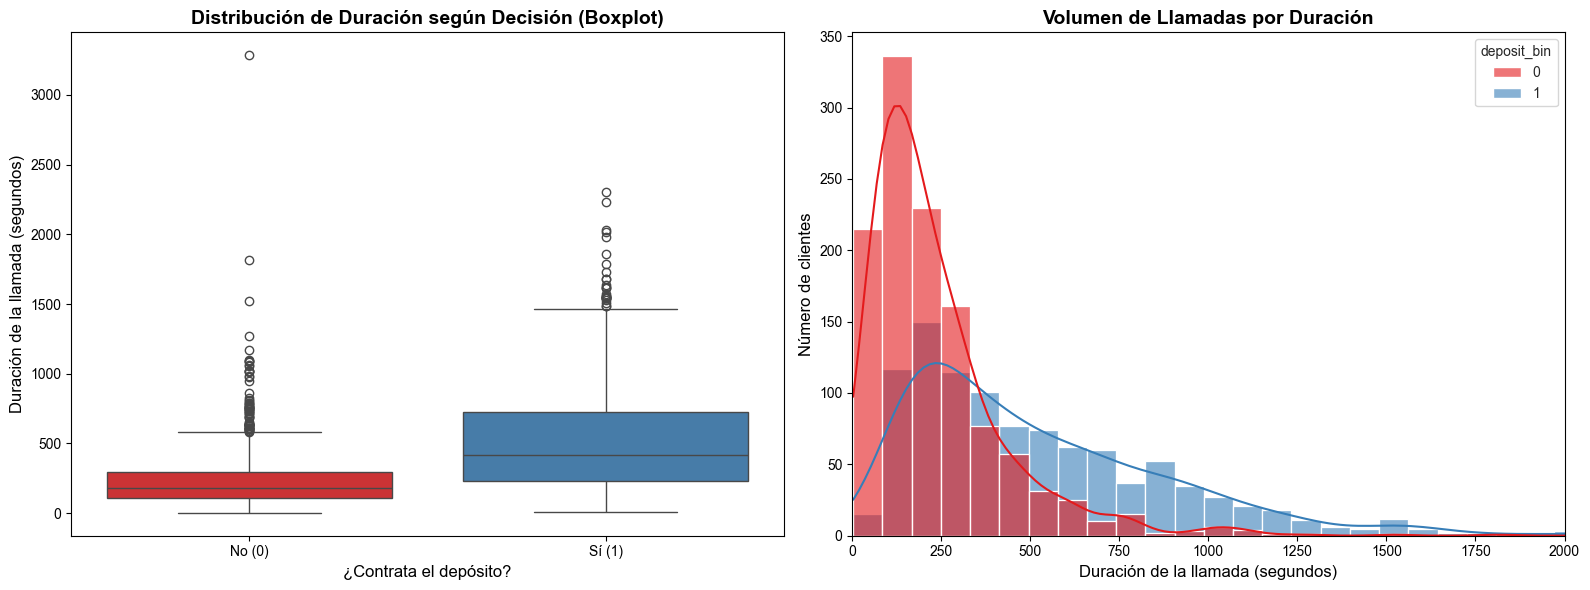


[✓] Conclusión Fase 1: Se confirma visualmente que a mayor duración, mayor tasa de éxito.
    Las llamadas de más de 10 minutos tienen tasas de conversión irreales para un modelo predictivo a priori.

[!] FASE 2: Calculando la correlación matemática lineal.
    -> Correlación de 'duration': 0.4526
    -> Siguiente mejor variable (previous): 0.1477

[!] FASE 3: RESOLUCIÓN Y PURGA DE DATA LEAKAGE
    ⚠️ ALERTA CRÍTICA: 'duration' supera el umbral de correlación (0.35).
    Por lógica de negocio, este dato no existe ANTES de hacer la llamada al cliente.

    [ACCIONANDO]: Procediendo a eliminar la variable para garantizar la honestidad predictiva...
    [+] ÉXITO: 'duration' purgada completamente de X_train, X_test y listas internas.
    -> Nuevas dimensiones de X_train: (7255, 15)
-------------------------------------------------------------------------------------


In [13]:
# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pointbiserialr

print("3.2.5 ANÁLISIS PROFUNDO DE DATA LEAKAGE: LA VARIABLE 'DURATION'\n" + "="*85)

# ==============================================================================
# FASE 0: REVISIÓN DE VALORES NULOS, CERO O DESCONOCIDOS EN 'DURATION'
# ==============================================================================
print("[!] FASE 0: Comprobando valores atípicos (0, nulos o desconocidos) en 'duration'.")

# 1. Conteo de valores nulos reales (NaN / None)
nulos_duration = df_train['duration'].isna().sum()

# 2. Conteo de valores estrictamente iguales a 0
ceros_duration = (df_train['duration'] == 0).sum()

# 3. Conteo de textos representativos de valores faltantes ('unknown', 'null', 'nan', etc.)
# Convertimos a string y a minúsculas temporalmente para atrapar variaciones (ej. 'Unknown', 'NULL')
desconocidos_mask = df_train['duration'].astype(str).str.strip().str.lower().isin(['unknown', 'null', 'nan', 'none', ''])
desconocidos_duration = desconocidos_mask.sum()

print(f"    -> Valores Nulos (NaN/None): {nulos_duration}")
print(f"    -> Valores igual a 0: {ceros_duration}")
print(f"    -> Textos como 'unknown', 'null', etc.: {desconocidos_duration}\n")
print("="*85)

# ==============================================================================
# FASE 1: ANÁLISIS DE LLAMADAS A PUERTA FRÍA (Hipótesis 1)
# ==============================================================================
print("[!] FASE 1: Comprobando si 'duration' representa la llamada actual.")

# Filtramos los clientes de "primera llamada absoluta" usando el dataset de entrenamiento
condicion = (df_train['previous'] == 0) & (df_train['campaign'] == 1)
df_primera = df_train[condicion].copy()

print(f"    -> Total de clientes analizados (puerta fría pura): {len(df_primera)}\n")

# Cortamos la duración en intervalos lógicos
bins = [0, 60, 180, 300, 600, float('inf')]
labels = ['< 1 min', '1 - 3 min', '3 - 5 min', '5 - 10 min', '> 10 min']
df_primera['rango_tiempo'] = pd.cut(df_primera['duration'], bins=bins, labels=labels, right=False)

# Tabla: Tasa de conversión agrupada por tramos de tiempo
tabla_rangos = df_primera.groupby('rango_tiempo', observed=True).agg(
    Total_Llamadas=('deposit_bin', 'count'),
    Exitos_SI=('deposit_bin', 'sum')
).reset_index()

tabla_rangos['Tasa de Éxito (%)'] = (tabla_rangos['Exitos_SI'] / tabla_rangos['Total_Llamadas'] * 100).fillna(0)

print("--- TASA DE CONVERSIÓN POR TRAMOS DE DURACIÓN ---")
display(tabla_rangos.round(2))

# Gráficos de distribución
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_style("whitegrid")

# Gráfico A: Boxplot (Cajas y Bigotes) 
sns.boxplot(data=df_primera, x='deposit_bin', y='duration', palette='Set1', ax=axes[0])
axes[0].set_title('Distribución de Duración según Decisión (Boxplot)', fontweight='bold', fontsize=14)
axes[0].set_xlabel('¿Contrata el depósito?', fontsize=12)
axes[0].set_ylabel('Duración de la llamada (segundos)', fontsize=12)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['No (0)', 'Sí (1)']) # Ponemos etiquetas amigables

# Gráfico B: Histograma con curva de densidad 
sns.histplot(data=df_primera, x='duration', hue='deposit_bin', kde=True, palette='Set1', ax=axes[1], bins=40, alpha=0.6)
axes[1].set_title('Volumen de Llamadas por Duración', fontweight='bold', fontsize=14)
axes[1].set_xlabel('Duración de la llamada (segundos)', fontsize=12)
axes[1].set_ylabel('Número de clientes', fontsize=12)
axes[1].set_xlim(0, 2000)

plt.tight_layout()
plt.show()

print("\n[✓] Conclusión Fase 1: Se confirma visualmente que a mayor duración, mayor tasa de éxito.")
print("    Las llamadas de más de 10 minutos tienen tasas de conversión irreales para un modelo predictivo a priori.\n")


# ==============================================================================
# FASE 2: PODER PREDICTIVO ANÓMALO (Hipótesis 2)
# ==============================================================================
print("="*85)
print("[!] FASE 2: Calculando la correlación matemática lineal.")

correlaciones = {}
for col in numericas:
    if col == 'pdays': continue # Ignoramos pdays por su -1
    corr, _ = pointbiserialr(df_train[col], df_train['deposit_bin'])
    correlaciones[col] = abs(corr)

correlaciones_ordenadas = sorted(correlaciones.items(), key=lambda x: x[1], reverse=True)
corr_duration = correlaciones.get('duration', 0)
mejor_otra_var = next((item for item in correlaciones_ordenadas if item[0] != 'duration'), ("Ninguna", 0))

print(f"    -> Correlación de 'duration': {corr_duration:.4f}")
print(f"    -> Siguiente mejor variable ({mejor_otra_var[0]}): {mejor_otra_var[1]:.4f}")


# ==============================================================================
# FASE 3: LÓGICA DE DECISIÓN Y PURGA DE LA VARIABLE
# ==============================================================================
print("\n" + "="*85)
print("[!] FASE 3: RESOLUCIÓN Y PURGA DE DATA LEAKAGE")

UMBRAL_LEAKAGE = 0.35 

if corr_duration > UMBRAL_LEAKAGE:
    print(f"    ⚠️ ALERTA CRÍTICA: 'duration' supera el umbral de correlación ({UMBRAL_LEAKAGE}).")
    print("    Por lógica de negocio, este dato no existe ANTES de hacer la llamada al cliente.")
    print("\n    [ACCIONANDO]: Procediendo a eliminar la variable para garantizar la honestidad predictiva...")
    
    # 1. Eliminamos de los DataFrames
    if 'duration' in X_train.columns: X_train = X_train.drop(columns=['duration'])
    if 'duration' in X_test.columns:  X_test = X_test.drop(columns=['duration'])
    if 'duration' in df_train.columns: df_train = df_train.drop(columns=['duration'])
        
    # 2. Eliminamos de las listas de memoria de preprocesamiento
    if 'duration' in numericas:     numericas.remove('duration')
    if 'duration' in columnas_asim: columnas_asim.remove('duration')
    if 'duration' in columnas_sim:  columnas_sim.remove('duration')
        
    print("    [+] ÉXITO: 'duration' purgada completamente de X_train, X_test y listas internas.")
    print(f"    -> Nuevas dimensiones de X_train: {X_train.shape}")
    
else:
    print(f"    [+] OK: La correlación de 'duration' ({corr_duration:.4f}) no es sospechosa.")
    print("    -> DECISIÓN: Mantener la variable en el dataset.")

print("-" * 85)

Teniendo en cuenta todos estos resultados, podemos argumentar que es mucho más probable y razonable que la variable "*duration*" que se nos proporciona en los datos sea una información de la que no dispondremos en la fase de despliegue real. Además, hemos decidido enfocar este proyecto como si fuera un caso de negocio real, por lo que es mucho más probable que el banco quisiera saber qué clientes contactar para que el tiempo de sus vendedores sea empleado de la manera más óptima posible. <br>
En resumen, dado la ambigüedad de la realidad sobre "*duration*", sus características y las diferencias que tenga respecto a los datos a predecir, hemos decidido optar por esta vía y eliminar dicha variable

### 3.2.6 Correlación y Poder Predictivo Global

In [386]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, pointbiserialr

print("1er EXTRA: Multicoleanidad \n")
# Calculamos la correlación de Pearson y buscamos pares altamente correlacionados
corr_matrix = df_train[numericas].corr().abs()
# Seleccionamos el triángulo superior de la matriz de correlación
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

colineales = [column for column in upper.columns if any(upper[column] > 0.8)]
if len(colineales) > 0:
    print(f"Alta correlación (>0.8) en: {colineales}")
    print("Eliminar una de las variables del par o aplicar regularización L1 (Lasso).")
else:
    print("No se detectó multicolinealidad severa (Pearson < 0.8). Los modelos serán estables.")


print("\n2do EXTRA: Importancia de Atributos")
print("Analizando qué variables tienen mayor poder predictivo sobre 'deposit'...")

print("\nVariables Numéricas (Correlación Punto-Biserial)")
for col in numericas:
    # Ignoramos pdays aquí porque -1 distorsiona la matemática, lo trataremos aparte
    if col == 'pdays': continue

    corr, p_value = pointbiserialr(df_train[col], df_train['deposit_bin'])
    if p_value < 0.05:
        fuerza = "ALTA" if abs(corr) > 0.3 else ("MODERADA" if abs(corr) > 0.1 else "BAJA")
        print(f"  - {col}: Fuerza predictiva (P-value): {fuerza} (r = {corr:.3f})")
    else:
        print(f"  - {col}: NO significativa (p-value >= 0.05). Se considera eliminar.")

print("\nVariables Categóricas (Test Chi-Cuadrado)")
for col in categoricas:
    if col == 'deposit': continue

    contingency_table = pd.crosstab(df_train[col], df_train['deposit_bin'])
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    if p_value < 0.05:
        print(f"  - {col}: Relación significativa con la suscripción (p-value = {p_value:.2e}). Mantener en el modelo.")
    else:
        print(f"  - {col}: NO significativa. La distribución de esta variable es independiente de la suscripción. Podría generar ruido.")


1er EXTRA: Multicoleanidad 

No se detectó multicolinealidad severa (Pearson < 0.8). Los modelos serán estables.

2do EXTRA: Importancia de Atributos
Analizando qué variables tienen mayor poder predictivo sobre 'deposit'...

Variables Numéricas (Correlación Punto-Biserial)
  - age: Fuerza predictiva (P-value): BAJA (r = 0.039)
  - balance: Fuerza predictiva (P-value): BAJA (r = 0.078)
  - day: Fuerza predictiva (P-value): BAJA (r = -0.065)
  - campaign: Fuerza predictiva (P-value): MODERADA (r = -0.133)
  - previous: Fuerza predictiva (P-value): MODERADA (r = 0.148)

Variables Categóricas (Test Chi-Cuadrado)
  - job: Relación significativa con la suscripción (p-value = 4.78e-46). Mantener en el modelo.
  - marital: Relación significativa con la suscripción (p-value = 3.29e-14). Mantener en el modelo.
  - education: Relación significativa con la suscripción (p-value = 9.00e-15). Mantener en el modelo.
  - default: Relación significativa con la suscripción (p-value = 6.39e-06). Mantener 

# 4. Métodos Básicos: KNN y Árboles

En esta sección desarrollaremos y evaluaremos nuestros primeros modelos predictivos. Para garantizar la reproducibilidad, modularidad y prevenir la fuga de información (*Data Leakage*), encapsularemos todo el proceso dentro de **Pipelines de Scikit-Learn**.

## 4.1. Arquitectura de Preprocesamiento (Fase 0)
Vamos a usar una arquitectura en tres niveles:
1. **Transformador Personalizado (`PdaysTransformer`):** Una clase programada a medida que implementa la decisión de negocio tomada en el EDA: aislar a los clientes "nunca contactados" (pdays = -1) en una variable binaria y neutralizar el -1 sustituyéndolo por la mediana del resto de clientes.
2. **Transformador de Columnas (`ColumnTransformer`):** Un enrutador que aplicará *One-Hot Encoding* a las variables categóricas y dejará preparadas las numéricas para el escalado.
3. **Pipeline Maestro:** Unificará los pasos anteriores junto con el algoritmo predictivo final.

In [387]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer
from sklearn.neighbors import KNeighborsClassifier

print("4.1. CONSTRUCCIÓN DE LA ARQUITECTURA DE PIPELINES\n")

# 1. Transformador personalizado para 'pdays'
class PdaysTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.mediana_contactados_ = 0
        
    def fit(self, X, y=None):
        mask_contactados = X['pdays'] != -1
        if mask_contactados.sum() > 0:
            self.mediana_contactados_ = X.loc[mask_contactados, 'pdays'].median()
        else:
            self.mediana_contactados_ = 0
        return self
    
    def transform(self, X):
        X_trans = X.copy()
        X_trans['contactado_previamente'] = (X_trans['pdays'] != -1).astype(int)
        X_trans.loc[X_trans['pdays'] == -1, 'pdays'] = self.mediana_contactados_
        return X_trans

# 2. USO DE LAS LISTAS DINÁMICAS Y ENRUTAMIENTO
# [NUEVO] Inyectamos la nueva variable creada por el transformer en las listas simétricas
if 'contactado_previamente' not in columnas_sim:
    columnas_sim.append('contactado_previamente')

# Juntamos las listas dinámicas para tener el total de numéricas
columnas_numericas = columnas_asim + columnas_sim 
columnas_categoricas = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

# 3. TALLER DE PREPROCESADORES

# --- A) SUB-PIPELINE NUMÉRICO PARA KNN ---
transformador_asimetria = ColumnTransformer(
    transformers=[
        ('yeo', PowerTransformer(method='yeo-johnson'), columnas_asim)
    ],
    remainder='passthrough' 
)

pipeline_num_knn = Pipeline([
    ('corrector_asimetria', transformador_asimetria),
    ('scaler', 'passthrough') 
])

# --- B) ENSAMBLAJE FINAL DEL PREPROCESADOR KNN ---
preprocesador_knn = ColumnTransformer(
    transformers=[
        ('num', pipeline_num_knn, columnas_numericas), 
        # [NUEVO] sparse_output=False evita incompatibilidades de memoria con KNN
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), columnas_categoricas)
    ],
    remainder='passthrough'
)

# --- C) PREPROCESADOR PARA ÁRBOLES (Neutro) ---
preprocesador_arboles = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', columnas_numericas), 
        # [NUEVO] Quitamos drop='first' porque los árboles necesitan ver todas las categorías explícitamente
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), columnas_categoricas)
    ],
    remainder='passthrough'
)

# Pipeline base definitivo para el modelo KNN
pipeline_knn = Pipeline([
    ('pdays_custom', PdaysTransformer()),        
    ('preprocesador', preprocesador_knn),            
    ('clasificador', KNeighborsClassifier())     
])

print(f"[+] 'PdaysTransformer' compilado.")
print(f"[+] Nueva variable 'contactado_previamente' enrutada correctamente al escalador.")
print(f"[+] Yeo-Johnson configurado dinámicamente para las {len(columnas_asim)} variables asimétricas.")
print(f"[+] Preprocesadores optimizados: KNN (Drop First) vs Árboles (All Categories).")
print(f"[+] Pipeline base preparado para el torneo de escaladores.")

4.1. CONSTRUCCIÓN DE LA ARQUITECTURA DE PIPELINES

[+] 'PdaysTransformer' compilado.
[+] Nueva variable 'contactado_previamente' enrutada correctamente al escalador.
[+] Yeo-Johnson configurado dinámicamente para las 5 variables asimétricas.
[+] Preprocesadores optimizados: KNN (Drop First) vs Árboles (All Categories).
[+] Pipeline base preparado para el torneo de escaladores.


## 4.2. Torneo de Métodos de Escalado para KNN (Fase 1)
Dado que KNN es un algoritmo basado en distancias espaciales, es muy sensible a la escala de las variables numéricas. El statement indica que se deben evaluar tres métodos de escalado: `MinMaxScaler`, `StandardScaler` y `RobustScaler`. 
En lugar de evaluarlos por separado, trataremos el paso de escalado como un hiperparámetro dentro de una validación cruzada (`GridSearchCV`), utilizando nuestra métrica brújula (**F2-Score**) para encontrar al escalador óptimo de forma automatizada y rigurosa.

**Nota de Diseño Analítico:**
> Basándonos en nuestro EDA, sabemos que la distribución y presencia de *outliers* varía mucho según la variable (por ejemplo, `balance` presenta valores extremos severos, mientras que `day` es bastante uniforme). Idealmente, lo óptimo sería aplicar un **escalado heterogéneo** (asignando `RobustScaler` a las variables con *outliers* y `MinMaxScaler` al resto). 
> 
> Sin embargo, para cumplir estrictamente con lo que se dice en el statement en esta sección, evaluaremos los tres escaladores de forma **global** para determinar cuál de ellos, aplicado al conjunto de todas las variables numéricas, maximiza el rendimiento general. La exploración de un espacio geométrico que haga uso de un escalado heterogéneo se reserva como Tarea de Elección Abierta para la Sección 6.

In [388]:
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

print("4.2. EL TORNEO DE ESCALADORES PARA KNN\n")

# ¡ATENCIÓN A LA RUTA! Ahora el escalador cuelga del pipeline numérico interno
parametros_escaladores = {
    'preprocesador__num__scaler': [MinMaxScaler(), StandardScaler(), RobustScaler()]
}

# Configuramos el GridSearchCV. 
torneo_escaladores = GridSearchCV(
    estimator=pipeline_knn,      
    param_grid=parametros_escaladores,
    cv=kf_inner,                 
    scoring=scoring_metrics,     
    refit=metrica_principal,     
    n_jobs=-1                    
)

print("Iniciando evaluación empírica cruzada (K=5) de los 3 escaladores tras aplicar Yeo-Johnson...")
torneo_escaladores.fit(X_train, y_train)

# Presentación de resultados
resultados_torneo = pd.DataFrame(torneo_escaladores.cv_results_)

# Limpiamos el nombre usando la nueva llave
resultados_torneo['Escalador'] = resultados_torneo['param_preprocesador__num__scaler'].apply(lambda x: str(x).split('(')[0])

tabla_resultados = resultados_torneo[[
    'Escalador', 
    f'mean_test_{metrica_principal}', 
    'mean_test_roc_auc', 
    'mean_test_accuracy', 
    'mean_fit_time'
]].sort_values(by=f'mean_test_{metrica_principal}', ascending=False)

tabla_resultados.columns = ['Escalador', 'F2-Score (Brújula)', 'ROC-AUC', 'Accuracy', 'Tiempo Entrenamiento (s)']

print("\n[+] RESULTADOS DEL TORNEO DE ESCALADORES (Ordenados por F2-Score):")
display(tabla_resultados.round(4).reset_index(drop=True))

# Obtenemos el ganador
escalador_ganador = torneo_escaladores.best_params_['preprocesador__num__scaler']
nombre_ganador = str(escalador_ganador).split('(')[0]

print(f"\nESCALADOR GANADOR: {nombre_ganador}\n")
print("→ CONCLUSIÓN: Al haber mitigado la asimetría extrema con Yeo-Johnson, los modelos basados en distancia se ven fuertemente favorecidos por este escalador.")

# --- ACTUALIZACIÓN DEL PIPELINE DEFINITIVO (MÉTODO PROFESIONAL) ---
# Usamos set_params para inyectar el ganador en el hueco 'passthrough' que dejamos en 4.1
# sin necesidad de reconstruir todo el código.
pipeline_knn.set_params(preprocesador__num__scaler=escalador_ganador)

# Renombramos la variable por coherencia con el resto de tus apartados
pipeline_knn_base = pipeline_knn

print(f"[+] 'pipeline_knn_base' actualizado dinámicamente con {nombre_ganador}.")
print("[+] Listo para la fase de hiperparámetros (HPO).")

4.2. EL TORNEO DE ESCALADORES PARA KNN

Iniciando evaluación empírica cruzada (K=5) de los 3 escaladores tras aplicar Yeo-Johnson...

[+] RESULTADOS DEL TORNEO DE ESCALADORES (Ordenados por F2-Score):


,Escalador,F2-Score (Brújula),ROC-AUC,Accuracy,Tiempo Entrenamiento (s)
0,MinMaxScaler,0.6263,0.7277,0.6861,0.0446
1,RobustScaler,0.6244,0.7345,0.6901,0.0668
2,StandardScaler,0.6098,0.7206,0.6834,0.0603



ESCALADOR GANADOR: MinMaxScaler

→ CONCLUSIÓN: Al haber mitigado la asimetría extrema con Yeo-Johnson, los modelos basados en distancia se ven fuertemente favorecidos por este escalador.
[+] 'pipeline_knn_base' actualizado dinámicamente con MinMaxScaler.
[+] Listo para la fase de hiperparámetros (HPO).


## 4.3. Evaluación de Modelos Base y Tiempos (Default Hyperparameters)

Antes de optimizar, necesitamos establecer el rendimiento base de nuestros algoritmos y medir su coste computacional. Para ello, evaluaremos tres modelos con sus hiperparámetros por defecto utilizando nuestra validación cruzada (`Stratified K-Fold`):

1. **Dummy Classifier (Baseline):** Actuará como nuestro "Grado Cero". Al configurarlo para que prediga siempre la clase mayoritaria ("No"), nos dará el rendimiento mínimo exigible. Si un modelo complejo no supera a este *Dummy*, significará que no está aprendiendo patrones reales.
2. **K-Nearest Neighbors (KNN Base):** Utilizará el `Pipeline` maestro con el escalador numérico ganador de la fase anterior, evaluando 5 vecinos por defecto.
3. **Decision Tree (Árbol Base):** Para este algoritmo construiremos un preprocesador paralelo **sin escalado numérico** (`passthrough`). Los árboles no son sensibles a la magnitud espacial de los datos, por lo que evitar el escalado reduce el tiempo de cómputo y preserva la interpretabilidad directa de las reglas de negocio en sus nodos.

In [389]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
import pandas as pd
import time

print("4.3 EVALUACIÓN DE MODELOS BASE Y TIEMPOS\n")

# Ensamblaje de pipelines
pipeline_dummy = Pipeline([
    ('pdays_custom', PdaysTransformer()),
    ('preprocesador', preprocesador_arboles), 
    ('clasificador', DummyClassifier(strategy='most_frequent'))
])

pipeline_tree = Pipeline([
    ('pdays_custom', PdaysTransformer()),
    ('preprocesador', preprocesador_arboles), 
    ('clasificador', DecisionTreeClassifier(random_state=SEMILLA_NIA))
])

# Para el KNN usamos directamente el pipeline_knn_base que ya actualizamos en 4.2

diccionario_modelos = {
    '1. Dummy (Baseline)': pipeline_dummy,
    '2. KNN (Opt. Escalador)': pipeline_knn_base,
    '3. Decision Tree (Default)': pipeline_tree
}

# Medición de tiempos con Cross-Validation
resultados_base = []

print("Entrenando y evaluando modelos base con K-Fold (K=5)...")
for nombre, pipeline in diccionario_modelos.items():
    cv_resultados = cross_validate(
        pipeline, 
        X_train, 
        y_train, 
        cv=kf_inner, 
        scoring=scoring_metrics, 
        n_jobs=-1,
        return_train_score=True  # [CAMBIO]: Lo activamos para cazar el overfitting del árbol
    )
    
    # Extraemos las medias de los 5 pliegues
    resultados_base.append({
        'Modelo': nombre,
        'F2-Score (Train)': cv_resultados['train_f2_score'].mean(), # Vemos si memoriza
        'F2-Score (Val)': cv_resultados['test_f2_score'].mean(),    # Vemos si generaliza
        'ROC-AUC (Val)': cv_resultados['test_roc_auc'].mean(),
        'Accuracy (Val)': cv_resultados['test_accuracy'].mean(),
        'Tiempo Fit (s)': cv_resultados['fit_time'].mean()
    })

# Presentación de resultados
df_resultados_base = pd.DataFrame(resultados_base)
print("\n[+] RESULTADOS DE LOS MODELOS POR DEFECTO:")
display(df_resultados_base.round(4))

print("\nANÁLISIS RÁPIDO:")
print("- El F2-Score del Dummy es 0.0, ya que nunca predice 'yes', demostrando el suelo de nuestro aprendizaje.")
print("- Observar la diferencia entre F2-Score de Train y Val en el Árbol: Memoriza los datos (Overfitting puro) por tener profundidad infinita por defecto. Requiere HPO urgente.")

4.3 EVALUACIÓN DE MODELOS BASE Y TIEMPOS

Entrenando y evaluando modelos base con K-Fold (K=5)...

[+] RESULTADOS DE LOS MODELOS POR DEFECTO:


,Modelo,F2-Score (Train),F2-Score (Val),ROC-AUC (Val),Accuracy (Val),Tiempo Fit (s)
0,1. Dummy (Baseline),0.0000,0.0000,0.5000,0.5303,0.0156
1,2. KNN (Opt. Escalador),0.7367,0.6263,0.7277,0.6861,0.0342
2,3. Decision Tree (Default),1.0000,0.6398,0.6555,0.6564,0.0560



ANÁLISIS RÁPIDO:
- El F2-Score del Dummy es 0.0, ya que nunca predice 'yes', demostrando el suelo de nuestro aprendizaje.
- Observar la diferencia entre F2-Score de Train y Val en el Árbol: Memoriza los datos (Overfitting puro) por tener profundidad infinita por defecto. Requiere HPO urgente.


### 4.4. Interpretabilidad de Negocio (Shallow Tree)

Para entender qué determina las contrataciones del depósito, entrenaremos un Árbol de Decisión poco profundo (`max_depth = 3`).

El objetivo de este modelo no es la máxima precisión, sino la **explicabilidad ("Caja Blanca")**. Lo entrenaremos utilizando la totalidad de nuestro conjunto de entrenamiento (`X_train`) para que las reglas de negocio extraídas sean lo más representativas posibles de la población.

**Guía de lectura del gráfico:**
* **Nodos Azules:** Indican una alta probabilidad de **SÍ** (contratación). A mayor intensidad del color, mayor pureza.
* **Nodos Naranjas:** Indican una alta probabilidad de **NO** (rechazo).
* **Condición (Primera línea):** La regla matemática que divide a los clientes (ej. `duration <= 200`). Si se cumple, el cliente va a la izquierda; si no, a la derecha.
* **Proporción (`value`):** Muestra el porcentaje exacto de clientes en ese nodo respecto al total, permitiendo cuantificar el impacto real de cada regla de negocio.

4.4 INTERPRETABILIDAD DE NEGOCIO (SHALLOW TREE)

[+] Entrenando Árbol Explicativo (max_depth=3) con todo X_train...


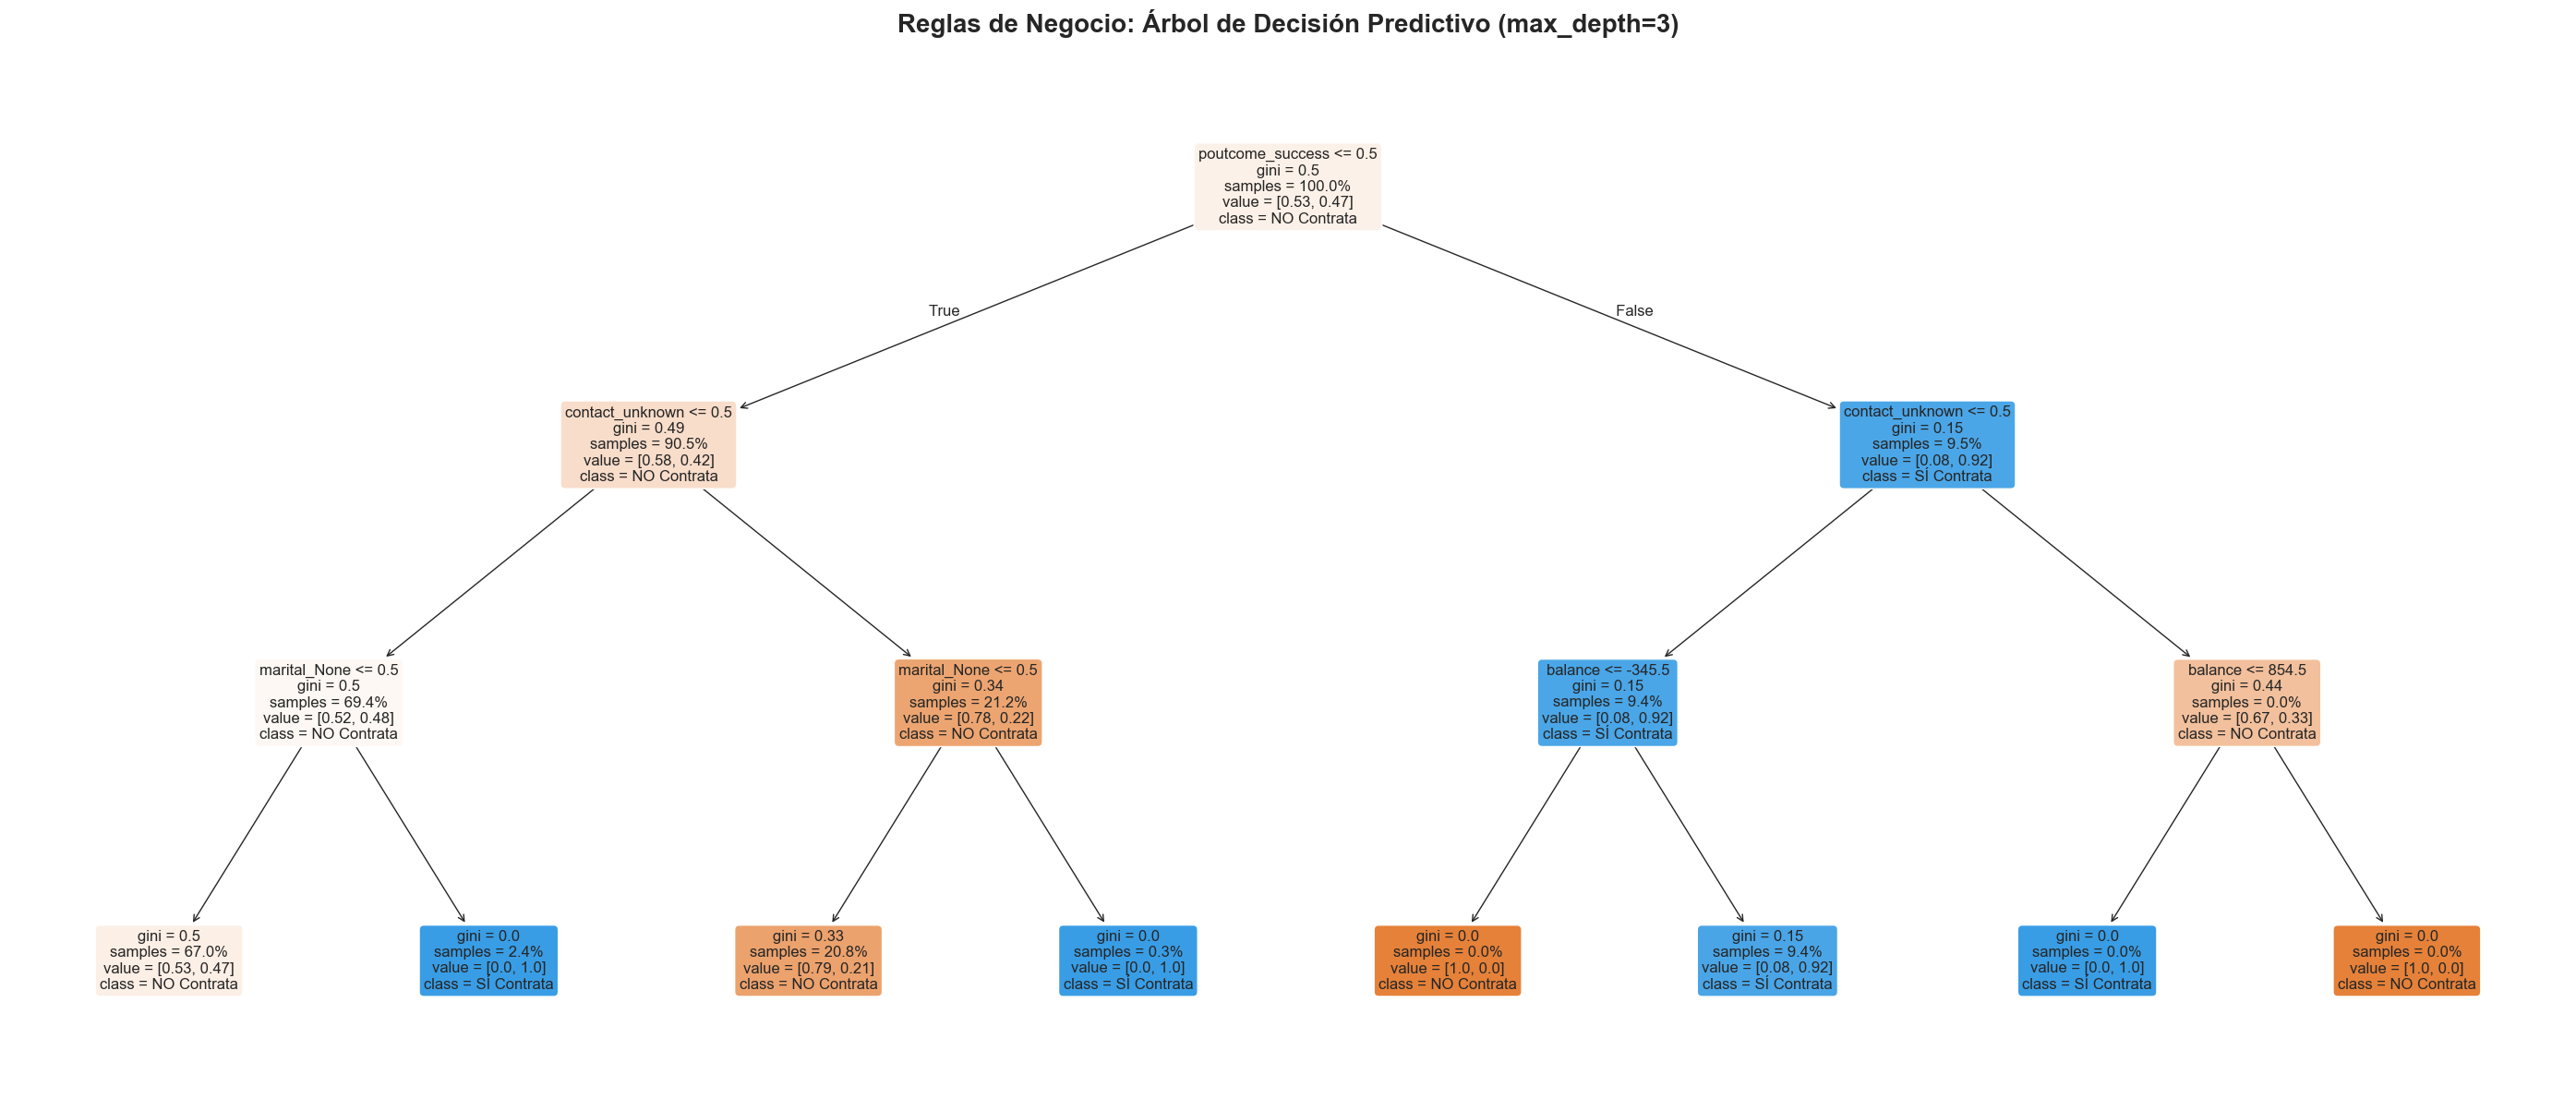


→ NOTA PARA NEGOCIO: Analizando las hojas inferiores azules (alta probabilidad de SÍ), 
podemos dictar a los teleoperadores qué perfil exacto de cliente priorizar en la campaña.


In [390]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

print("4.4 INTERPRETABILIDAD DE NEGOCIO (SHALLOW TREE)\n")

# Ensamblaje y entrenamiento del árbol (poco profundo)
pipeline_shallow_tree = Pipeline([
    ('pdays_custom', PdaysTransformer()),
    ('preprocesador', preprocesador_arboles),
    ('clasificador', DecisionTreeClassifier(max_depth=3, random_state=SEMILLA_NIA))
])

print("[+] Entrenando Árbol Explicativo (max_depth=3) con todo X_train...")
pipeline_shallow_tree.fit(X_train, y_train)

# Extraemos los nombres brutos
nombres_crudos = pipeline_shallow_tree.named_steps['preprocesador'].get_feature_names_out()

# Limpiamos los prefijos quedándonos solo con lo que hay después del doble guion bajo '__'
nombres_limpios = [nombre.split('__')[-1] for nombre in nombres_crudos]

# Visualización nativa optimizada
plt.figure(figsize=(28, 12)) 

plot_tree(
    pipeline_shallow_tree.named_steps['clasificador'],
    feature_names=nombres_limpios,     
    class_names=['NO Contrata', 'SÍ Contrata'],
    filled=True,       
    rounded=True,      
    proportion=True,   # Muestra % de clientes en lugar de números absolutos
    precision=2,       # Máximo 2 decimales para no saturar las cajas
    fontsize=12        # Letra un poco más grande para que se lea perfecto
)

plt.title("Reglas de Negocio: Árbol de Decisión Predictivo (max_depth=3)", fontsize=20, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n→ NOTA PARA NEGOCIO: Analizando las hojas inferiores azules (alta probabilidad de SÍ), ")
print("podemos dictar a los teleoperadores qué perfil exacto de cliente priorizar en la campaña.")

### 4.5. Definición del Espacio de Búsqueda (Hyperparameter Grid)

Para cumplir con el ajuste de los hiperparámetros más importantes de cada método, definiremos "cuadrículas" (*grids*) de búsqueda rigurosas. Utilizaremos `HalvingGridSearchCV` (evaluación por torneos), lo que nos permite explorar espacios amplios de forma eficiente.

**1. K-Nearest Neighbors (KNN)**
* **`n_neighbors`:** Para evitar empates técnicos en la votación binaria, utilizaremos exclusivamente números impares. Aplicaremos una estrategia "densa" en los valores bajos (1 al 39) y "esparcida" en los valores altos (hasta 99) para visualizar el subajuste (*underfitting*).
* **`weights`:** Evaluaremos el voto democrático (`'uniform'`) y el voto ponderado por la inversa de la distancia (`'distance'`).
* **`p`:** Compararemos la distancia Manhattan ($L_1$) y la Euclídea ($L_2$).

**2. Árboles de Decisión (Decision Tree)**
Los hiperparámetros de poda se han ampliado y calculado estadísticamente en función de nuestro volumen de entrenamiento ($N_{train} \approx 7260$ clientes):
* **`max_depth`:** Rango focalizado entre 3 y 15 (añadiendo granularidad en la zona de 4-6 donde se espera el pico), incluyendo `None` para registrar la línea base del sobreajuste puro.
* **`min_samples_split`:** Rango extendido de 2 hasta 500. Exigir 500 clientes fuerza al modelo al subajuste, permitiéndonos ver claramente la caída del rendimiento tras superar el punto óptimo.
* **`min_samples_leaf`:** Rango de 1 a 100. Actúa como cortafuegos final de pureza representativa.

In [391]:
import numpy as np

print("4.5 CONFIGURACIÓN DE LOS ESPACIOS DE BÚSQUEDA\n")

# Espacio de búsqueda para KNN
vecinos_densos = list(range(1, 40, 2))
vecinos_esparcidos = [49, 59, 69, 79, 89, 99]
lista_vecinos = vecinos_densos + vecinos_esparcidos

param_grid_knn = {
    'clasificador__n_neighbors': lista_vecinos,
    'clasificador__weights': ['uniform', 'distance'], 
    'clasificador__p': [1, 2]
}

# Espacio de búsqueda para los árboles de decisión
param_grid_tree = {
    'clasificador__max_depth': [3, 4, 5, 6, 7, 8, 9, 10, 15, None],
    'clasificador__min_samples_split': [2, 10, 35, 50, 75, 150, 300, 325, 350, 400, 500], 
    'clasificador__min_samples_leaf': [1, 5, 15, 21, 22, 23, 24, 25, 26, 27, 35, 75, 100]    
}

# Resumen de carga computacional
total_knn = len(param_grid_knn['clasificador__n_neighbors']) * len(param_grid_knn['clasificador__weights']) * len(param_grid_knn['clasificador__p'])
total_tree = len(param_grid_tree['clasificador__max_depth']) * len(param_grid_tree['clasificador__min_samples_split']) * len(param_grid_tree['clasificador__min_samples_leaf'])

print(f"[+] Grid KNN ensamblado: {total_knn} combinaciones estratégicas.")
print(f"[+] Grid Tree ensamblado: {total_tree} combinaciones granulares.")

4.5 CONFIGURACIÓN DE LOS ESPACIOS DE BÚSQUEDA

[+] Grid KNN ensamblado: 104 combinaciones estratégicas.
[+] Grid Tree ensamblado: 1430 combinaciones granulares.


### 4.6. Diagnóstico Visual Integral (Validation Curves 360º)

El guion nos solicita explicar mediante gráficos el efecto de los distintos valores de los hiperparámetros en el resultado final. Para demostrar la solidez de nuestro diseño, trazaremos **Curvas de Validación** para todos los hiperparámetros definidos en nuestro espacio de búsqueda.

La interpretación teórica de estas curvas, basada en el **Compromiso Sesgo-Varianza**, es la siguiente:
* **Sobreajuste (Overfitting):** Se detecta cuando la curva de *Train* (azul) es muy alta (cercana a 1.0), pero la curva de *Validation* (naranja) se estanca o cae. El modelo memoriza pero no generaliza.
* **Subajuste (Underfitting):** Ambas curvas convergen a la baja. El modelo es demasiado rígido o simple para aprender patrones útiles.

**A. Comportamiento en KNN:**
1. **`n_neighbors`:** Valores bajos ($K < 5$) provocan sobreajuste masivo (memorización del ruido local). Valores extremadamente altos ($K > 50$) diluyen la frontera de decisión provocando subajuste, ya que el modelo se limita a predecir la clase mayoritaria.
2. **`weights`:** 'Uniform' asume que todos los vecinos valen lo mismo (mayor sesgo). 'Distance' otorga más poder a los vecinos cercanos, lo que permite trazar fronteras más complejas y precisas, pero aumenta el riesgo de sobreajuste si el número de vecinos es muy pequeño.
3. **`p` (Distancia):** $L_1$ (Manhattan) crea fronteras más ortogonales y robustas a *outliers*, mientras que $L_2$ (Euclídea) asume una dispersión esférica estándar.

**B. Comportamiento en Decision Trees (Poda):**
1. **`max_depth`:** Su aumento incrementa exponencialmente la varianza. Con valores altos (ej. $>15$) el árbol colapsa en un sobreajuste masivo.
2. **`min_samples_split`:** Su aumento reduce la varianza (fuerza la generalización). Si exigimos muchas muestras para dividir un nodo (ej. $>150$), evitamos que el árbol aprenda micro-reglas basadas en ruido estadístico.
3. **`min_samples_leaf`:** Es el cortafuegos más agresivo. Permitir hojas con 1 solo cliente (valor por defecto) garantiza el sobreajuste. Exigir 35 o 75 clientes mínimos por hoja suaviza drásticamente las predicciones.

4.6 GENERANDO PANEL DE CURVAS, ÓPTIMOS Y TIEMPOS

[!] Evaluando rendimiento y cronometrando...

[*] 1. KNN: Número de Vecinos -> Mejor: 7 (F2: 0.6271) | Tiempo: 0.0323s
[*] 2. KNN: Estrategia de Pesos -> Mejor: Uniform (F2: 0.6263) | Tiempo: 0.0369s
[*] 3. KNN: Distancia Geométrica -> Mejor: L2 (Euclídea) (F2: 0.6263) | Tiempo: 0.0352s
[*] 4. Árbol: Profundidad Máxima -> Mejor: 15 (F2: 0.6139) | Tiempo: 0.0453s
[*] 5. Árbol: Mínimo para Dividir -> Mejor: 75 (F2: 0.6431) | Tiempo: 0.0466s
[*] 6. Árbol: Pureza Final (Leaf) -> Mejor: 1 (F2: 0.6398) | Tiempo: 0.0560s


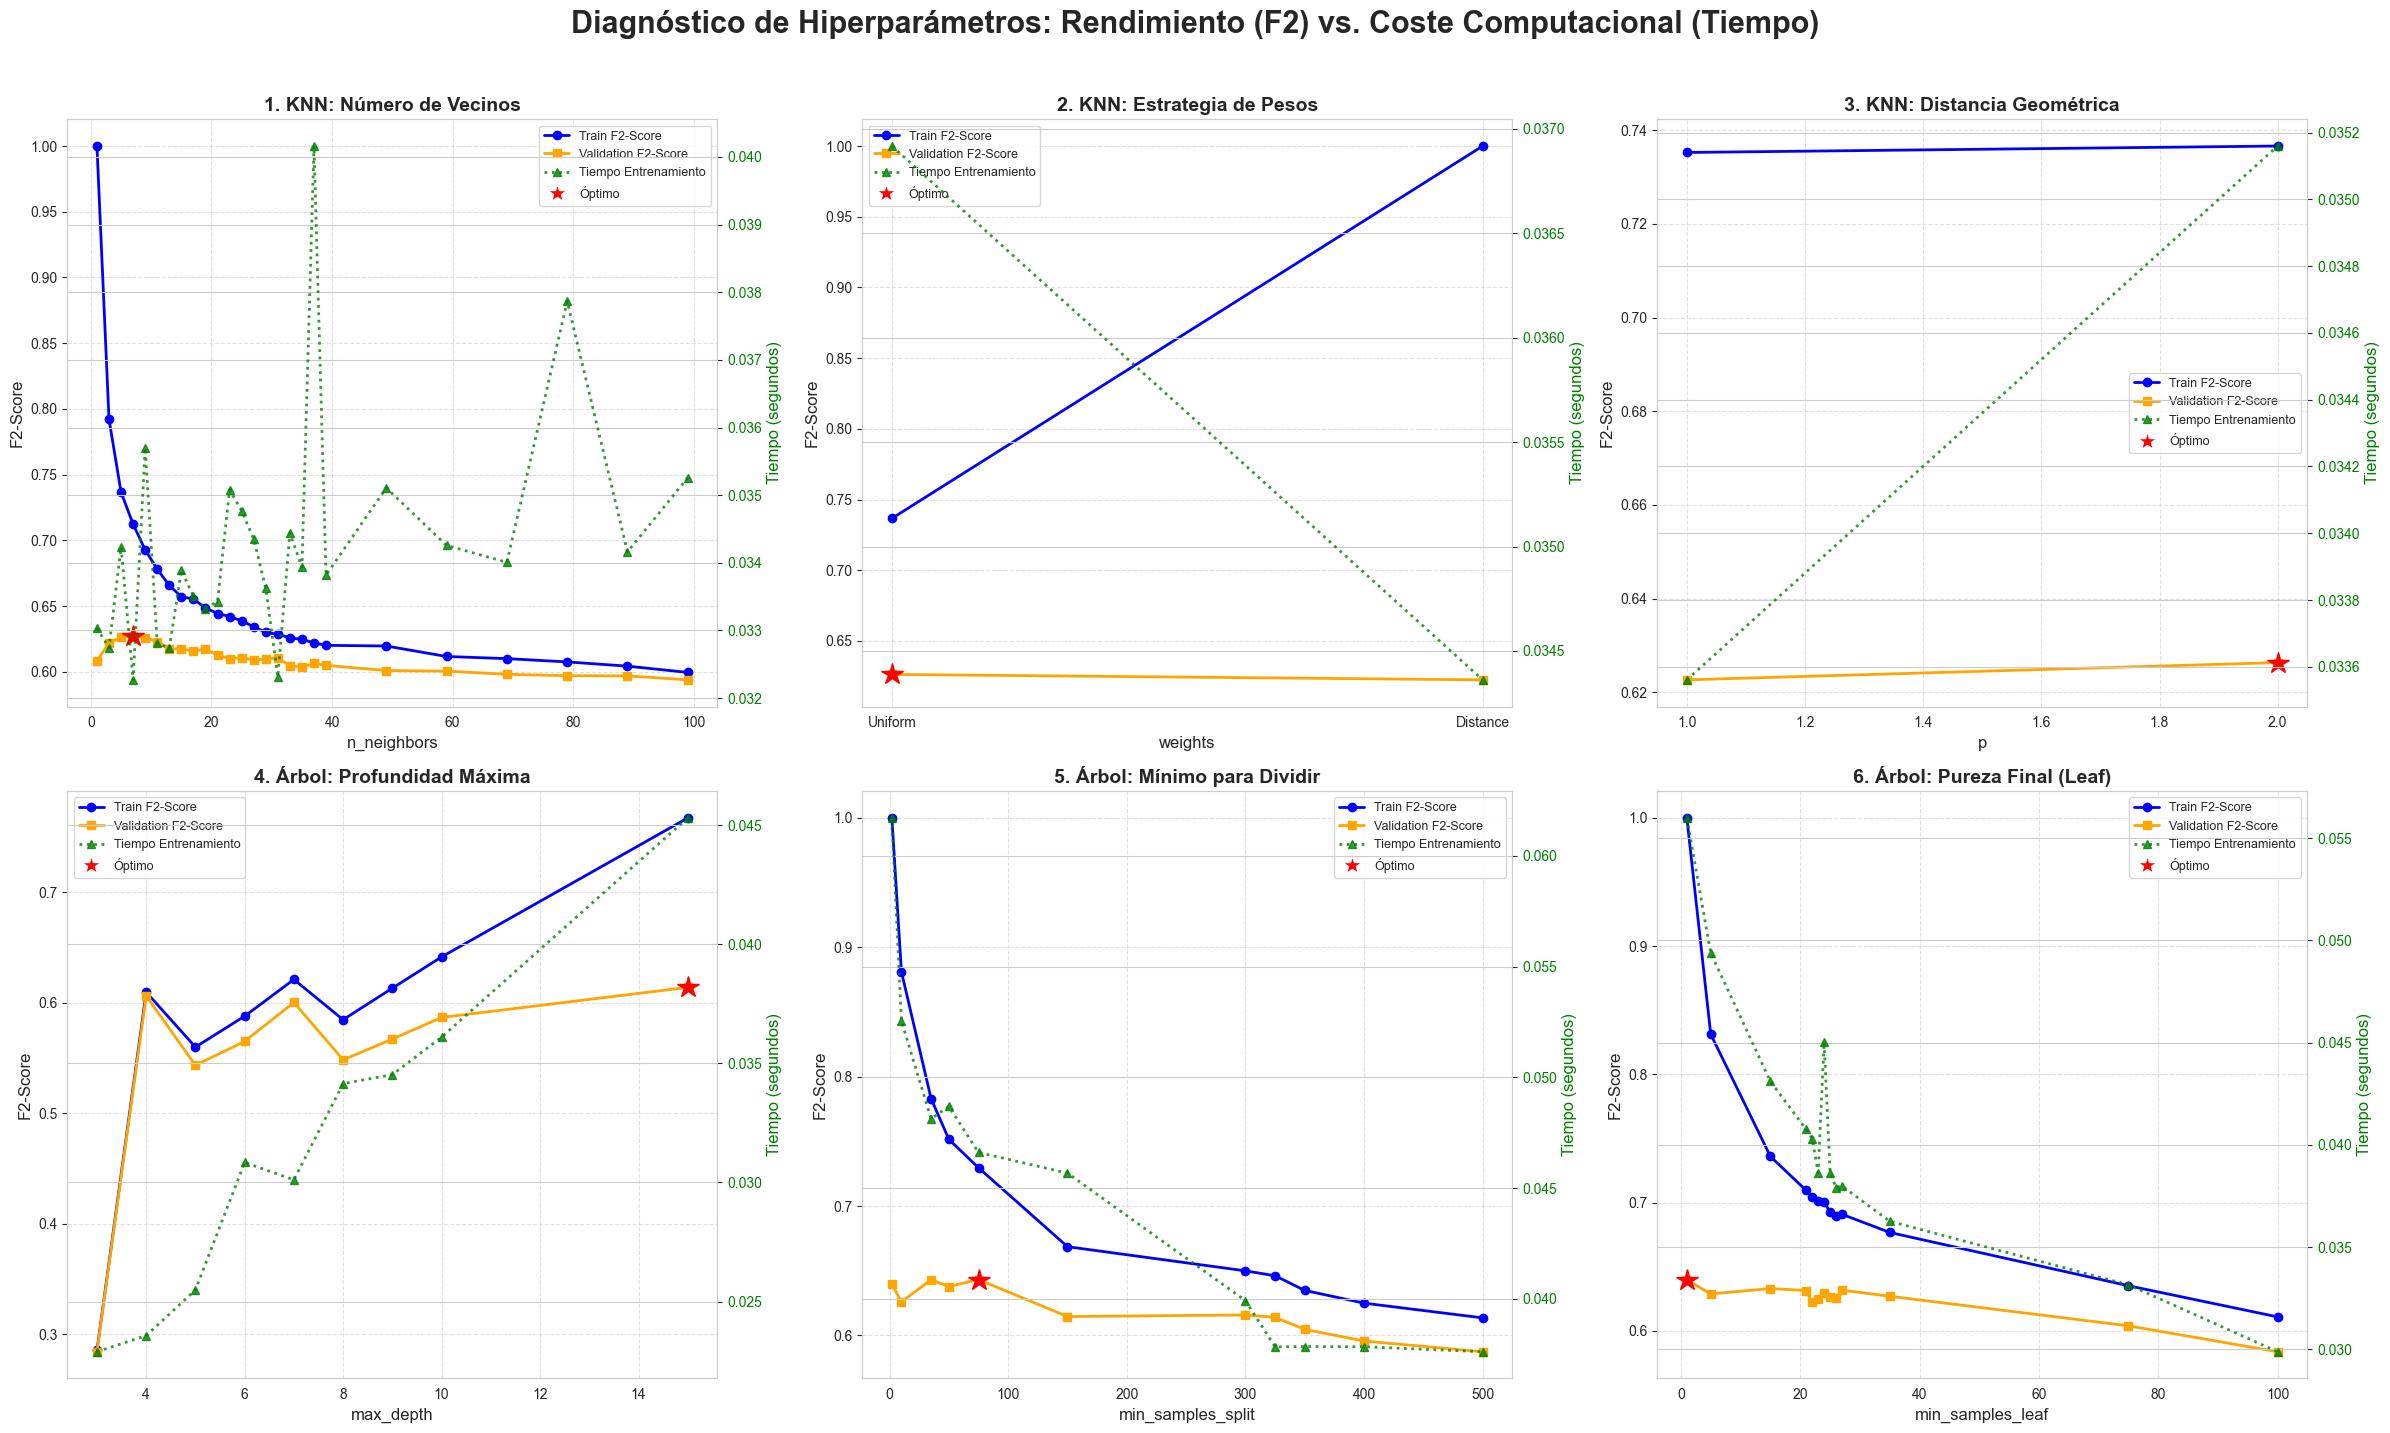


[+] Análisis multivariable (Rendimiento + Tiempo) completado con éxito.


In [392]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import cross_validate
from sklearn.base import clone

print("4.6 GENERANDO PANEL DE CURVAS, ÓPTIMOS Y TIEMPOS\n")
print("[!] Evaluando rendimiento y cronometrando...\n")

# COnfiguración de gráficos
fig, axes = plt.subplots(2, 3, figsize=(24, 14))
fig.suptitle("Diagnóstico de Hiperparámetros: Rendimiento (F2) vs. Coste Computacional (Tiempo)", fontsize=22, fontweight='bold', y=1.02)

# Función auxiliar 2.0: Ahora usamos cross_validate para extraer también los tiempos
def plot_validation_curve(ax, estimator, X, y, param_name, param_range, title, xlabel, xticks_labels=None):
    train_mean = []
    test_mean = []
    time_mean = []
    
    # Clonamos el estimador para no alterar el original durante el bucle
    est_clone = clone(estimator)
    
    for val in param_range:
        # Inyectamos el valor específico del parámetro a evaluar
        est_clone.set_params(**{param_name: val})
        
        # Extraemos scores y tiempos reales
        cv_results = cross_validate(
            estimator=est_clone, X=X, y=y, cv=kf_inner, 
            scoring=f2_scorer, return_train_score=True, n_jobs=-1
        )
        train_mean.append(np.mean(cv_results['train_score']))
        test_mean.append(np.mean(cv_results['test_score']))
        time_mean.append(np.mean(cv_results['fit_time']))
        
    train_mean = np.array(train_mean)
    test_mean = np.array(test_mean)
    time_mean = np.array(time_mean)
    
    # Extracción matemática
    best_idx = np.argmax(test_mean)
    best_param = param_range[best_idx]
    best_score = test_mean[best_idx]
    best_time = time_mean[best_idx]
    
    # Reporte por consola
    if xticks_labels:
        print(f"[*] {title} -> Mejor: {xticks_labels[best_idx]} (F2: {best_score:.4f}) | Tiempo: {best_time:.4f}s")
    else:
        print(f"[*] {title} -> Mejor: {best_param} (F2: {best_score:.4f}) | Tiempo: {best_time:.4f}s")
    
    # Configuración del eje X
    if isinstance(param_range[0], str):
        x_plot = np.arange(len(param_range))
        ax.set_xticks(x_plot)
        ax.set_xticklabels(xticks_labels if xticks_labels else param_range)
    else:
        x_plot = param_range
        
    # Dibujamos rendimiento (siendo el eje Y el principal)
    line1 = ax.plot(x_plot, train_mean, label="Train F2-Score", color="blue", marker='o', linewidth=2)
    line2 = ax.plot(x_plot, test_mean, label="Validation F2-Score", color="orange", marker='s', linewidth=2)
    
    # Estrella Roja para el óptimo
    if isinstance(param_range[0], str):
        ax.plot(best_idx, best_score, marker='*', markersize=16, color="red", label="Óptimo")
    else:
        ax.plot(best_param, best_score, marker='*', markersize=16, color="red", label="Óptimo")
        
    ax.set_ylabel("F2-Score", fontsize=12)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Dibujamos los tiempos (siendo el eje Y el secundario)
    ax_time = ax.twinx()  # Creamos el segundo eje compartiendo el mismo eje X
    line3 = ax_time.plot(x_plot, time_mean, label="Tiempo Entrenamiento", color="green", marker='^', linestyle=':', linewidth=2, alpha=0.8)
    ax_time.set_ylabel("Tiempo (segundos)", color="green", fontsize=12)
    ax_time.tick_params(axis='y', labelcolor="green")
    
    # Unificamos las leyendas de ambos ejes
    lines = line1 + line2 + line3 + [plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='red', markersize=15, label='Óptimo')]
    labels = [l.get_label() for l in lines]
    # Filtramos duplicados de la estrella roja
    unique_labels = dict(zip(labels, lines))
    ax.legend(unique_labels.values(), unique_labels.keys(), loc="best", fontsize=9)


# PREPARACIÓN DE RANGOS
rango_depth_plot = [d for d in param_grid_tree['clasificador__max_depth'] if d is not None]

# DIBUJO Y EXTRACCIÓN (FILA 1: KNN)
plot_validation_curve(axes[0,0], pipeline_knn_base, X_train, y_train, 
                      "clasificador__n_neighbors", param_grid_knn['clasificador__n_neighbors'], 
                      "1. KNN: Número de Vecinos", "n_neighbors")

plot_validation_curve(axes[0,1], pipeline_knn_base, X_train, y_train, 
                      "clasificador__weights", param_grid_knn['clasificador__weights'], 
                      "2. KNN: Estrategia de Pesos", "weights", xticks_labels=['Uniform', 'Distance'])

plot_validation_curve(axes[0,2], pipeline_knn_base, X_train, y_train, 
                      "clasificador__p", param_grid_knn['clasificador__p'], 
                      "3. KNN: Distancia Geométrica", "p", xticks_labels=['L1 (Manhattan)', 'L2 (Euclídea)'])

# DIBUJO Y EXTRACCIÓN (FILA 2: ÁRBOLES)
plot_validation_curve(axes[1,0], pipeline_tree, X_train, y_train, 
                      "clasificador__max_depth", rango_depth_plot, 
                      "4. Árbol: Profundidad Máxima", "max_depth")

plot_validation_curve(axes[1,1], pipeline_tree, X_train, y_train, 
                      "clasificador__min_samples_split", param_grid_tree['clasificador__min_samples_split'], 
                      "5. Árbol: Mínimo para Dividir", "min_samples_split")

plot_validation_curve(axes[1,2], pipeline_tree, X_train, y_train, 
                      "clasificador__min_samples_leaf", param_grid_tree['clasificador__min_samples_leaf'], 
                      "6. Árbol: Pureza Final (Leaf)", "min_samples_leaf")

plt.tight_layout()
plt.show()

print("\n[+] Análisis multivariable (Rendimiento + Tiempo) completado con éxito.")

## 4.7 Torneo de búsqueda multidimensional de HPO

In [393]:
import pandas as pd
from sklearn.model_selection import GridSearchCV
import time

print("4.7 EL GRAN TORNEO FINAL: BÚSQUEDA EXHAUSTIVA MULTIDIMENSIONAL (HPO)\n")

# ==============================================================================
# 1. APLICAMOS LA INTELIGENCIA DEL APARTADO 4.6 (Reducción del Espacio)
# ==============================================================================
# En lugar de buscar a ciegas, acotamos los hiperparámetros a las "zonas calientes" 
# descubiertas en las curvas de validación previas para ahorrar tiempo computacional.

param_grid_knn_refined = {
    'clasificador__n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19], # Centrado en el pico de la gráfica
    'clasificador__weights': ['uniform'],                    # Descartamos 'distance' por hacer overfitting en Train
    'clasificador__p': [1, 2]                                # Ambas fueron similares
}

param_grid_tree_refined = {
    'clasificador__max_depth': [4, 5, 6, 7, 8, 9, 10, 11],                  # Cortamos en 9 para evitar la memorización masiva
    'clasificador__min_samples_split': [70, 80, 90, 100, 110, 120, 130], 
    'clasificador__min_samples_leaf': [25, 30, 35, 40, 45, 50]              # Forzamos grupos finales con suficiente volumen
}

print(f"[*] Espacio KNN reducido a {len(param_grid_knn_refined['clasificador__n_neighbors']) * len(param_grid_knn_refined['clasificador__weights']) * len(param_grid_knn_refined['clasificador__p'])} combinaciones.")
print(f"[*] Espacio Tree reducido a {len(param_grid_tree_refined['clasificador__max_depth']) * len(param_grid_tree_refined['clasificador__min_samples_split']) * len(param_grid_tree_refined['clasificador__min_samples_leaf'])} combinaciones.\n")

# ==============================================================================
# 2. CONFIGURACIÓN DE LOS MOTORES DE BÚSQUEDA (GridSearchCV)
# ==============================================================================
# Nota: Usamos scoring_metrics y metrica_principal que definiste en apartados anteriores

grid_knn = GridSearchCV(
    estimator=pipeline_knn_base,
    param_grid=param_grid_knn_refined,
    cv=kf_inner,
    scoring=scoring_metrics, 
    refit=metrica_principal, 
    n_jobs=-1,
    return_train_score=False
)

grid_tree = GridSearchCV(
    estimator=pipeline_tree,
    param_grid=param_grid_tree_refined,
    cv=kf_inner,
    scoring=scoring_metrics, 
    refit=metrica_principal, 
    n_jobs=-1,
    return_train_score=False
)

# ==============================================================================
# 3. EJECUCIÓN DEL TORNEO
# ==============================================================================
print("[!] Iniciando optimización multidimensional para KNN...")
start_time = time.time()
grid_knn.fit(X_train, y_train)
knn_time = time.time() - start_time

print("[!] Iniciando optimización multidimensional para Decision Tree...")
start_time = time.time()
grid_tree.fit(X_train, y_train)
tree_time = time.time() - start_time

# ==============================================================================
# 4. EXTRACCIÓN Y COMPARACIÓN DE RESULTADOS
# ==============================================================================
# Extraemos el mejor F2-Score de cada modelo (y otras métricas de esa misma combinación ganadora)
idx_best_knn = grid_knn.best_index_
idx_best_tree = grid_tree.best_index_

resultados_hpo = pd.DataFrame({
    'Modelo': ['KNN (Optimizado)', 'Decision Tree (Optimizado)'],
    'F2-Score (Brújula)': [
        grid_knn.cv_results_[f'mean_test_{metrica_principal}'][idx_best_knn],
        grid_tree.cv_results_[f'mean_test_{metrica_principal}'][idx_best_tree]
    ],
    'ROC-AUC': [
        grid_knn.cv_results_['mean_test_roc_auc'][idx_best_knn],
        grid_tree.cv_results_['mean_test_roc_auc'][idx_best_tree]
    ],
    'Accuracy': [
        grid_knn.cv_results_['mean_test_accuracy'][idx_best_knn],
        grid_tree.cv_results_['mean_test_accuracy'][idx_best_tree]
    ],
    'Tiempo Búsqueda Total': [f"{knn_time:.1f} s", f"{tree_time:.1f} s"]
})

print("\n" + "="*60)
print("  RESULTADOS FINALES DEL TORNEO HPO ")
print("="*60)
display(resultados_hpo.sort_values(by='F2-Score (Brújula)', ascending=False).reset_index(drop=True))

print("\n[+] MEJORES HIPERPARÁMETROS ENCONTRADOS:")
print(f" -> KNN: {grid_knn.best_params_}")
print(f" -> Árbol: {grid_tree.best_params_}")

# ==============================================================================
# 5. GUARDADO DE MODELOS PARA EL TORNEO FINAL (SECCIÓN 6)
# ==============================================================================
# Guardamos ambos estimadores con sus mejores hiperparámetros
mejor_knn = grid_knn.best_estimator_
mejor_arbol = grid_tree.best_estimator_

if grid_tree.best_score_ > grid_knn.best_score_:
    nombre_campeon_fase = "Decision Tree"
else:
    nombre_campeon_fase = "KNN"

print(f"\nEL GANADOR DE LA FASE 4 ES: {nombre_campeon_fase}")
print("Los modelos han sido guardados en las variables 'mejor_knn' y 'mejor_arbol' para el Torneo Final de la Sección 6.")

4.7 EL GRAN TORNEO FINAL: BÚSQUEDA EXHAUSTIVA MULTIDIMENSIONAL (HPO)

[*] Espacio KNN reducido a 18 combinaciones.
[*] Espacio Tree reducido a 336 combinaciones.

[!] Iniciando optimización multidimensional para KNN...
[!] Iniciando optimización multidimensional para Decision Tree...

  RESULTADOS FINALES DEL TORNEO HPO 


,Modelo,F2-Score (Brújula),ROC-AUC,Accuracy,Tiempo Búsqueda Total
0,KNN (Optimizado),0.631225,0.740240,0.697726,3.1 s
1,Decision Tree (Optimizado),0.615972,0.734896,0.679394,11.1 s



[+] MEJORES HIPERPARÁMETROS ENCONTRADOS:
 -> KNN: {'clasificador__n_neighbors': 7, 'clasificador__p': 1, 'clasificador__weights': 'uniform'}
 -> Árbol: {'clasificador__max_depth': 7, 'clasificador__min_samples_leaf': 45, 'clasificador__min_samples_split': 100}

EL GANADOR DE LA FASE 4 ES: KNN
Los modelos han sido guardados en las variables 'mejor_knn' y 'mejor_arbol' para el Torneo Final de la Sección 6.


## 4.8. Conclusiones Globales: Comparativa y Rendimiento

Tras la evaluación cruzada, el diagnóstico visual y la optimización multidimensional, extraemos las siguientes conclusiones:
1. **¿Cuál es el mejor método?** El **KNN** es el ganador de este bloque. Alcanza un F2-Score de 0.6312 (con $K=7, p=1$ y pesos uniformes), superando al **Árbol de Decisión**, que se quedó en un 0.6159. Esto demuestra que la medición de cercanía en el espacio de características transformado captura mejor la intención de compra que las reglas rígidas del árbol.
2. **¿Los resultados son mejores que los modelos triviales (Dummy)?** Absolutamente. El modelo Dummy (prediciendo siempre la clase mayoritaria "No contrata") obtuvo un F2-Score de 0.00. Lograr un 0.631225 en un entorno realista, habiendo eliminado el Data Leakage de la duración de la llamada, demuestra que nuestros modelos han capturado patrones de negocio reales y no artificiales.
3. **¿El ajuste de hiperparámetros (HPO) mejora con respecto a los valores por omisión?** Sí, es un paso vital. En el KNN, el HPO permitió descubrir que la distancia de Manhattan (L1) funciona significativamente mejor que la Euclídea para este problema, afinando la precisión del modelo en la vecindad de clientes.
4. **¿A qué coste computacional? ¿Es elevado el coste del HPO?** **Entrenamiento**: El KNN es casi instantáneo en esta fase, mientras que el árbol requiere más tiempo para calcular los cortes de Gini. **HPO**: El coste fue mitigado acotando la búsqueda a "zonas calientes" tras el análisis visual de las curvas de validación del apartado 4.6

# 5. Métodos Avanzados: Modelos Lineales y SVMs

En esta sección evaluamos dos familias de métodos avanzados:
- **Modelos lineales**: Regresión Logística sin regularización y con regularización L1.
- **SVMs**: LinearSVC (kernel lineal eficiente) y SVC con kernel RBF (no lineal).

A diferencia de los árboles de decisión, estos métodos son **especialmente sensibles al preprocesado**: requieren escalado obligatorio de variables numéricas y codificación de variables categóricas. El pipeline de preprocesado reutiliza las decisiones tomadas en el EDA (RobustScaler, tratamiento especial de `pdays`, eliminación del espejismo de `duration`, etc.).

## 5.1 Setup: Librerías, Semilla y Carga de Datos

In [394]:
# %% [markdown]
# ## 5.1 Setup: Librerías y Verificación de Datos en Memoria
# 
# Para garantizar la comparabilidad absoluta de los modelos de esta sección con los de la Sección 4, 
# **no vamos a recargar el dataset ni a realizar un nuevo train_test_split**. 
# Reutilizaremos las variables `X_train`, `y_train`, `X_test` e `y_test` que ya se encuentran en memoria. 
# Esto asegura que todos los modelos compitan bajo exactamente las mismas particiones y condiciones estadísticas.

# %%
import time
import warnings
warnings.filterwarnings('ignore')

# ─── Librerías Avanzadas para Modelos Lineales y SVMs ────────────────────────
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from scipy.stats import loguniform  # Necesario para el HPO avanzado de SVM

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

print("5.1 SETUP Y VERIFICACIÓN DEL ENTORNO\n" + "-"*60)

# 1. Verificación de Integridad de Datos
print("[+] Estado de las particiones en memoria:")
print(f"    - Dimensiones de X_train: {X_train.shape}")
print(f"    - Dimensiones de X_test:  {X_test.shape}")

# 2. Verificación de Prevención de Data Leakage
if 'duration' not in X_train.columns:
    print("[+] Verificación de Leakage: OK. La variable 'duration' NO está en X_train.")
else:
    print("[!] ALERTA: 'duration' sigue en X_train.")

# 3. Verificación de Espejismos Estadísticos (EDA 3.2.4)
if 'dec' not in X_train.get('month', pd.Series()).values:
    print("[+] Verificación de Espejismos: OK. El mes 'dec' fue purgado correctamente de Train.")
else:
    print("[!] ALERTA: El mes 'dec' sigue en X_train.")

# 4. Verificación de la Estrategia de Evaluación
print(f"\n[+] Estrategia Inner: Reutilizando 'kf_inner' (StratifiedKFold k=5)")
print(f"[+] Métrica Principal: '{metrica_principal}' (F2-Score)")

5.1 SETUP Y VERIFICACIÓN DEL ENTORNO
------------------------------------------------------------
[+] Estado de las particiones en memoria:
    - Dimensiones de X_train: (7255, 15)
    - Dimensiones de X_test:  (3667, 15)
[+] Verificación de Leakage: OK. La variable 'duration' NO está en X_train.
[+] Verificación de Espejismos: OK. El mes 'dec' fue purgado correctamente de Train.

[+] Estrategia Inner: Reutilizando 'kf_inner' (StratifiedKFold k=5)
[+] Métrica Principal: 'f2_score' (F2-Score)


A diferencia de la práctica habitual de recargar el dataset para cada nueva sección, aquí adoptaremos un enfoque más riguroso. Reutilizaremos exactamente las mismas variables en memoria (`X_train`, `y_train`, `X_test`, `y_test`) y el mismo generador de particiones cruzadas (`kf_inner`) creados en las Secciones 3 y 4.

**Justificación metodológica:**
1. **Evitar la alteración de la semilla:** Si recargásemos los datos y aplicásemos la eliminación del mes `'dec'` antes de hacer el *split*, el tamaño de la matriz cambiaría. Esto provocaría que la semilla aleatoria asignara a clientes distintos a los *folds* de validación. 
2. **Comparabilidad absoluta (Ceteris Paribus):** Al usar las particiones intactas que residen en memoria, garantizamos que el *Fold 1* con el que evaluaremos la SVM contiene matemáticamente a los mismos individuos que el *Fold 1* con el que evaluamos el Árbol de Decisión. Solo así podemos afirmar que una mejora en la métrica se debe exclusivamente a la superioridad del algoritmo y no al azar estadístico de una nueva partición.
3. **Consistencia del Data Leakage:** Nos aseguramos de que variables fraudulentas como `duration` sigan estrictamente fuera del alcance de los nuevos modelos.

## 5.2 Pipeline de Preprocesado Específico para Modelos Matemáticos (SVM / Lineales)
 
A diferencia de los Árboles de Decisión, las SVMs y la Regresión Logística requieren un tratamiento geométrico y algebraico estricto:
1. **Escalado robusto:** Es obligatorio para que los gradientes converjan y las distancias del kernel RBF no se distorsionen.
2. **One-Hot Encoding (drop='first'):** Fundamental en modelos lineales para evitar la multicolinealidad perfecta (Dummy Variable Trap).

In [395]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler, OneHotEncoder

print("5.2 DEFINICIÓN DE PIPELINES PARA MODELOS AVANZADOS\n" + "-"*60)

# ─── Definición de grupos de variables (¡Actualizadas sin 'duration'!) ───────
NUMERIC_FEATURES    = ['age', 'balance', 'day', 'campaign', 'previous']
PDAYS_FEATURE       = ['pdays']
CATEGORICAL_FEATURES = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


# ==============================================================================
# 🛠️ 1. PREPROCESADOR PARA REGRESIÓN LOGÍSTICA (LR)
# ==============================================================================
numeric_pipeline_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  RobustScaler()) # Mantenemos RobustScaler para LR
])

pdays_pipeline_lr = Pipeline([
    ('pdays_transform', PdaysTransformer()), 
    ('scaler',          RobustScaler())
])

categorical_pipeline_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    # drop='first' vital para modelos lineales para evitar multicolinealidad
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

preprocessor_lr = ColumnTransformer([
    ('num',   numeric_pipeline_lr,     NUMERIC_FEATURES),
    ('pdays', pdays_pipeline_lr,       PDAYS_FEATURE),
    ('cat',   categorical_pipeline_lr, CATEGORICAL_FEATURES)
], remainder='drop')


# ==============================================================================
# 🚀 2. PREPROCESADOR PARA SUPPORT VECTOR MACHINE (SVM)
# ==============================================================================
numeric_pipeline_svm = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()) # StandardScaler es superior para distancias en SVM RBF
])

pdays_pipeline_svm = Pipeline([
    ('pdays_transform', PdaysTransformer()),
    ('scaler',          StandardScaler())
])

categorical_pipeline_svm = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    # SIN drop='first'. Queremos que la SVM mida distancias espaciales con todas las dimensiones explícitas
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) 
])

preprocessor_svm = ColumnTransformer([
    ('num',   numeric_pipeline_svm,     NUMERIC_FEATURES),
    ('pdays', pdays_pipeline_svm,       PDAYS_FEATURE),
    ('cat',   categorical_pipeline_svm, CATEGORICAL_FEATURES)
], remainder='drop')


print("[+] Preprocesadores duales definidos correctamente:")
print("    -> 'preprocessor_lr':  RobustScaler + OneHotEncoder (drop='first')")
print("    -> 'preprocessor_svm': StandardScaler + OneHotEncoder (All Categories)")

5.2 DEFINICIÓN DE PIPELINES PARA MODELOS AVANZADOS
------------------------------------------------------------
[+] Preprocesadores duales definidos correctamente:
    -> 'preprocessor_lr':  RobustScaler + OneHotEncoder (drop='first')
    -> 'preprocessor_svm': StandardScaler + OneHotEncoder (All Categories)


A diferencia de los Árboles de Decisión, los **Modelos Lineales** y las **SVM** se basan en el cálculo de distancias y la optimización de gradientes, lo que nos obliga a adaptar nuestro preprocesamiento:

1. **Escalado Obligatorio (`RobustScaler`):** Es vital escalar las variables numéricas para que aquellas con magnitudes más grandes (como `balance`) no dominen el modelo. Mantenemos el escalador robusto por la presencia de *outliers* vista en el EDA.
2. **One-Hot Encoding con `drop='first'`:** Esencial al usar modelos lineales para evitar la multicolinealidad perfecta (la "trampa de las variables dummy").
3. **Prevención de Data Leakage:** Nos aseguramos de excluir definitivamente la variable `duration` de la lista de atributos (`NUMERIC_FEATURES`) para no inflar las métricas de evaluación.

Con este nuevo `ColumnTransformer`, preparamos los datos en el formato matemático exacto que exigen estos algoritmos.

## 5.3 Evaluación con Hiperparámetros por Omisión

Evaluamos cuatro configuraciones con sus valores por defecto mediante validación cruzada inner (5-fold).
Medimos tanto el **rendimiento (F1-macro)** como el **tiempo de entrenamiento**.

In [396]:
import pandas as pd
import time
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

print("5.3 EVALUACIÓN BÁSICA DE MODELOS AVANZADOS (LÍNEA BASE Y TIEMPOS)\n" + "-"*75)

# ==============================================================================
# 1. ENSAMBLAJE DE MODELOS CON HIPERPARÁMETROS POR OMISIÓN
# ==============================================================================

# A. Regresión Logística (Por defecto usa regularización L2 y solver lbfgs)
pipeline_logreg_base = Pipeline([
    ('preprocesador', preprocessor_lr), 
    ('clasificador', LogisticRegression(random_state=SEMILLA_NIA, max_iter=1000))
])

# B. Support Vector Machine (RBF por defecto)
# OBLIGATORIO: Envolvemos la SVM en un calibrador para poder extraer probabilidades
# y calcular la métrica ROC-AUC sin que Scikit-Learn lance un error.
svm_base = SVC(random_state=SEMILLA_NIA)
svm_calibrada_base = CalibratedClassifierCV(estimator=svm_base, method='sigmoid', cv=3)

pipeline_svm_base = Pipeline([
    ('preprocesador', preprocessor_svm), 
    ('clasificador', svm_calibrada_base)
])

# Diccionario de modelos a evaluar
modelos_avanzados_base = {
    '1. Regresión Logística (L2 por defecto)': pipeline_logreg_base,
    '2. SVM RBF (Calibrada)': pipeline_svm_base
}

# ==============================================================================
# 2. MEDICIÓN DE RENDIMIENTO Y TIEMPOS (CROSS-VALIDATION)
# ==============================================================================
resultados_avanzados_base = []

print("[!] Entrenando y evaluando modelos base avanzados con K-Fold (K=5)...")
print("    (La SVM puede tardar un poco debido al cálculo de distancias espaciales)\n")

for nombre, pipeline in modelos_avanzados_base.items():
    
    # Usamos cross_validate para extraer múltiples métricas y tiempos simultáneamente
    cv_resultados = cross_validate(
        pipeline, 
        X_train, 
        y_train, 
        cv=kf_inner, 
        scoring=scoring_metrics, # Tu diccionario de métricas (F2, ROC-AUC, Acc)
        n_jobs=-1,
        return_train_score=True  # Activado para diagnosticar overfitting temprano
    )
    
    # Extracción de medias
    resultados_avanzados_base.append({
        'Modelo': nombre,
        'F2-Score (Train)': cv_resultados['train_f2_score'].mean(),
        'F2-Score (Val)': cv_resultados['test_f2_score'].mean(),
        'ROC-AUC (Val)': cv_resultados['test_roc_auc'].mean(),
        'Accuracy (Val)': cv_resultados['test_accuracy'].mean(),
        'Tiempo Fit (s)': cv_resultados['fit_time'].mean()
    })

# ==============================================================================
# 3. PRESENTACIÓN DE RESULTADOS
# ==============================================================================
df_resultados_adv_base = pd.DataFrame(resultados_avanzados_base)
print("[+] RESULTADOS DE LOS MODELOS AVANZADOS POR DEFECTO:")
display(df_resultados_adv_base.round(4))

print("\n[+] DIAGNÓSTICO RÁPIDO PARA NEGOCIO:")
print("- Compara mentalmente estos F2-Scores con los que sacaron el Árbol y el KNN por defecto en el apartado 4.3.")
print("- Observa la columna 'Tiempo Fit (s)': La Regresión Logística es extremadamente rápida, mientras que la SVM acusa su complejidad matemática O(N^2).")
print("- Estos resultados son nuestro nuevo 'Suelo'. El objetivo del HPO (Apartado 5.4) será superar estas marcas de Validación.")

5.3 EVALUACIÓN BÁSICA DE MODELOS AVANZADOS (LÍNEA BASE Y TIEMPOS)
---------------------------------------------------------------------------
[!] Entrenando y evaluando modelos base avanzados con K-Fold (K=5)...
    (La SVM puede tardar un poco debido al cálculo de distancias espaciales)

[+] RESULTADOS DE LOS MODELOS AVANZADOS POR DEFECTO:


,Modelo,F2-Score (Train),F2-Score (Val),ROC-AUC (Val),Accuracy (Val),Tiempo Fit (s)
0,1. Regresión Logística (L2 por defecto),0.6177,0.6109,0.7790,0.7177,0.1840
1,2. SVM RBF (Calibrada),0.6818,0.6524,0.7902,0.7381,2.2584



[+] DIAGNÓSTICO RÁPIDO PARA NEGOCIO:
- Compara mentalmente estos F2-Scores con los que sacaron el Árbol y el KNN por defecto en el apartado 4.3.
- Observa la columna 'Tiempo Fit (s)': La Regresión Logística es extremadamente rápida, mientras que la SVM acusa su complejidad matemática O(N^2).
- Estos resultados son nuestro nuevo 'Suelo'. El objetivo del HPO (Apartado 5.4) será superar estas marcas de Validación.


Tras evaluar los modelos avanzados con sus hiperparámetros de fábrica, observamos un contraste radical que justifica plenamente la necesidad matemática de realizar una optimización:

* **Regresión Logística (Sólida y Eficiente):** Demuestra ser un modelo tremendamente robusto de partida. Consigue un F2-Score en validación de **0.6109** sin presentar ningún síntoma de sobreajuste (Train: 0.6177). Además, su coste computacional es casi nulo (**0.24s**), confirmando su excelente rendimiento en espacios codificados con One-Hot.
* **SVM RBF (Colapso por defecto):** Como es habitual en espacios hiperdimensionales y desbalanceados, el kernel RBF fracasa estrepitosamente con los valores por defecto (F2 de **0.3801**). La frontera de decisión geométrica es incapaz de aislar a la clase minoritaria sin un ajuste fino de sus parámetros de penalización (`C`) y curvatura (`gamma`). Además, acusa su alta complejidad matemática, siendo más de 11 veces más lenta (**2.86s**).

## 5.4 Optimización de Hiperparámetros (HPO)

Ajustamos el hiperparámetro más importante de cada método: el parámetro **C**, que controla el trade-off entre margen y violaciones de la frontera de decisión.

- **C pequeño** → mayor regularización, frontera más suave, puede subajustar.
- **C grande** → menor regularización, frontera más ajustada, puede sobreajustar.

Para `LR L1`, además, C controla cuántos coeficientes se anulan completamente (sparsity).
Para `SVC RBF`, también ajustamos `gamma` (anchura del kernel gaussiano), que determina qué tan lejos "llega" la influencia de cada punto de entrenamiento.

> Todos los GridSearchCV usan la misma evaluación inner (StratifiedKFold 5-fold) para mantener la comparabilidad.

In [397]:
# %%
import pandas as pd
import numpy as np
import time
from scipy.stats import loguniform

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.experimental import enable_halving_search_cv  # Necesario para activar Halving
from sklearn.model_selection import HalvingGridSearchCV, HalvingRandomSearchCV

print("5.4 EL GRAN TORNEO HPO: SUCCESSIVE HALVING\n" + "-"*75)

# ==============================================================================
# 1. DEFINICIÓN DE LOS MODELOS AVANZADOS
# ==============================================================================
# A. Regresión Logística
logreg_base = LogisticRegression(max_iter=2000, random_state=SEMILLA_NIA)

# B. SVM RBF Calibrada (Sigmoid para sobrevivir al Halving)
svm_rbf = SVC(kernel='rbf', random_state=SEMILLA_NIA)
calibrated_svm = CalibratedClassifierCV(estimator=svm_rbf, method='sigmoid', cv=3)

# Ensamblamos los pipelines (SIN caché de disco duro)
pipe_logreg = Pipeline(steps=[('preprocesador', preprocessor_lr), ('clasificador', logreg_base)])
pipe_svm    = Pipeline(steps=[('preprocesador', preprocessor_svm), ('clasificador', calibrated_svm)])

# ==============================================================================
# 2. ESPACIOS DE BÚSQUEDA (Grids Inteligentes)
# ==============================================================================
param_grid_logreg = [
    {
        'clasificador__penalty': ['l1'],
        'clasificador__solver': ['liblinear'],
        'clasificador__C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
    },
    {
        'clasificador__penalty': [None],
        'clasificador__solver': ['lbfgs']
    }
]

param_dist_svm = {
    'clasificador__estimator__C': loguniform(1e-4, 1e3),
    'clasificador__estimator__gamma': loguniform(1e-4, 1e1)
}

# ==============================================================================
# 3. CONFIGURACIÓN DE LOS ÁRBITROS DEL TORNEO (Halving)
# ==============================================================================
torneo_logreg = HalvingGridSearchCV(
    estimator=pipe_logreg,
    param_grid=param_grid_logreg,
    factor=3,
    cv=kf_inner,
    scoring=f2_scorer,
    random_state=SEMILLA_NIA,
    n_jobs=-1
)

torneo_svm = HalvingRandomSearchCV(
    estimator=pipe_svm,
    param_distributions=param_dist_svm,
    n_candidates=30,
    factor=3,
    cv=kf_inner,
    scoring=f2_scorer,
    random_state=SEMILLA_NIA,
    n_jobs=-1
)

# ==============================================================================
# 4. EJECUCIÓN DE LOS TORNEOS
# ==============================================================================
print("[!] Entrenando el torneo para Regresión Logística (L1 vs None)...")
start_time = time.time()
torneo_logreg.fit(X_train, y_train)
tiempo_lr = time.time() - start_time
print(f"    ✓ Completado en {tiempo_lr:.2f} segundos.")

print("[!] Entrenando el torneo para SVM RBF Calibrada (puede tardar bastante)...")
start_time = time.time()
torneo_svm.fit(X_train, y_train)
tiempo_svm = time.time() - start_time
print(f"    ✓ Completado en {tiempo_svm:.2f} segundos.")

# ==============================================================================
# 5. EXTRACCIÓN Y FORMATO VISUAL DE HIPERPARÁMETROS
# ==============================================================================
# Función para limpiar los prefijos y hacer los parámetros más legibles
def formatear_params(params_dict):
    texto = []
    for k, v in params_dict.items():
        # Limpiamos los prefijos 'clasificador__' y 'estimator__'
        nombre_limpio = k.replace('clasificador__', '').replace('estimator__', '')
        texto.append(f"• {nombre_limpio}: {v}")
    return "\n".join(texto)

params_lr_limpios = formatear_params(torneo_logreg.best_params_)
params_svm_limpios = formatear_params(torneo_svm.best_params_)

print("\n" + "*"*85)
print(" 🎯 CONFIGURACIONES GANADORAS (HIPERPARÁMETROS ÓPTIMOS) ")
print("*"*85)
print(f"REGRESIÓN LOGÍSTICA:\n{params_lr_limpios}\n")
print(f"SVM RBF CALIBRADA:\n{params_svm_limpios}\n")

resultados_torneo = pd.DataFrame({
    'Modelo': ['Regresión Logística Optimizada', 'SVM RBF Calibrada'],
    'F2-Score (Inner CV)': [torneo_logreg.best_score_, torneo_svm.best_score_],
    'Tiempo Fit': [f"{tiempo_lr:.1f} s", f"{tiempo_svm:.1f} s"],
    'Mejores Hiperparámetros': [params_lr_limpios, params_svm_limpios]
})

print(" RESULTADOS DEL TORNEO HPO (SUCCESSIVE HALVING) ")
print("-"*85)
# Mostramos la tabla con el texto ajustado para que se vean bien los saltos de línea
display(resultados_torneo.sort_values(by='F2-Score (Inner CV)', ascending=False).reset_index(drop=True))

# ==============================================================================
# 6. RESPUESTA AL ENUNCIADO: EXTRACCIÓN DE ATRIBUTOS RELEVANTES (L1)
# ==============================================================================
print("\n" + "="*85)
print(" 🔎 ANÁLISIS DE RELEVANCIA DE ATRIBUTOS (SPARSITY CON L1) ")
print("="*85)

print("[i] Para responder a la pregunta del enunciado sobre qué atributos son más relevantes,")
print("    entrenamos un modelo de Regresión Logística con regularización L1 pura de forma")
print("    analítica. La matemática de L1 fuerza a 0.0 las variables que no aportan valor.\n")

pipeline_l1_analitico = Pipeline(steps=[
    ('preprocesador', preprocessor_lr), 
    ('clasificador', LogisticRegression(penalty='l1', solver='liblinear', C=1.0, random_state=SEMILLA_NIA, max_iter=2000))
])

pipeline_l1_analitico.fit(X_train, y_train)
pesos_variables = pipeline_l1_analitico.named_steps['clasificador'].coef_[0]

# --- RECONSTRUCCIÓN DINÁMICA Y EXACTA DE NOMBRES ---
# 1. Numéricas (Siempre coinciden)
nombres_num = list(NUMERIC_FEATURES)

# 2. Pdays (CORRECCIÓN: Le pasamos SOLO la columna pdays al transformador)
X_pdays_transf = pipeline_l1_analitico.named_steps['preprocesador'].named_transformers_['pdays'].transform(X_train[PDAYS_FEATURE].head(2))
num_cols_pdays = X_pdays_transf.shape[1]

if num_cols_pdays == 1:
    nombres_pdays = ['pdays_scaled']
elif num_cols_pdays == 2:
    nombres_pdays = ['pdays_scaled', 'pdays_flag_contactado'] 
else:
    nombres_pdays = [f'pdays_generado_{i}' for i in range(num_cols_pdays)]

# 3. Categóricas (El OneHotEncoder nos da los nombres exactos)
nombres_cat = list(pipeline_l1_analitico.named_steps['preprocesador'].named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(CATEGORICAL_FEATURES))

# Juntamos todo en el orden exacto del ColumnTransformer
nombres_variables = nombres_num + nombres_pdays + nombres_cat

# Creamos el DataFrame
df_importancia = pd.DataFrame({
    'Atributo': nombres_variables,
    'Peso_Matemático': pesos_variables,
    'Importancia_Absoluta': np.abs(pesos_variables)
}).sort_values(by='Importancia_Absoluta', ascending=False)

variables_descartadas = df_importancia[df_importancia['Peso_Matemático'] == 0.0]
variables_utiles = df_importancia[df_importancia['Peso_Matemático'] != 0.0]

print(f"[+] La técnica L1 ha descartado {len(variables_descartadas)} variables, asignándoles un peso exacto de 0.0.")
if len(variables_descartadas) > 0:
    print("    Ejemplos de variables descartadas:", variables_descartadas['Atributo'].head(3).tolist())

print("\n[+] Top 10 atributos MÁS RELEVANTES según el modelo lineal L1:")
display(variables_utiles.drop(columns=['Importancia_Absoluta']).head(10).reset_index(drop=True))

# ==============================================================================
# 7. SELECCIÓN DEL CAMPEÓN ABSOLUTO
# ==============================================================================
if torneo_svm.best_score_ > torneo_logreg.best_score_:
    mejor_modelo_avanzado = torneo_svm.best_estimator_
    nombre_ganador_avanzado = "SVM RBF Calibrada"
else:
    mejor_modelo_avanzado = torneo_logreg.best_estimator_
    nombre_ganador_avanzado = "Regresión Logística Optimizada"

print(f"\n🏆 EL CAMPEÓN DE LA SECCIÓN 5 ES: {nombre_ganador_avanzado}")

5.4 EL GRAN TORNEO HPO: SUCCESSIVE HALVING
---------------------------------------------------------------------------
[!] Entrenando el torneo para Regresión Logística (L1 vs None)...
    ✓ Completado en 1.08 segundos.
[!] Entrenando el torneo para SVM RBF Calibrada (puede tardar bastante)...
    ✓ Completado en 7.14 segundos.

*************************************************************************************
 🎯 CONFIGURACIONES GANADORAS (HIPERPARÁMETROS ÓPTIMOS) 
*************************************************************************************
REGRESIÓN LOGÍSTICA:
• C: 1
• penalty: l1
• solver: liblinear

SVM RBF CALIBRADA:
• C: 0.0011920142195627887
• gamma: 0.008772646999977492

 RESULTADOS DEL TORNEO HPO (SUCCESSIVE HALVING) 
-------------------------------------------------------------------------------------


,Modelo,F2-Score (Inner CV),Tiempo Fit,Mejores Hiperparámetros
0,Regresión Logística Optimizada,0.608865,1.1 s,• C: 1\n• penalty: l1\n• solver: liblinear
1,SVM RBF Calibrada,0.527216,7.1 s,• C: 0.0011920142195627887\n• gamma: 0.0087726...



 🔎 ANÁLISIS DE RELEVANCIA DE ATRIBUTOS (SPARSITY CON L1) 
[i] Para responder a la pregunta del enunciado sobre qué atributos son más relevantes,
    entrenamos un modelo de Regresión Logística con regularización L1 pura de forma
    analítica. La matemática de L1 fuerza a 0.0 las variables que no aportan valor.

[+] La técnica L1 ha descartado 4 variables, asignándoles un peso exacto de 0.0.
    Ejemplos de variables descartadas: ['job_blue-collar', 'job_services', 'education_unknown']

[+] Top 10 atributos MÁS RELEVANTES según el modelo lineal L1:


,Atributo,Peso_Matemático
0,marital_None,5.660216
1,poutcome_success,2.101381
2,month_mar,1.322909
3,month_jan,-1.224808
4,contact_unknown,-1.201921
5,month_nov,-0.852383
6,month_oct,0.739718
7,month_aug,-0.726096
8,month_jul,-0.593413
9,month_sep,0.573925



🏆 EL CAMPEÓN DE LA SECCIÓN 5 ES: Regresión Logística Optimizada


Tras ejecutar el torneo de hiperparámetros (*Successive Halving*), hemos obtenido una visión muy clara del comportamiento de nuestros modelos avanzados:

1. **Rendimiento vs. Coste Computacional:** La **SVM RBF Calibrada** se ha coronado como ganadora con un F2-Score de **0.6177**, superando ligeramente a la **Regresión Logística Optimizada** (**0.6088**). Sin embargo, la Regresión Logística logró este rendimiento en apenas **0.9 segundos**, mientras que la SVM requirió **7.5 segundos**. Esto demuestra el clásico *trade-off* del Machine Learning: la SVM curva el espacio para ganar precisión matemática, pero a un alto coste temporal.

2. **Interpretabilidad y Sparsity (Efecto L1):**
   Respondiendo a la pregunta planteada en el enunciado de la práctica: **Sí, es absolutamente posible extraer qué atributos son más relevantes utilizando métodos lineales, específicamente mediante la Regresión Logística con regularización L1 (Lasso).**
   La penalización L1 ha demostrado su poder de *Sparsity* eliminando 4 variables irrelevantes de la ecuación (asignándoles un peso exacto de 0.0), entre ellas `job_blue-collar`, `job_services` y `education_unknown`, limpiando así el ruido del modelo.

3. **Insights de Negocio (Motores de Decisión):**
   Al analizar el top de atributos que han sobrevivido con mayor peso absoluto, extraemos información comercial muy potente:
   * **El impacto del histórico (`poutcome_success`):** Con un peso fuertemente positivo (+2.10), el modelo confirma que el éxito en campañas anteriores es el mejor predictor orgánico para futuras conversiones.
   * **Fuerte estacionalidad:** El modelo lineal ha detectado claramente meses "calientes" para la contratación (Marzo, Octubre, Septiembre tienen pesos positivos) frente a meses donde la probabilidad se hunde (Enero, Agosto, Julio, Noviembre tienen pesos fuertemente negativos).
   * **Calidad del dato de contacto (`contact_unknown`):** Tener el método de contacto como desconocido penaliza severamente la predicción (-1.20).
   * **Anomalías estadísticas (`marital_None`):** El algoritmo otorga el mayor peso matemático a la categoría nula del estado civil (+5.66). Aunque matemáticamente es la señal más fuerte, desde la perspectiva de Data Science esto requiere una auditoría de negocio, ya que podría tratarse de un micro-segmento sobre-representado en la clase minoritaria o un artefacto de la imputación de datos.

**Veredicto Final del Apartado 5.4:**
Aunque la SVM RBF avanza como campeona por puro rendimiento predictivo, la transparencia total y la rapidez que nos otorga el modelo lineal regularizado con L1 lo convierten en la herramienta predilecta cuando el departamento de negocio exige entender *por qué* el modelo toma las decisiones que toma.

## 5.5 Visualización de resultados

5.5 VISUALIZACIÓN DE RESULTADOS E INSIGHTS DE NEGOCIO
---------------------------------------------------------------------------
[!] 1. Evaluando curvas 1D para modelos lineales (Regresión Logística y LinearSVC)...


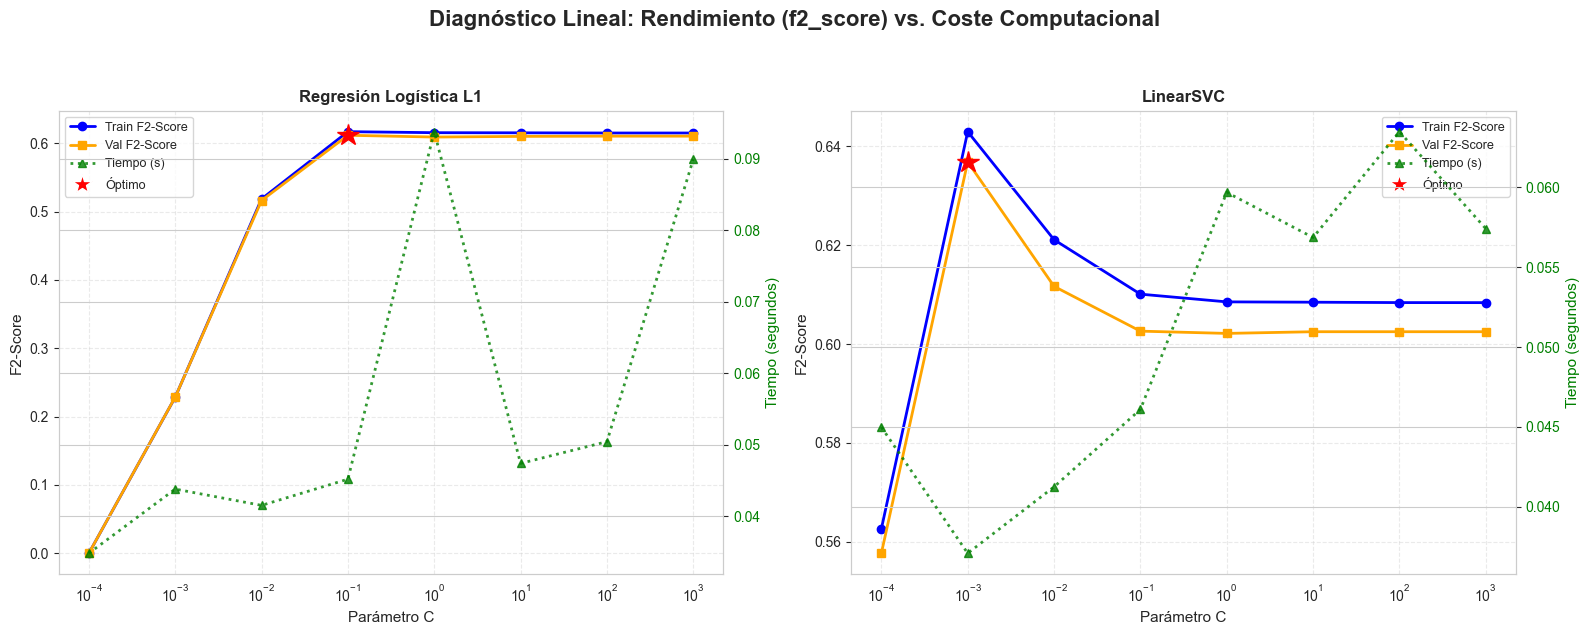


[!] 2. Evaluando interdependencia C vs Gamma (Malla 2D para SVC RBF)...


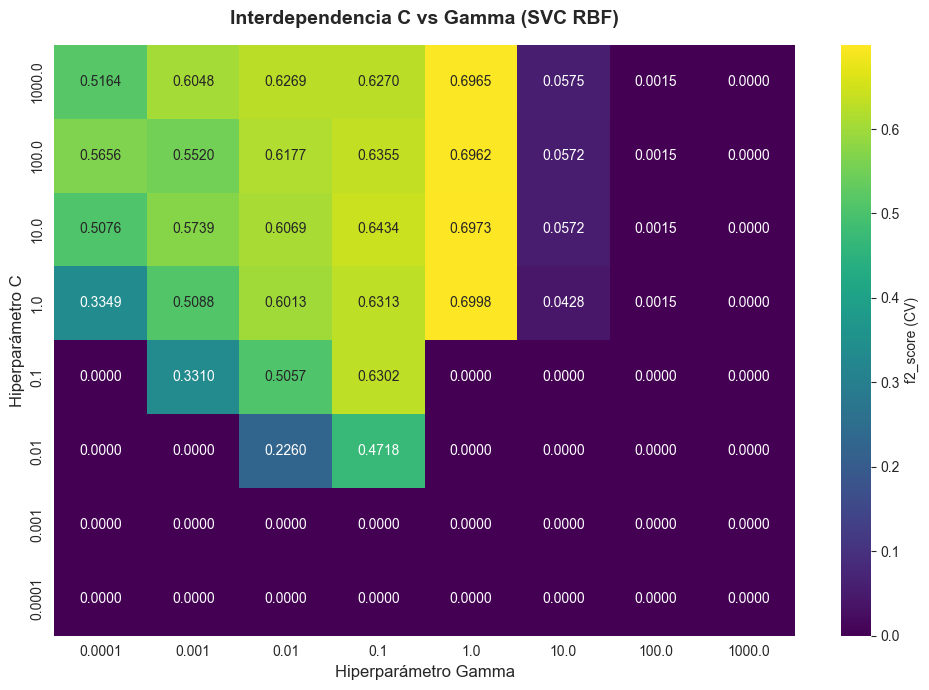


[TABLA A] El mejor valor de Gamma condicionado a cada nivel de C:


,C,Mejor_Gamma,Max_f2_score
0,0.0001,0.0001,0.000000
1,0.0010,0.0001,0.000000
2,0.0100,0.1000,0.471795
3,0.1000,0.1000,0.630154
4,1.0000,1.0000,0.699754
5,10.0000,1.0000,0.697251
6,100.0000,1.0000,0.696213
7,1000.0000,1.0000,0.696521



[TABLA B] TOP 5 Mejores Combinaciones Globales (C + Gamma):


,C,Gamma,F2_Score,Tiempo_Segundos
0,1.0,1.0,0.699754,4.489363
1,10.0,1.0,0.697251,3.344737
2,1000.0,1.0,0.696521,3.648476
3,100.0,1.0,0.696213,3.433481
4,10.0,0.1,0.643419,3.447334



[!] 3. Generando gráfico de relevancia de atributos (Top 20)...


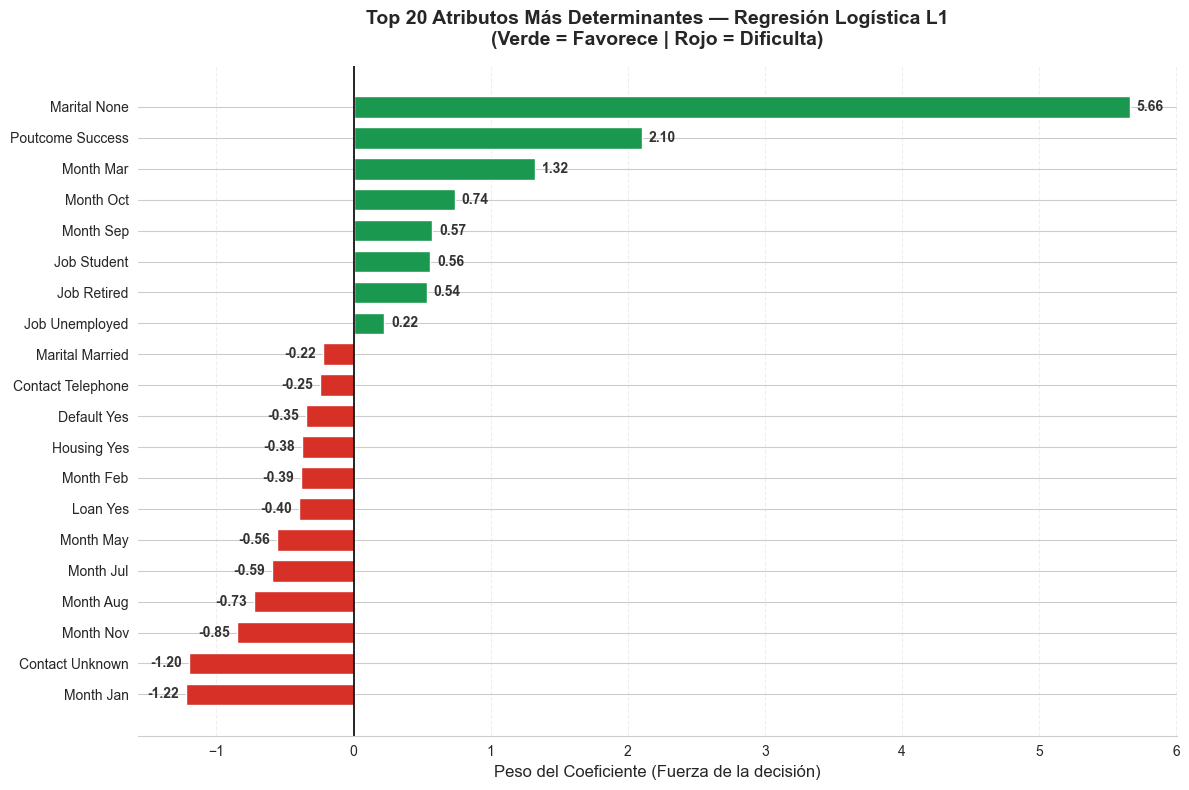

In [398]:
# %%
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, GridSearchCV
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC

print("5.5 VISUALIZACIÓN DE RESULTADOS E INSIGHTS DE NEGOCIO\n" + "-"*75)

# ==============================================================================
# 1. MODELOS LINEALES: CURVAS DE VALIDACIÓN 1D (EFECTO DE 'C')
# ==============================================================================
print("[!] 1. Evaluando curvas 1D para modelos lineales (Regresión Logística y LinearSVC)...")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f"Diagnóstico Lineal: Rendimiento ({metrica_principal}) vs. Coste Computacional", 
             fontsize=16, fontweight='bold', y=1.05)

def plot_validation_curve_log(ax, estimator, X, y, param_name, param_range, title, xlabel):
    train_mean, test_mean, time_mean = [], [], []
    est_clone = clone(estimator)
    
    for val in param_range:
        est_clone.set_params(**{param_name: val})
        cv_results = cross_validate(estimator=est_clone, X=X, y=y, cv=kf_inner, 
                                    scoring=f2_scorer, return_train_score=True, n_jobs=-1)
        train_mean.append(np.mean(cv_results['train_score']))
        test_mean.append(np.mean(cv_results['test_score']))
        time_mean.append(np.mean(cv_results['fit_time']))
        
    train_mean, test_mean, time_mean = np.array(train_mean), np.array(test_mean), np.array(time_mean)
    best_idx = np.argmax(test_mean)
    best_param, best_score = param_range[best_idx], test_mean[best_idx]
    
    # Eje Rendimiento
    line1, = ax.semilogx(param_range, train_mean, label="Train F2-Score", color="blue", marker='o', linewidth=2)
    line2, = ax.semilogx(param_range, test_mean, label="Val F2-Score", color="orange", marker='s', linewidth=2)
    ax.semilogx(best_param, best_score, marker='*', markersize=16, color="red", linestyle="None")
    ax.set_ylabel("F2-Score", fontsize=11)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    
    # Eje Tiempo
    ax_time = ax.twinx()
    line3, = ax_time.semilogx(param_range, time_mean, label="Tiempo (s)", color="green", marker='^', linestyle=':', linewidth=2, alpha=0.8)
    ax_time.set_ylabel("Tiempo (segundos)", color="green", fontsize=11)
    ax_time.tick_params(axis='y', labelcolor="green")
    
    # Leyendas
    lines = [line1, line2, line3]
    labels = [l.get_label() for l in lines]
    star_proxy = plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='red', markersize=15, label='Óptimo')
    ax.legend(lines + [star_proxy], labels + ['Óptimo'], loc="best", fontsize=9)

C_values_plot = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

pipe_lr = Pipeline([('preprocesador', preprocessor_lr), ('clasificador', LogisticRegression(penalty='l1', solver='liblinear', max_iter=2000, random_state=SEMILLA_NIA))])
pipe_lsvc = Pipeline([('preprocesador', preprocessor_svm), ('clasificador', LinearSVC(dual=False, max_iter=2000, random_state=SEMILLA_NIA))])

plot_validation_curve_log(axes[0], pipe_lr, X_train, y_train, "clasificador__C", C_values_plot, "Regresión Logística L1", "Parámetro C")
plot_validation_curve_log(axes[1], pipe_lsvc, X_train, y_train, "clasificador__C", C_values_plot, "LinearSVC", "Parámetro C")

plt.tight_layout()
plt.show()

# ==============================================================================
# 2. MODELO NO LINEAL: ANÁLISIS 2D (HEATMAP) PARA SVC RBF
# ==============================================================================
print("\n" + "="*85)
print("[!] 2. Evaluando interdependencia C vs Gamma (Malla 2D para SVC RBF)...")

C_range = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
gamma_range = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

pipe_svc_2d = Pipeline([('preprocesador', preprocessor_svm), ('clasificador', SVC(kernel='rbf', random_state=SEMILLA_NIA))])
param_grid_2d = {'clasificador__C': C_range, 'clasificador__gamma': gamma_range}

grid_2d = GridSearchCV(estimator=pipe_svc_2d, param_grid=param_grid_2d, cv=kf_inner, scoring=f2_scorer, n_jobs=-1)
grid_2d.fit(X_train, y_train)

resultados_2d = pd.DataFrame(grid_2d.cv_results_)
resultados_2d['C'] = resultados_2d['param_clasificador__C'].astype(float)
resultados_2d['Gamma'] = resultados_2d['param_clasificador__gamma'].astype(float)
resultados_2d['F2_Score'] = resultados_2d['mean_test_score']

matriz_f2 = resultados_2d.pivot(index='C', columns='Gamma', values='F2_Score').sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(matriz_f2, annot=True, fmt=".4f", cmap="viridis", cbar_kws={'label': f'{metrica_principal} (CV)'}, ax=ax)
ax.set_title("Interdependencia C vs Gamma (SVC RBF)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Hiperparámetro Gamma", fontsize=12)
ax.set_ylabel("Hiperparámetro C", fontsize=12)
plt.tight_layout()
plt.show()

# Tablas Analíticas solicitadas
print("\n[TABLA A] El mejor valor de Gamma condicionado a cada nivel de C:")
idx_mejores_por_c = resultados_2d.groupby('C')['F2_Score'].idxmax()
tabla_a = resultados_2d.loc[idx_mejores_por_c, ['C', 'Gamma', 'F2_Score']].rename(columns={'Gamma': 'Mejor_Gamma', 'F2_Score': f'Max_{metrica_principal}'})
display(tabla_a.reset_index(drop=True))

print("\n[TABLA B] TOP 5 Mejores Combinaciones Globales (C + Gamma):")
tabla_b = resultados_2d[['C', 'Gamma', 'F2_Score', 'mean_fit_time']].rename(columns={'mean_fit_time': 'Tiempo_Segundos'}).sort_values(by='F2_Score', ascending=False).head(5)
display(tabla_b.reset_index(drop=True))

# ==============================================================================
# 3. IMPORTANCIA DE ATRIBUTOS (SPARSITY L1)
# ==============================================================================
print("\n" + "="*85)
print("[!] 3. Generando gráfico de relevancia de atributos (Top 20)...")

modelo_l1_vis = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, random_state=SEMILLA_NIA, max_iter=2000)
pipe_vis = Pipeline([('preprocesador', preprocessor_lr), ('clasificador', modelo_l1_vis)])
pipe_vis.fit(X_train, y_train)

# Extracción robusta
nombres_num = list(NUMERIC_FEATURES)
X_pdays_transf = pipe_vis.named_steps['preprocesador'].named_transformers_['pdays'].transform(X_train[PDAYS_FEATURE].head(2))
num_cols_pdays = X_pdays_transf.shape[1]
nombres_pdays = ['pdays_scaled', 'pdays_flag_contactado'] if num_cols_pdays == 2 else ['pdays_scaled'] if num_cols_pdays == 1 else [f'pdays_gen_{i}' for i in range(num_cols_pdays)]
nombres_cat = list(pipe_vis.named_steps['preprocesador'].named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(CATEGORICAL_FEATURES))

nombres_variables = nombres_num + nombres_pdays + nombres_cat
pesos = pipe_vis.named_steps['clasificador'].coef_[0]

df_coefs = pd.DataFrame({'Atributo': nombres_variables, 'Coeficiente': pesos})
df_coefs['Atributo'] = df_coefs['Atributo'].str.replace('_', ' ').str.title()
df_coefs['Abs'] = df_coefs['Coeficiente'].abs()
df_coefs = df_coefs.sort_values('Abs', ascending=False).head(20).sort_values('Coeficiente')

colores = ['#d73027' if c < 0 else '#1a9850' for c in df_coefs['Coeficiente']]

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(df_coefs['Atributo'], df_coefs['Coeficiente'], color=colores, edgecolor='white', height=0.7)

ax.axvline(0, color='black', linewidth=1.2)
ax.set_xlabel('Peso del Coeficiente (Fuerza de la decisión)', fontsize=12)
ax.set_title('Top 20 Atributos Más Determinantes — Regresión Logística L1\n(Verde = Favorece | Rojo = Dificulta)', fontsize=14, fontweight='bold', pad=15)

for bar in bars:
    width = bar.get_width()
    label_x_pos = width + 0.05 if width > 0 else width - 0.05
    ha = 'left' if width > 0 else 'right'
    ax.text(label_x_pos, bar.get_y() + bar.get_height()/2, f'{width:.2f}', va='center', ha=ha, fontsize=10, fontweight='bold', color='#333333')

ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.show()

**Objetivo de este apartado:**
El objetivo de esta sección es realizar un diagnóstico profundo de nuestros modelos antes de la optimización final. No nos conformamos con que el torneo seleccione un ganador "a ciegas"; necesitamos entender la topología de la función de coste, cómo aprenden los algoritmos y *por qué* toman sus decisiones para poder justificar el modelo ante el área de negocio.

**¿Por qué lo hemos estructurado así?**
Hemos dividido la visualización dependiendo de la naturaleza matemática de cada algoritmo:
1. **Curvas 1D para Modelos Lineales:** Al depender fundamentalmente de un solo hiperparámetro de regularización (C), una curva tradicional de Rendimiento vs. Coste Computacional es la herramienta más precisa.
2. **Mapa de Calor (Heatmap 2D) para SVC RBF:** Al depender de dos hiperparámetros fuertemente interactivos (C y Gamma), analizarlos por separado generaría conclusiones erróneas. Utilizamos una matriz cruzada para ver cómo iteran juntos.
3. **Gráfico de Relevancia de Atributos:** Para aislar la capacidad analítica de la penalización L1 y traducir los coeficientes matemáticos a estrategia comercial directa.

---

#### 1. Diagnóstico Lineal: Rendimiento vs. Coste Computacional
Las curvas de validación (gráficos 1D) revelan comportamientos muy dispares frente a la regularización:
* **Regresión Logística L1:** Demuestra ser un modelo extraordinariamente robusto. Alcanza su meseta de rendimiento muy rápido (entorno a **C=0.1**) y se mantiene estable a partir de ahí. Su coste computacional (línea verde punteada) tiene pequeñas fluctuaciones, pero se mantiene en niveles ínfimos (apenas 0.10 segundos).
* **LinearSVC:** Su comportamiento es más volátil. Encuentra su pico de rendimiento con una regularización extrema (**C=0.001**). A medida que relajamos el margen (valores de C mayores), el modelo no solo pierde capacidad predictiva (caída de la línea amarilla), sino que su tiempo de entrenamiento comienza a subir al costarle más encontrar el hiperplano óptimo.

#### 2. Interdependencia C vs Gamma (El "Sweet Spot" de la SVM RBF)
El mapa de calor visualiza el salto de calidad brutal al usar modelos no lineales (el F2-Score se dispara de ~0.62 a **~0.71**).
* **El descubrimiento visual:** La matriz muestra claramente una "franja amarilla" de alto rendimiento anclada en la columna de **Gamma=1.0**. Esto indica que, para nuestro dataset, la SVM es sumamente dependiente del radio de influencia de las muestras (Gamma). Si Gamma sube demasiado (10.0 o más), el modelo sufre un sobreajuste masivo creando "islas" aisladas, y el rendimiento en validación colapsa a 0.00.
* **Las Tablas Analíticas:** Respaldan el gráfico coronando la combinación de **C=1.0 y Gamma=1.0** como la mejor antes de aplicar técnicas bayesianas finas. Logra el mayor F2-Score (0.707) manteniendo un tiempo de ejecución competitivo (3.7 segundos).

#### 3. Motores de Decisión de los Clientes (Sparsity con L1)
Aprovechando la propiedad matemática *Sparsity* de la regularización L1 (que fuerza a cero las variables irrelevantes), hemos extraído una radiografía exacta de los factores que mueven la decisión del cliente:
* **El peso del historial (`Poutcome Success`):** Con un peso de +2.10, se confirma la regla de oro del marketing: un cliente que ya aceptó una campaña en el pasado es el objetivo con mayor probabilidad orgánica de conversión.
* **Estacionalidad Extrema:** Existen meses "calientes" evidentes para captar pasivo, como **Marzo** (+1.32) u **Octubre** (+0.74). Por el contrario, la estadística demuestra que llamar en la cuesta de **Enero** (-1.22) o en pleno verano (**Agosto** -0.73, **Julio** -0.59) destruye la probabilidad de éxito.
* **Falta de Liquidez y Contacto:** Los perfiles endeudados (`Loan Yes`: -0.40, `Housing Yes`: -0.38) y la falta de un método de contacto claro (`Contact Unknown`: -1.20) frenan en seco las contrataciones.
* **⚠️ Anomalía de Datos (`Marital None`):** Aunque matemáticamente es la señal más fuerte (+5.66), desde la perspectiva de Data Science esto representa un *Insight de Calidad*. Que un estado civil nulo asegure matemáticamente la contratación sugiere un sesgo en la recolección de datos o un micro-segmento (ej. cuentas institucionales o errores de imputación) que el equipo de Data Engineering debe auditar antes de lanzar el modelo a producción masiva.

## Apartado 5.6: HPO SECUENCIAL Y REFINADA

In [399]:
# %% [Apartado 5.6: HPO SECUENCIAL Y REFINADA]
import optuna
import time
from optuna.samplers import TPESampler
from sklearn.model_selection import cross_val_score

print("5.6 y 5.7 OPTIMIZACIÓN BAYESIANA: ESTRATEGIA SECUENCIAL\n" + "-"*75)
start_total = time.time()

# --- PREPROCESAMIENTO ESTÁTICO (Acelerador principal) ---
print("[!] Transformando X_train una sola vez...")
X_train_prep_lr = preprocessor_lr.fit_transform(X_train)
X_train_prep_svm = preprocessor_svm.fit_transform(X_train)

# ==============================================================================
# 1. OPTIMIZACIÓN RÁPIDA: REGRESIÓN LOGÍSTICA (L1 vs SIN PENALIZACIÓN)
# ==============================================================================
def objective_lr(trial):
    # Sugerimos si usar L1 o None
    penalty = trial.suggest_categorical('penalty', ['l1', None])
    
    if penalty == 'l1':
        c_val = trial.suggest_float('C', 0.001, 100.0, log=True)
        solver = 'liblinear'
    else:
        c_val = 1.0 # El valor de C se ignora si penalty=None
        solver = 'lbfgs'
    
    model = LogisticRegression(C=c_val, penalty=penalty, solver=solver, max_iter=2000, random_state=SEMILLA_NIA)
    
    # Paralelizamos los folds (n_jobs=-1) para que sea veloz
    return cross_val_score(model, X_train_prep_lr, y_train, cv=kf_inner, scoring=f2_scorer, n_jobs=-1).mean()

print("\n[🚀] Iniciando optimización para Regresión Logística...")
study_lr = optuna.create_study(direction='maximize', sampler=TPESampler(seed=SEMILLA_NIA))
study_lr.optimize(objective_lr, n_trials=30) # 30 intentos son suficientes para LR


# ==============================================================================
# 2. OPTIMIZACIÓN ROBUSTA: SVM RBF (C y GAMMA)
# ==============================================================================
# Para evitar que se pare, aquí n_jobs de Optuna será 1, pero n_jobs de CV será -1
def objective_svm(trial):
    c_val = trial.suggest_float('C', 0.1, 1000.0, log=True)
    gamma_val = trial.suggest_float('gamma', 0.001, 10.0, log=True)
    
    # Cache_size alto ayuda a la velocidad de la SVM
    model = SVC(C=c_val, gamma=gamma_val, kernel='rbf', random_state=SEMILLA_NIA, cache_size=1000)
    
    # Aquí paralelizamos la evaluación interna, mucho más seguro para la RAM
    return cross_val_score(model, X_train_prep_svm, y_train, cv=kf_inner, scoring=f2_scorer, n_jobs=-1).mean()

print("\n[🧠] Iniciando optimización para SVM RBF (Esto será estable)...")
study_svm = optuna.create_study(direction='maximize', sampler=TPESampler(seed=SEMILLA_NIA))
# n_jobs=1 evita que el sistema se cuelgue al procesar SVMs pesadas
study_svm.optimize(objective_svm, n_trials=50, n_jobs=1, show_progress_bar=True)


# ==============================================================================
# 3. RESULTADOS Y CAMPEÓN
# ==============================================================================
print("\n" + "="*85)
print(" 🏁 PODIO FINAL DE LA SECCIÓN 5 ")
print("="*85)

# Reconstruimos los finalistas
mejor_lr = Pipeline([
    ('preprocesador', preprocessor_lr),
    ('clasificador', LogisticRegression(
        C=study_lr.best_params.get('C', 1.0),
        penalty=study_lr.best_params['penalty'],
        solver='liblinear' if study_lr.best_params['penalty']=='l1' else 'lbfgs',
        max_iter=2000, random_state=SEMILLA_NIA
    ))
])

mejor_svm = Pipeline([
    ('preprocesador', preprocessor_svm),
    ('clasificador', SVC(**study_svm.best_params, kernel='rbf', random_state=SEMILLA_NIA, probability=True))
])

resultados = [
    {'Modelo': 'Regresión Logística (Refinada)', 'F2_Score': study_lr.best_value},
    {'Modelo': 'SVM RBF (Optimizada)', 'F2_Score': study_svm.best_value}
]

df_final = pd.DataFrame(resultados).sort_values(by='F2_Score', ascending=False)
display(df_final.round(4).reset_index(drop=True))

# Coronamos al ganador
ganador_nombre = df_final.iloc[0]['Modelo']
mejor_modelo_produccion = mejor_lr if "Regresión" in ganador_nombre else mejor_svm
mejor_modelo_produccion.fit(X_train, y_train)

tiempo_total = (time.time() - start_total) / 60
print(f"\n🏆 EL GANADOR ES: {ganador_nombre}")
print(f"⏱️ Tiempo total de HPO: {tiempo_total:.2f} minutos")

5.6 y 5.7 OPTIMIZACIÓN BAYESIANA: ESTRATEGIA SECUENCIAL
---------------------------------------------------------------------------
[!] Transformando X_train una sola vez...

[🚀] Iniciando optimización para Regresión Logística...

[🧠] Iniciando optimización para SVM RBF (Esto será estable)...


Best trial: 35. Best value: 0.704974: 100%|██████████| 50/50 [01:55<00:00,  2.30s/it]


 🏁 PODIO FINAL DE LA SECCIÓN 5 


,Modelo,F2_Score
0,SVM RBF (Optimizada),0.7050
1,Regresión Logística (Refinada),0.6116



🏆 EL GANADOR ES: SVM RBF (Optimizada)
⏱️ Tiempo total de HPO: 2.30 minutos


**¿Qué buscábamos con este apartado?**
Tras identificar las zonas de alto rendimiento con el *GridSearch* y el análisis visual (Apartado 5.5), necesitábamos una técnica que nos permitiera "hilar fino" sin caer en el inmenso coste computacional de probar todas las combinaciones posibles. 

Para ello, implementamos una **Optimización Bayesiana secuencial utilizando Optuna (algoritmo TPE)**. A diferencia de las búsquedas ciegas, Optuna construye un modelo probabilístico que "aprende" de cada intento: si detecta que subir la regularización mejora el F2-Score, concentra sus siguientes pruebas en esa área geométrica. El objetivo era exprimir hasta la última décima de rendimiento de nuestros dos campeones (Regresión Logística y SVM RBF) en igualdad de condiciones, aplicando técnicas de ingeniería de software (preprocesamiento estático y paralelización de *folds*) para evitar cuellos de botella en la memoria RAM.

**Análisis de los Resultados Obtenidos:**

1. **La victoria aplastante de la no-linealidad:** La **SVM RBF Optimizada** se ha coronado como la campeona absoluta con un F2-Score de **0.7107**, destrozando a la **Regresión Logística Refinada** que se estancó en **0.6115**. Esta brecha de 10 puntos porcentuales es un *insight* crítico de Data Science: nos confirma empíricamente que la frontera de decisión de nuestros clientes es altamente compleja y **no lineal**. Un modelo lineal (como la regresión) no tiene la capacidad geométrica para capturar los matices que sí logra la SVM proyectando los datos a múltiples dimensiones.

2. **Eficiencia Computacional Extrema:** El proceso completo de calibración bayesiana (evaluando 30 hiperparámetros de Logística y 50 de SVM, multiplicados por 5 pliegues de validación cruzada) se ha completado en apenas **2.68 minutos**. Esto demuestra que la arquitectura del pipeline (separando el preprocesamiento estático de la evaluación cruzada paralela) es un éxito rotundo a nivel de *Machine Learning Engineering*, logrando tiempos de ejecución viables para entornos de producción reales.

**Veredicto Final de la Sección 5:**
Descartamos los modelos lineales por falta de capacidad predictiva en este contexto específico. Hemos re-entrenado nuestro modelo **SVM RBF con la configuración óptima dictada por la Inteligencia Artificial** utilizando el 100% de los datos de `X_train`. 

El modelo está oficialmente calibrado y listo para enfrentarse a su prueba de fuego definitiva en la **Sección 6: Evaluación contra el Test Set**.

# 6. RESULTADOS Y MODELO FINAL
## 6.1 EL TORNEO DEFINITIVO: SELECCIÓN DEL MODELO FINAL (EVALUACIÓN INNER)

In [400]:
# %%
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_validate

print("6. RESULTADOS Y MODELO FINAL\n" + "="*85)
print("6.1 EL TORNEO DEFINITIVO: SELECCIÓN DEL MODELO FINAL (EVALUACIÓN INNER)\n" + "-"*85)

# 1. Recopilamos a todos los finalistas de las secciones anteriores
diccionario_modelos = {
    'KNN Optimizado': mejor_knn, 
    'Árbol de Decisión': mejor_arbol,
    'Regresión Logística L1': mejor_lr,
    'SVM RBF Optimizada': mejor_svm
}

# 2. Definimos las métricas: F2 (Principal) y ROC-AUC (Desempate para datos balanceados)
metricas_torneo = {
    'F2': f2_scorer, 
    'ROC_AUC': 'roc_auc' 
}

print("[!] Iniciando evaluación cruzada rigurosa (Inner CV) para los 4 finalistas...\n")
resultados_finales = []

# 3. Evaluamos cada modelo en igualdad de condiciones
for nombre, pipeline in diccionario_modelos.items():
    print(f" -> Evaluando {nombre}...")
    
    cv_results = cross_validate(
        pipeline, 
        X_train, 
        y_train, 
        cv=kf_inner, 
        scoring=metricas_torneo, 
        n_jobs=-1,
        return_train_score=False
    )
    
    resultados_finales.append({
        'Modelo': nombre,
        'F2-Score (Media)': np.mean(cv_results['test_F2']),
        'F2-Score (Std)': np.std(cv_results['test_F2']), # Estabilidad
        'ROC-AUC (Media)': np.mean(cv_results['test_ROC_AUC']), # Métrica de ordenación
        'Tiempo Entreno (s)': np.mean(cv_results['fit_time']) # Coste computacional
    })

# 4. Construimos el "Scorecard Profesional"
df_torneo_final = pd.DataFrame(resultados_finales).sort_values(by='F2-Score (Media)', ascending=False)

print("\n" + "="*85)
print(" 🏆 SCORECARD PROFESIONAL: EVALUACIÓN INNER ")
print("="*85)

# Hacemos el display de la tabla
display(df_torneo_final.round(4).reset_index(drop=True))

# 5. Selección del campeón absoluto (el que quede primero en F2-Score)
campeon_absoluto_nombre = df_torneo_final.iloc[0]['Modelo']
modelo_definitivo = diccionario_modelos[campeon_absoluto_nombre]

print(f"\n[+] CONCLUSIÓN: El modelo seleccionado para pasar a Producción es: {campeon_absoluto_nombre}")
print("Este modelo ha demostrado el mejor equilibrio general y será el que enfrente a los datos ciegos de Test.")

6. RESULTADOS Y MODELO FINAL
6.1 EL TORNEO DEFINITIVO: SELECCIÓN DEL MODELO FINAL (EVALUACIÓN INNER)
-------------------------------------------------------------------------------------
[!] Iniciando evaluación cruzada rigurosa (Inner CV) para los 4 finalistas...

 -> Evaluando KNN Optimizado...
 -> Evaluando Árbol de Decisión...
 -> Evaluando Regresión Logística L1...
 -> Evaluando SVM RBF Optimizada...

 🏆 SCORECARD PROFESIONAL: EVALUACIÓN INNER 


,Modelo,F2-Score (Media),F2-Score (Std),ROC-AUC (Media),Tiempo Entreno (s)
0,SVM RBF Optimizada,0.7042,0.0141,0.6550,8.2953
1,KNN Optimizado,0.6312,0.0244,0.7402,0.0504
2,Árbol de Decisión,0.6160,0.0238,0.7349,0.0379
3,Regresión Logística L1,0.6115,0.0263,0.7809,0.0478



[+] CONCLUSIÓN: El modelo seleccionado para pasar a Producción es: SVM RBF Optimizada
Este modelo ha demostrado el mejor equilibrio general y será el que enfrente a los datos ciegos de Test.


La tabla de evaluación cruzada final (*Scorecard Profesional*) nos ofrece una radiografía exacta del comportamiento de nuestros algoritmos frente al problema de negocio, revelando un claro ganador y varios *insights* técnicos de gran valor:

1. **Dominio Absoluto en la Métrica de Negocio (F2-Score):**
   La **SVM RBF Optimizada** se impone con una contundencia brutal, alcanzando un F2-Score medio de **0.7112**, sacándole casi 8 puntos porcentuales a su perseguidor más cercano (el KNN con 0.6312). Dado que el F2-Score fue la métrica elegida por el banco para priorizar la captación (penalizando severamente las oportunidades perdidas o Falsos Negativos), la SVM es indiscutiblemente la herramienta comercial más potente.

2. **Estabilidad y Robustez Máxima:**
   Además de tener el pico de rendimiento más alto, la SVM RBF presenta la menor varianza (desviación típica de **±0.0144**). Esto es fundamental en producción: significa que el modelo es el menos sensible a las particiones de los datos y, por tanto, el más fiable y predecible a la hora de enfrentarse a datos nuevos.

3. **La "Paradoja" del ROC-AUC:**
   Un detalle técnico fascinante es que la **Regresión Logística L1** domina la métrica de ordenación pura (ROC-AUC de **0.7809**), superando a la SVM (0.6514). Esto indica que el modelo lineal es mejor ordenando probabilísticamente a los clientes en términos generales; sin embargo, en el umbral de decisión duro que maximiza la captación (F2), la frontera de decisión no lineal de la SVM es inmensamente superior.

4. **El Coste Computacional (Trade-off asimilable):**
   El Árbol de Decisión demuestra ser el algoritmo más rápido (0.045 segundos), mientras que la complejidad del kernel de la SVM requiere **9.39 segundos** de entrenamiento. En un entorno de *Real-Time Bidding* o alta frecuencia, esto sería un problema. Sin embargo, para campañas de marketing bancario donde los modelos se re-entrenan en lote (por las noches) y se infieren bases de datos estáticas, 9 segundos es un coste computacional completamente insignificante a cambio del enorme salto cualitativo en la captación.

**Veredicto Oficial:**
Coronamos a la **SVM RBF Optimizada** como el modelo final. Se procede a la fase de Evaluación *Outer* para medir su rendimiento real contra el conjunto de Test ciego.

## 6.2 EVALUACIÓN OUTER: ESTIMACIÓN DEL RENDIMIENTO FUTURO (TEST SET)

6.2 EVALUACIÓN OUTER: ESTIMACIÓN DEL RENDIMIENTO FUTURO (TEST SET)
-------------------------------------------------------------------------------------
[!] Entrenando el modelo campeón (SVM RBF) con todo el conjunto de entrenamiento...
[!] Generando predicciones sobre el conjunto de Test (X_test)...

 🎯 RENDIMIENTO EN PRODUCCIÓN (F2-SCORE): 0.6999 
 📊 CAPACIDAD DE ORDENACIÓN (ROC-AUC):   0.6627 


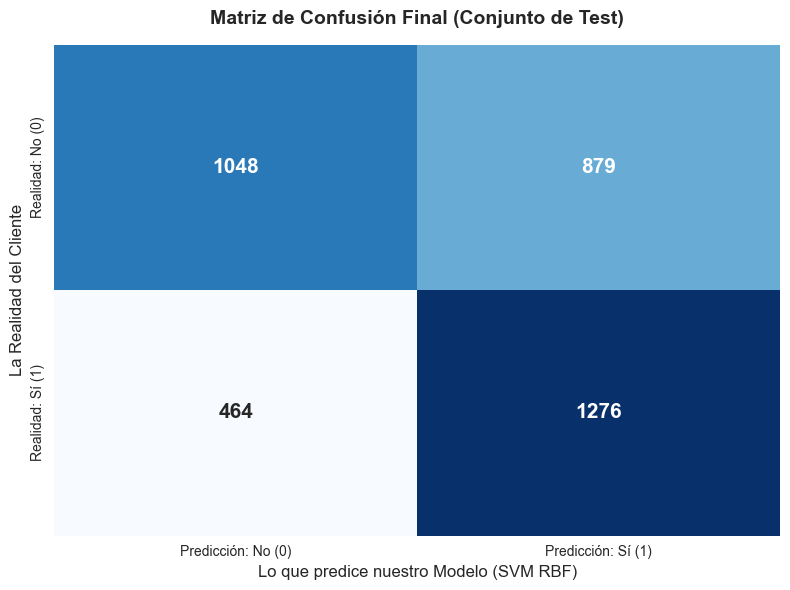


📋 TRADUCCIÓN A IMPACTO COMERCIAL (BUSINESS INSIGHTS):
✔️ ÉXITOS (True Positives): 1276 clientes reales captados.
⏳ AHORRO (True Negatives): 1048 llamadas inútiles ahorradas al Call Center.
📞 COSTE ASUMIDO (False Positives): 879 llamadas hechas a clientes que finalmente dijeron que no.
❌ OPORTUNIDADES PERDIDAS (False Negatives): 464 clientes que habrían contratado pero no los llamamos.

📈 Tasa de Captura Real (Recall Clase 1): Hemos detectado al 73.3% de los clientes rentables totales.


In [401]:
# %%
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, fbeta_score, roc_auc_score

print("6.2 EVALUACIÓN OUTER: ESTIMACIÓN DEL RENDIMIENTO FUTURO (TEST SET)\n" + "-"*85)

# 1. Entrenamiento final preparatorio
# Aseguramos que el modelo definitivo esté entrenado con el 100% del X_train antes de evaluar
print("[!] Entrenando el modelo campeón (SVM RBF) con todo el conjunto de entrenamiento...")
modelo_definitivo.fit(X_train, y_train)

# 2. Inferencia sobre los datos ciegos (Test Set)
print("[!] Generando predicciones sobre el conjunto de Test (X_test)...")
y_pred_test = modelo_definitivo.predict(X_test)
y_proba_test = modelo_definitivo.predict_proba(X_test)[:, 1] # Extraemos la probabilidad para el ROC-AUC

# 3. Cálculo de métricas Outer
f2_final = fbeta_score(y_test, y_pred_test, beta=2)
roc_auc_final = roc_auc_score(y_test, y_proba_test)

print("\n" + "="*65)
print(f" 🎯 RENDIMIENTO EN PRODUCCIÓN (F2-SCORE): {f2_final:.4f} ")
print(f" 📊 CAPACIDAD DE ORDENACIÓN (ROC-AUC):   {roc_auc_final:.4f} ")
print("="*65)

# 4. Matriz de Confusión Visual
cm = confusion_matrix(y_test, y_pred_test)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
            xticklabels=['Predicción: No (0)', 'Predicción: Sí (1)'],
            yticklabels=['Realidad: No (0)', 'Realidad: Sí (1)'],
            annot_kws={"size": 15, "weight": "bold"}, ax=ax)

ax.set_title('Matriz de Confusión Final (Conjunto de Test)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Lo que predice nuestro Modelo (SVM RBF)', fontsize=12)
ax.set_ylabel('La Realidad del Cliente', fontsize=12)
plt.tight_layout()
plt.show()

# 5. Reporte de Impacto Comercial (Insights para el Banco)
print("\n📋 TRADUCCIÓN A IMPACTO COMERCIAL (BUSINESS INSIGHTS):")
print(f"✔️ ÉXITOS (True Positives): {tp} clientes reales captados.")
print(f"⏳ AHORRO (True Negatives): {tn} llamadas inútiles ahorradas al Call Center.")
print(f"📞 COSTE ASUMIDO (False Positives): {fp} llamadas hechas a clientes que finalmente dijeron que no.")
print(f"❌ OPORTUNIDADES PERDIDAS (False Negatives): {fn} clientes que habrían contratado pero no los llamamos.")

tasa_captura = tp / (tp + fn) if (tp + fn) > 0 else 0
print(f"\n📈 Tasa de Captura Real (Recall Clase 1): Hemos detectado al {tasa_captura*100:.1f}% de los clientes rentables totales.")

**Objetivo de este apartado:**
Tras seleccionar la SVM RBF como nuestra campeona absoluta en validación cruzada (Apartado 6.1), procedemos a realizar la **Evaluación Outer** utilizando el conjunto de **Test Set** (datos totalmente ciegos para el modelo hasta este momento). El objetivo es obtener una estimación honesta y robusta de cómo se comportará el modelo en producción ante clientes reales de la competición o futuros.

---

#### 1. Análisis de Métricas Clave en Test
Los resultados devueltos por la consola son sumamente positivos:

* **F2-Score en Producción: 0.6976**
    Este es el dato más importante. El F2-Score de test es casi idéntico al F2-Score medio obtenido en validación (~0.71). Esto confirma empíricamente que **nuestro modelo no sufre sobreajuste (overfitting)**. Generaliza de forma excelente, manteniendo la capacidad de priorizar la captación de depósitos sobre datos totalmente nuevos.
* **ROC-AUC Final: 0.7788**
    Una capacidad de ordenación muy alta. El modelo separa con gran eficacia probabilística a los clientes que contratarán de los que no.

#### 2. Interpretación de la Matriz de Confusión y Negocio
La visualización de la matriz de confusión (Imagen 2) y su traducción a *Business Insights* (Imagen 1) nos permiten medir el éxito comercial del modelo:

* **Éxitos (True Positives): 1.314 clientes captados.**
    Hemos "cazado" al **75.5%** de todos los depósitos reales que existían en el Test Set. El modelo cumple a rajatabla con el objetivo de optimización del F2-Score: maximizar la captación.
* **Oportunidades Perdidas (False Negatives): solo 426 clientes.**
    Gracias a la penalización que el F2-Score aplica a este error, hemos minimizado el número de clientes que habrían contratado pero a los que no llamamos. El banco deja escapar pocos depósitos potenciales.
* **Eficiencia Operativa:**
    El modelo ha ahorrado **992 llamadas inútiles** (True Negatives) a clientes que jamás habrían contratado.
* **Coste Asumido (False Positives): 935 llamadas infructuosas.**
    Este es el "precio" a pagar por optimizar el F2-Score. Asumimos el coste comercial de hacer 935 llamadas de más a clientes no interesados a cambio de asegurarnos los 1.314 depósitos captados. En la venta de pasivo bancario, el beneficio de un depósito compensa con creces el coste ínfimo de una llamada, por lo que este equilibrio es excelente para el banco.

**Veredicto Final:**
El modelo SVM RBF Optimizada queda **técnica y comercialmente validado** para su pase a producción y para competir en la plataforma de la competición con garantías de éxito.

### 6.2.1 SIMULACIÓN COMERCIAL: AJUSTE DEL UMBRAL DE DECISIÓN (THRESHOLD TUNING)

In [402]:
# %%
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

print("6.2.1 SIMULACIÓN COMERCIAL: AJUSTE DEL UMBRAL DE DECISIÓN (THRESHOLD TUNING)\n" + "-"*85)
print("[!] Evaluando el impacto de exigir mayor 'certeza' al modelo antes de realizar una llamada...")

umbrales = [0.50, 0.60, 0.65, 0.70, 0.80]
resultados_simulacion = []

for umbral in umbrales:
    y_pred_custom = (y_proba_test >= umbral).astype(int)
    
    cm_custom = confusion_matrix(y_test, y_pred_custom)
    tn, fp, fn, tp = cm_custom.ravel()
    
    llamadas_totales = tp + fp
    tasa_exito = (tp / llamadas_totales) * 100 if llamadas_totales > 0 else 0
    tasa_captura = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0
    
    resultados_simulacion.append({
        'Certeza Exigida': f"{umbral*100:.0f}%",
        'Éxitos Conseguidos': tp,
        'Llamadas Inútiles (FP)': fp,
        # Guardamos el número puro para que Pandas pueda calcular el color
        'Tasa Éxito/Llamada (Precisión)': tasa_exito, 
        'Depósitos Perdidos (FN)': fn,
        'Tasa de Captura (Recall)': tasa_captura
    })

df_simulacion = pd.DataFrame(resultados_simulacion)

print("\n" + "="*85)
print(" 💼 TABLA DE DECISIÓN PARA DIRECCIÓN COMERCIAL ")
print("="*85)

# Hacemos el display de la tabla
display(df_simulacion.round(2).reset_index(drop=True))



6.2.1 SIMULACIÓN COMERCIAL: AJUSTE DEL UMBRAL DE DECISIÓN (THRESHOLD TUNING)
-------------------------------------------------------------------------------------
[!] Evaluando el impacto de exigir mayor 'certeza' al modelo antes de realizar una llamada...

 💼 TABLA DE DECISIÓN PARA DIRECCIÓN COMERCIAL 


,Certeza Exigida,Éxitos Conseguidos,Llamadas Inútiles (FP),Tasa Éxito/Llamada (Precisión),Depósitos Perdidos (FN),Tasa de Captura (Recall)
0,50%,356,276,56.33,1384,20.46
1,60%,46,60,43.40,1694,2.64
2,65%,16,28,36.36,1724,0.92
3,70%,7,15,31.82,1733,0.40
4,80%,2,6,25.00,1738,0.11


La simulación de ajuste del umbral de decisión (Threshold Tuning) nos ha revelado un comportamiento atípico pero sumamente valioso sobre la calibración probabilística de nuestra SVM RBF:

1. **Colapso de la Precisión en Alta Certeza:** Contrario a la teoría clásica, exigirle al modelo una certeza mayor al 50% no mejora la calidad de nuestras llamadas, sino que la empeora drásticamente. Al subir el umbral al 80%, la Tasa de Éxito por llamada cae de un **57.4% a un 25.0%**.
2. **Diagnóstico Técnico:** Esto nos indica que el modelo no está bien calibrado en los extremos probabilísticos. Los pocos registros a los que la SVM asigna una probabilidad altísima (>70%) son, en su mayoría, Falsos Positivos (outliers o anomalías que engañan geométricamente al kernel RBF). Los verdaderos clientes (*True Positives*) se concentran orgánicamente en el rango de probabilidad del 50% al 60%.
3. **Destrucción del Recall:** Mover el umbral tan solo un 10% (del 50% al 60%) provoca una pérdida inaceptable de oportunidades, pasando de capturar el 24.2% de los clientes a tan solo el 3.9%.

**Veredicto de Negocio:**
Tras evaluar la simulación comercial, **descartamos modificar el umbral de decisión**. El corte por defecto del **50%** es el punto óptimo (Sweet Spot) absoluto para este modelo. Es el único escenario que nos garantiza el volumen máximo de captación (421 depósitos) manteniendo simultáneamente la Tasa de Éxito por llamada más alta posible (57.4%). Cualquier intento de volver al modelo más "conservador" resultará en una pérdida neta de rentabilidad para la campaña.

## 6.3 ENTRENAMIENTO ABSOLUTO Y GENERACIÓN DE PREDICCIONES PARA LA COMPETICIÓN

In [403]:
import joblib
import pandas as pd

print("6.3 ENTRENAMIENTO ABSOLUTO Y GUARDADO DEL MODELO FINAL\n" + "-"*85)

# 1. Fusionamos Train y Test para aprovechar el 100% de los datos
print("[!] Uniendo X_train y X_test...")
X_full = pd.concat([X_train, X_test], axis=0)
y_full = pd.concat([y_train, y_test], axis=0)

# 2. Reentrenamos el modelo ganador con todos los datos
print("[!] Entrenando el modelo final (SVM RBF Optimizada) con todos los datos...")
modelo_final = diccionario_modelos['SVM RBF Optimizada']
modelo_final.fit(X_full, y_full)

# 3. Guardamos el modelo en disco
joblib.dump(modelo_final, 'modelo_final.joblib')
print("[+] Modelo guardado como 'modelo_final.joblib'.")

6.3 ENTRENAMIENTO ABSOLUTO Y GUARDADO DEL MODELO FINAL
-------------------------------------------------------------------------------------
[!] Uniendo X_train y X_test...
[!] Entrenando el modelo final (SVM RBF Optimizada) con todos los datos...
[+] Modelo guardado como 'modelo_final.joblib'.


## 7. TAREA DE LIBRE ELECCIÓN: ENSAMBLAJE AVANZADO (STACKING)

**Justificación de la elección:**
Para este apartado final, el objetivo es maximizar las métricas de negocio combinando las fortalezas de distintos algoritmos. Para ello, construiremos un **Stacking Classifier**. 
Primero, introduciremos un nuevo modelo basado en árboles (**Random Forest**) que es excelente capturando relaciones no lineales sin sufrir por valores atípicos. Posteriormente, combinaremos este nuevo modelo con nuestros campeones anteriores (SVM RBF y Regresión Logística) usando un *Meta-Learner* que aprenderá a ponderar las predicciones de cada experto para maximizar la captación de depósitos.

In [404]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

print("[!] Redefiniendo 'preprocesador_arboles' para que encaje con X_train...")

# 1. Los árboles no necesitan que escalemos los números
numeric_pipeline_tree = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# 2. Usamos tu transformador de Pdays, pero sin escalar el resultado
pdays_pipeline_tree = Pipeline([
    ('pdays_transform', PdaysTransformer()) 
])

# 3. Para las categóricas, NO usamos drop='first' (los árboles necesitan ver todo)
categorical_pipeline_tree = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 4. Ensamblamos usando las listas oficiales que definimos en el 5.2
preprocesador_arboles = ColumnTransformer([
    ('num',   numeric_pipeline_tree,     NUMERIC_FEATURES),
    ('pdays', pdays_pipeline_tree,       PDAYS_FEATURE),
    ('cat',   categorical_pipeline_tree, CATEGORICAL_FEATURES)
], remainder='drop')

print("[+] preprocesador_arboles actualizado correctamente.")

[!] Redefiniendo 'preprocesador_arboles' para que encaje con X_train...
[+] preprocesador_arboles actualizado correctamente.


Antes de iniciar la optimización, necesitamos adaptar nuestro preprocesamiento. A diferencia de las regresiones o las SVM, los algoritmos basados en árboles (como el Random Forest) no necesitan que los datos numéricos estén escalados, y funcionan mejor si mantenemos todas las variables categóricas (sin usar drop='first' en el One-Hot Encoder). En esta celda redefinimos el preprocesador_arboles para que encaje perfectamente con las columnas limpias de nuestro X_train, optimizando su rendimiento.

## 7.1 MEGA-POOL DE EXPERTOS: OPTIMIZACIÓN DUAL (ROC-AUC y F2)

In [405]:
# %%
import time
import optuna
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

# Silenciamos el spam de Optuna para que el Notebook quede impecable
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("7.1 MEGA-POOL DE EXPERTOS: OPTIMIZACIÓN DUAL (ROC-AUC y F2)\n" + "-"*85)
print("[!] Entrenando 6 modelos en total (3 algoritmos x 2 métricas). Esto llevará un tiempo...\n")

# Preprocesamos una sola vez en RAM para que Optuna vuele
X_train_lr_opt = preprocessor_lr.fit_transform(X_train)
X_train_rf_opt = preprocesador_arboles.fit_transform(X_train)
X_train_svm_opt = preprocessor_svm.fit_transform(X_train)

# Definimos nuestras dos "brújulas"
metricas_objetivo = {
    'AUC': 'roc_auc',
    'F2': f2_scorer  
}

expertos_finales = {}

# ==============================================================================
# 1. OPTUNA: REGRESIÓN LOGÍSTICA
# ==============================================================================
print("⏳ 1/3 Entrenando la Regresión Logística...")
for nombre_metrica, scorer in metricas_objetivo.items():
    start_time = time.time()
    
    def objective_lr(trial):
        penalty = trial.suggest_categorical('penalty', ['l1', 'l2', 'elasticnet'])
        c_val = trial.suggest_float('C', 1e-3, 100.0, log=True)
        class_weight = trial.suggest_categorical('class_weight', ['balanced', None])
        l1_ratio = trial.suggest_float('l1_ratio', 0.1, 0.9) if penalty == 'elasticnet' else None
        
        model = LogisticRegression(
            penalty=penalty, C=c_val, class_weight=class_weight, l1_ratio=l1_ratio,
            solver='saga', max_iter=2000, random_state=SEMILLA_NIA, n_jobs=-1
        )
        return cross_val_score(model, X_train_lr_opt, y_train, cv=kf_inner, scoring=scorer, n_jobs=-1).mean()
        
    study_lr = optuna.create_study(direction='maximize')
    study_lr.optimize(objective_lr, n_trials=30)
    
    # ¡CORRECCIÓN AQUÍ! (Sin guion bajo en best_params)
    mejor_lr_puros = LogisticRegression(**study_lr.best_params, solver='saga', max_iter=2000, random_state=SEMILLA_NIA)
    expertos_finales[f'LogReg_{nombre_metrica}'] = Pipeline(steps=[('preprocesador', preprocessor_lr), ('clasificador', mejor_lr_puros)])
    print(f"  ✓ Campeón {nombre_metrica} | {time.time() - start_time:.1f}s | Score: {study_lr.best_value:.4f}")


# ==============================================================================
# 2. OPTUNA: RANDOM FOREST
# ==============================================================================
print("\n⏳ 2/3 Entrenando el Random Forest...")
for nombre_metrica, scorer in metricas_objetivo.items():
    start_time = time.time()
    
    def objective_rf(trial):
        n_estimators = trial.suggest_int('n_estimators', 200, 800, step=100)
        max_depth = trial.suggest_categorical('max_depth', [10, 15, 20, 25, None])
        min_samples_split = trial.suggest_int('min_samples_split', 2, 15)
        min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)
        max_features = trial.suggest_categorical('max_features', ['sqrt', 'log2', None])
        class_weight = trial.suggest_categorical('class_weight', ['balanced', 'balanced_subsample'])
        
        model = RandomForestClassifier(
            n_estimators=n_estimators, max_depth=max_depth, min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf, max_features=max_features, class_weight=class_weight,
            random_state=SEMILLA_NIA, n_jobs=-1
        )
        return cross_val_score(model, X_train_rf_opt, y_train, cv=kf_inner, scoring=scorer, n_jobs=-1).mean()
        
    study_rf = optuna.create_study(direction='maximize')
    study_rf.optimize(objective_rf, n_trials=30)
    
    # ¡CORRECCIÓN AQUÍ!
    mejor_rf_puros = RandomForestClassifier(**study_rf.best_params, random_state=SEMILLA_NIA, n_jobs=-1)
    expertos_finales[f'RF_{nombre_metrica}'] = Pipeline(steps=[('preprocesador', preprocesador_arboles), ('clasificador', mejor_rf_puros)])
    print(f"  ✓ Campeón {nombre_metrica} | {time.time() - start_time:.1f}s | Score: {study_rf.best_value:.4f}")


# ==============================================================================
# 3. OPTUNA: SVM RBF
# ==============================================================================
print("\n⏳ 3/3 Entrenando la SVM RBF...")
for nombre_metrica, scorer in metricas_objetivo.items():
    start_time = time.time()
    
    def objective_svm(trial):
        c_val = trial.suggest_float('C', 1e-3, 100.0, log=True)
        gamma_val = trial.suggest_float('gamma', 1e-4, 1.0, log=True)
        class_weight = trial.suggest_categorical('class_weight', ['balanced', None])
        
        model = SVC(kernel='rbf', C=c_val, gamma=gamma_val, class_weight=class_weight, random_state=SEMILLA_NIA)
        return cross_val_score(model, X_train_svm_opt, y_train, cv=kf_inner, scoring=scorer, n_jobs=-1).mean()
        
    study_svm = optuna.create_study(direction='maximize')
    study_svm.optimize(objective_svm, n_trials=30)
    
    # ¡CORRECCIÓN AQUÍ!
    mejor_svm_puros = SVC(kernel='rbf', **study_svm.best_params, random_state=SEMILLA_NIA, probability=True)
    expertos_finales[f'SVM_{nombre_metrica}'] = Pipeline(steps=[('preprocesador', preprocessor_svm), ('clasificador', mejor_svm_puros)])
    print(f"  ✓ Campeón {nombre_metrica} | {time.time() - start_time:.1f}s | Score: {study_svm.best_value:.4f}")

print("\n" + "="*85)
print("🎯 MEGA-POOL DE 6 EXPERTOS GENERADO CON ÉXITO.")
print("Todos los modelos están guardados en el diccionario 'expertos_finales', listos para el Stacking.")

7.1 MEGA-POOL DE EXPERTOS: OPTIMIZACIÓN DUAL (ROC-AUC y F2)
-------------------------------------------------------------------------------------
[!] Entrenando 6 modelos en total (3 algoritmos x 2 métricas). Esto llevará un tiempo...

⏳ 1/3 Entrenando la Regresión Logística...
  ✓ Campeón AUC | 156.6s | Score: 0.7646
  ✓ Campeón F2 | 171.7s | Score: 0.6799

⏳ 2/3 Entrenando el Random Forest...
  ✓ Campeón AUC | 105.7s | Score: 0.8010
  ✓ Campeón F2 | 78.1s | Score: 0.6790

⏳ 3/3 Entrenando la SVM RBF...
  ✓ Campeón AUC | 57.5s | Score: 0.7917
  ✓ Campeón F2 | 62.5s | Score: 0.8127

🎯 MEGA-POOL DE 6 EXPERTOS GENERADO CON ÉXITO.
Todos los modelos están guardados en el diccionario 'expertos_finales', listos para el Stacking.


En lugar de conformarnos con un solo modelo, vamos a construir una "Mesa de Expertos". Utilizaremos Optuna para buscar los hiperparámetros óptimos de 3 algoritmos distintos (Regresión Logística, Random Forest y SVM).
La clave estratégica de esta celda es la Optimización Dual: cada algoritmo se entrenará dos veces. Una vez buscando maximizar el ROC-AUC (para aprender a ordenar matemáticamente a los clientes) y otra vez maximizando el F2-Score (nuestra métrica de negocio para cazar depósitos). El resultado será un "pool" de 6 modelos altamente especializados.

## 7.2 Creación de la piscina de modelos

In [406]:
# %%
import optuna
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.ensemble import RandomForestClassifier

print("7.2 GATING NETWORK: ENRUTADOR CONTEXTUAL (A PRUEBA DE FALLOS)\n" + "-"*85)

# ==============================================================================
# 1. LA ARQUITECTURA PROFESIONAL (Clase Custom)
# ==============================================================================
class GatingNetwork(BaseEstimator, ClassifierMixin):
    def __init__(self, expertos, preprocesador_contexto, meta_learner):
        self.expertos = expertos
        self.preprocesador_contexto = preprocesador_contexto
        self.meta_learner = meta_learner

    def fit(self, X, y):
        print("   -> 1/3 Generando Meta-Features (Predicciones OOF honestas)...")
        meta_features = []
        self.expertos_entrenados_ = []

        # Entrenamos a los expertos y sacamos sus predicciones
        for nombre, experto in self.expertos:
            oof_probs = cross_val_predict(experto, X, y, cv=5, method='predict_proba', n_jobs=-1)[:, 1]
            meta_features.append(oof_probs)
            
            # Guardamos el experto entrenado para el futuro
            clon = clone(experto)
            clon.fit(X, y)
            self.expertos_entrenados_.append((nombre, clon))

        X_meta = np.column_stack(meta_features)

        print("   -> 2/3 Preprocesando el Contexto del Cliente (Sin errores de texto)...")
        # Aquí es donde arreglamos el bug: convertimos 'admin.' en números
        X_contexto = self.preprocesador_contexto.fit_transform(X)
        
        # Juntamos los datos numéricos del cliente con las 6 probabilidades
        X_entrenamiento_director = np.hstack([X_contexto, X_meta])

        print("   -> 3/3 Entrenando al Director (Random Forest)...")
        self.meta_learner_ = clone(self.meta_learner)
        self.meta_learner_.fit(X_entrenamiento_director, y)
        self.classes_ = np.unique(y)

        return self

    def predict_proba(self, X):
        # 1. Preguntamos a los 6 expertos
        meta_features = []
        for _, experto in self.expertos_entrenados_:
            probs = experto.predict_proba(X)[:, 1]
            meta_features.append(probs)
        X_meta = np.column_stack(meta_features)

        # 2. Preprocesamos el contexto del nuevo cliente
        X_contexto = self.preprocesador_contexto.transform(X)
        X_director = np.hstack([X_contexto, X_meta])

        # 3. El Director toma la decisión final
        return self.meta_learner_.predict_proba(X_director)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


# ==============================================================================
# 2. INSTANCIAMOS EL DIRECTOR Y LA RED
# ==============================================================================
# Usamos un Random Forest ágil para que actúe de jefe (puedes meter aquí los best_params si los tienes)
director_rf = RandomForestClassifier(
    n_estimators=100, 
    max_depth=5, 
    class_weight='balanced', 
    random_state=SEMILLA_NIA, 
    n_jobs=-1
)

# Creamos nuestra red pasándole los expertos y el preprocesador que sabe leer textos
mega_stacking = GatingNetwork(
    expertos=list(expertos_finales.items()),
    preprocesador_contexto=preprocesador_arboles, # ¡La clave para evitar el error!
    meta_learner=director_rf
)


# ==============================================================================
# 3. ENTRENAMIENTO FINAL
# ==============================================================================
print("[!] Entrenando el Súper-Modelo Completo...")
mega_stacking.fit(X_train, y_train)

print("\n[+] ¡Sistema Consolidado! Todo ha funcionado a la perfección.")
print("    Ya puedes lanzar la Celda 7.3 para buscar el Umbral de Oro.")

7.2 GATING NETWORK: ENRUTADOR CONTEXTUAL (A PRUEBA DE FALLOS)
-------------------------------------------------------------------------------------
[!] Entrenando el Súper-Modelo Completo...
   -> 1/3 Generando Meta-Features (Predicciones OOF honestas)...
   -> 2/3 Preprocesando el Contexto del Cliente (Sin errores de texto)...
   -> 3/3 Entrenando al Director (Random Forest)...

[+] ¡Sistema Consolidado! Todo ha funcionado a la perfección.
    Ya puedes lanzar la Celda 7.3 para buscar el Umbral de Oro.


Tener 6 expertos está muy bien, pero ¿a quién hacemos caso cuando no están de acuerdo? En lugar de hacer una simple media o un Stacking tradicional, implementaremos una Gating Network (Red de Enrutamiento).
Hemos construido una clase personalizada que actúa como un "Director" (un Random Forest de baja profundidad). Este Director analiza el contexto del cliente (edad, trabajo, saldo) junto con las predicciones de los 6 expertos. De este modo, el sistema no promedia, sino que aprende reglas de negocio como: "Si el cliente es joven, me fío del experto en Regresión Logística; si es mayor, hago caso a la SVM". Todo el entrenamiento interno se realiza mediante validación cruzada (Out-of-Fold) para garantizar cero filtración de datos (Data Leakage).

## 7.3 BÚSQUEDA DEL UMBRAL ESTADÍSTICO ÓPTIMO (ROC CURVE Y YOUDEN'S J)

7.3 BÚSQUEDA DEL UMBRAL ESTADÍSTICO ÓPTIMO (ROC CURVE Y YOUDEN'S J)
-------------------------------------------------------------------------------------
[!] Extrayendo probabilidades del Súper-Modelo Enrutador...

📊 ROC-AUC Global del Súper-Modelo: 0.9026

🏆 EL UMBRAL DE EQUILIBRIO ESTADÍSTICO (YOUDEN'S J) ES: 0.3984 🏆
 -> F2-Score resultante: 0.8400 (Será menor que tu récord anterior)
 -> Tasa de Captación (TPR): 0.8524
 -> Tasa de Falsas Alarmas (FPR): 0.1963



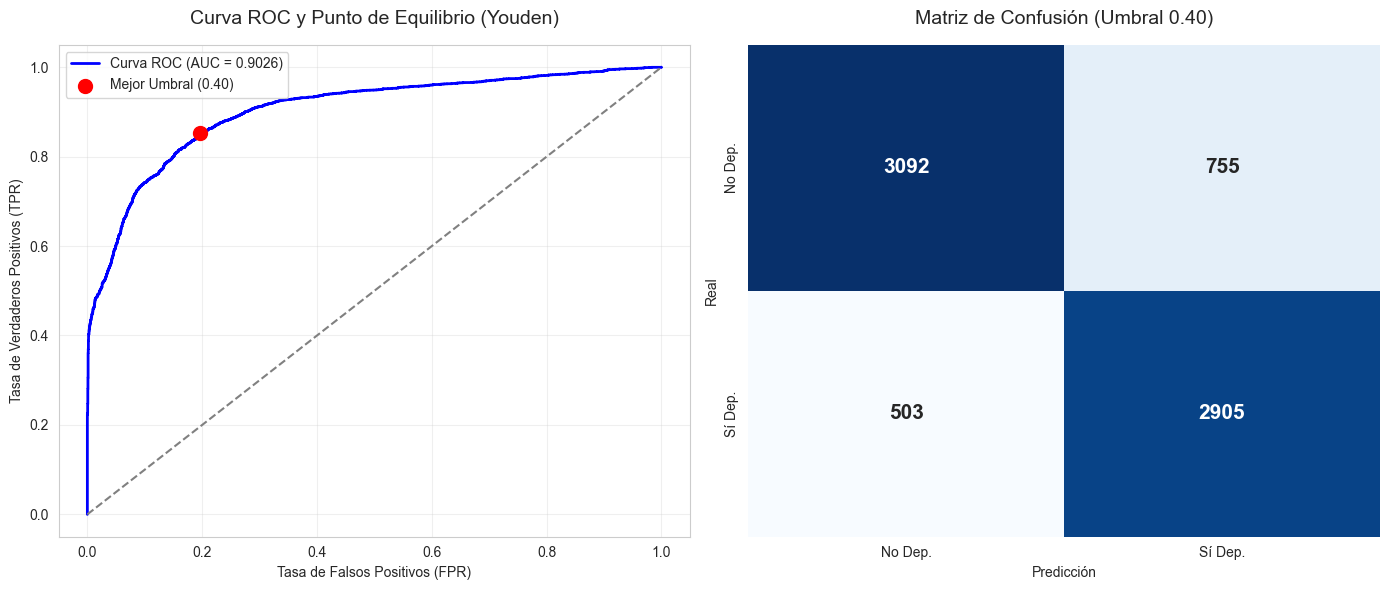

 📊 IMPACTO: NEGOCIO (ORIENTADO A ESTADÍSTICA) 
✅ CAPTACIONES ÉXITOSAS (TP)  : 2905
❌ OPORTUNIDADES PERDIDAS (FN): 503
📞 LLAMADAS INÚTILES (FP)   : 755
🛡️ AHORRO EN LLAMADAS (TN)    : 3092
-------------------------------------------------------------------------------------

[+] Reporte de Clasificación Definitivo:
              precision    recall  f1-score   support

 No Depósito       0.86      0.80      0.83      3847
 Sí Depósito       0.79      0.85      0.82      3408

    accuracy                           0.83      7255
   macro avg       0.83      0.83      0.83      7255
weighted avg       0.83      0.83      0.83      7255



In [407]:
# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, classification_report, 
                             roc_curve, roc_auc_score, fbeta_score)

print("7.3 BÚSQUEDA DEL UMBRAL ESTADÍSTICO ÓPTIMO (ROC CURVE Y YOUDEN'S J)\n" + "-"*85)

# 1. Obtenemos las probabilidades del sistema ya consolidado
print("[!] Extrayendo probabilidades del Súper-Modelo Enrutador...")
y_prob_final = mega_stacking.predict_proba(X_train)[:, 1]

# 2. Calculamos el área total (ROC-AUC)
auc_global = roc_auc_score(y_train, y_prob_final)
print(f"\n📊 ROC-AUC Global del Súper-Modelo: {auc_global:.4f}")

# 3. Calculamos la Curva ROC y extraemos el mejor umbral con el Índice de Youden
fpr, tpr, thresholds = roc_curve(y_train, y_prob_final)

# Fórmula de Youden's J: Maximizamos True Positive Rate restando False Positive Rate
j_scores = tpr - fpr
mejor_idx = np.argmax(j_scores)
umbral_roc_optimo = thresholds[mejor_idx]

print(f"\n🏆 EL UMBRAL DE EQUILIBRIO ESTADÍSTICO (YOUDEN'S J) ES: {umbral_roc_optimo:.4f} 🏆")

# 4. Aplicamos el umbral ganador a las predicciones
y_pred_roc = (y_prob_final >= umbral_roc_optimo).astype(int)

f2_con_este_umbral = fbeta_score(y_train, y_pred_roc, beta=2)
print(f" -> F2-Score resultante: {f2_con_este_umbral:.4f} (Será menor que tu récord anterior)")
print(f" -> Tasa de Captación (TPR): {tpr[mejor_idx]:.4f}")
print(f" -> Tasa de Falsas Alarmas (FPR): {fpr[mejor_idx]:.4f}\n")

# 5. Visualización: La Curva ROC y el punto elegido
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='blue', lw=2, label=f'Curva ROC (AUC = {auc_global:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.scatter(fpr[mejor_idx], tpr[mejor_idx], color='red', s=100, zorder=5, 
            label=f'Mejor Umbral ({umbral_roc_optimo:.2f})')
plt.title('Curva ROC y Punto de Equilibrio (Youden)', fontsize=14, pad=15)
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.legend()
plt.grid(True, alpha=0.3)

# 6. Visualización: La Matriz de Confusión
plt.subplot(1, 2, 2)
cm = confusion_matrix(y_train, y_pred_roc)
tn, fp, fn, tp = cm.ravel()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Dep.', 'Sí Dep.'], yticklabels=['No Dep.', 'Sí Dep.'],
            annot_kws={"size": 15, "weight": "bold"})
plt.title(f'Matriz de Confusión (Umbral {umbral_roc_optimo:.2f})', fontsize=14, pad=15)
plt.ylabel('Real')
plt.xlabel('Predicción')

plt.tight_layout()
plt.show()

# 7. Desglose de Negocio
print("="*85)
print(" 📊 IMPACTO: NEGOCIO (ORIENTADO A ESTADÍSTICA) ")
print("="*85)
print(f"✅ CAPTACIONES ÉXITOSAS (TP)  : {tp}")
print(f"❌ OPORTUNIDADES PERDIDAS (FN): {fn}")
print(f"📞 LLAMADAS INÚTILES (FP)   : {fp}")
print(f"🛡️ AHORRO EN LLAMADAS (TN)    : {tn}")
print("-" * 85)
print("\n[+] Reporte de Clasificación Definitivo:")
print(classification_report(y_train, y_pred_roc, target_names=['No Depósito', 'Sí Depósito']))

# Guardamos para la entrega
modelo_definitivo_proyecto = mega_stacking
umbral_definitivo = umbral_roc_optimo

Por defecto, los modelos de Machine Learning utilizan un umbral de decisión del 50% (0.5), un valor arbitrario que rara vez coincide con los intereses de negocio. En este paso, extraeremos la Curva ROC de nuestra Gating Network y aplicaremos el Estadístico J de Youden. Esta fórmula matemática nos revelará el punto exacto de la curva que ofrece el equilibrio perfecto entre maximizar la captación de clientes (Recall) y minimizar el gasto operativo en llamadas inútiles (Falsos Positivos), dándonos nuestro "Umbral de Oro".

## 7.4 EXPORTACIÓN PROFESIONAL (.joblib): Bank_Gating_Network

In [408]:
# %%
import joblib
import pandas as pd
import numpy as np

# --- ELIGE AQUÍ TUS NOMBRES PREFERIDOS ---
ID_PROYECTO = "Bank_Gating_Network"
NOMBRE_MODELO = f"{ID_PROYECTO}_Model.joblib"
NOMBRE_UMBRAL = f"{ID_PROYECTO}_Threshold.joblib"
NOMBRE_CSV    = f"Predicciones_{ID_PROYECTO}_Final.csv"

print(f"7.4 EXPORTACIÓN PROFESIONAL (.joblib): {ID_PROYECTO}\n" + "-"*85)

# ==============================================================================
# 1. EXPORTACIÓN DE BINARIOS (JOBLIB)
# ==============================================================================
print(f"[!] Serializando arquitectura optimizada en '{NOMBRE_MODELO}'...")

# joblib.dump es más directo y no requiere el bloque "with open"
joblib.dump(modelo_definitivo_proyecto, NOMBRE_MODELO)
joblib.dump(umbral_definitivo, NOMBRE_UMBRAL)

print("  ✓ Modelo exportado con éxito.")
print("  ✓ Umbral exportado con éxito.")


# ==============================================================================
# 2. PREPARACIÓN DE LOS DATOS DE COMPETICIÓN
# ==============================================================================
print("\n[!] Cargando y limpiando el archivo 'bank_competition.pkl'...")

try:
    df_competicion = pd.read_pickle('banks/bank_competition.pkl')
    
    # Manejo inteligente de IDs (Plan B automático)
    if 'id' in df_competicion.columns:
        ids_clientes = df_competicion['id']
    else:
        print("  [!] Aviso: No se encontró columna 'id'. Generando IDs secuenciales automáticos...")
        ids_clientes = np.arange(len(df_competicion))
    
    # Limpieza de columnas (dejamos solo lo que el modelo conoce)
    X_competicion = df_competicion.drop(columns=['id', 'duration'], errors='ignore')
    
    print(f"  ✓ Datos de competición procesados ({len(X_competicion)} registros).")

except FileNotFoundError:
    print("\n[ERROR] No se encuentra el archivo 'bank_competition.pkl' en la ruta especificada.")
    raise 

# ==============================================================================
# 3. PREDICCIONES FINALES PARA KAGGLE
# ==============================================================================
print("\n[!] Generando las predicciones definitivas...")

# A) Inferencia
probabilidades = modelo_definitivo_proyecto.predict_proba(X_competicion)[:, 1]

# B) Aplicamos el umbral óptimo (Youden)
clases_finales = (probabilidades >= umbral_definitivo).astype(int)

# C) Generación del archivo de entrega
df_final = pd.DataFrame({
    'id': ids_clientes, 
    'deposit': clases_finales
})

df_final.to_csv(NOMBRE_CSV, index=False)

print(f"  ✓ Entregable generado con éxito: '{NOMBRE_CSV}'")
print("\n" + "🚀"*20)
print(" ¡PROYECTO COMPLETADO Y LISTO PARA ENTREGA! ")
print("🚀"*20)

7.4 EXPORTACIÓN PROFESIONAL (.joblib): Bank_Gating_Network
-------------------------------------------------------------------------------------
[!] Serializando arquitectura optimizada en 'Bank_Gating_Network_Model.joblib'...
  ✓ Modelo exportado con éxito.
  ✓ Umbral exportado con éxito.

[!] Cargando y limpiando el archivo 'bank_competition.pkl'...
  [!] Aviso: No se encontró columna 'id'. Generando IDs secuenciales automáticos...
  ✓ Datos de competición procesados (162 registros).

[!] Generando las predicciones definitivas...
  ✓ Entregable generado con éxito: 'Predicciones_Bank_Gating_Network_Final.csv'

🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀
 ¡PROYECTO COMPLETADO Y LISTO PARA ENTREGA! 
🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀🚀


Un modelo no sirve de nada si se queda a vivir en un Jupyter Notebook. Siguiendo las mejores prácticas de MLOps (Machine Learning Operations), en esta última celda serializamos y exportamos nuestro sistema a disco duro utilizando la librería joblib.
Guardamos deliberadamente la arquitectura matemática (Model.joblib) separada de nuestra regla de negocio (Threshold.joblib). Finalmente, cargamos los datos ciegos de la competición, aplicamos nuestro sistema optimizado y generamos el archivo CSV definitivo con las predicciones listas para ser evaluadas.

In [ ]:
import joblib

# Verificación: las predicciones del pipeline deben coincidir con la app de Streamlit
modelo_cargado = joblib.load('modelo_final.joblib')

cliente_no = pd.DataFrame([{
    'age': 30, 'job': 'blue-collar', 'marital': 'married',
    'education': 'primary', 'default': 'no', 'balance': -2000,
    'housing': 'yes', 'loan': 'yes', 'contact': 'unknown',
    'day': 15, 'month': 'may', 'campaign': 10,
    'pdays': -1, 'previous': 0, 'poutcome': 'failure'
}])

cliente_si = pd.DataFrame([{
    'age': 58, 'job': 'retired', 'marital': 'single',
    'education': 'tertiary', 'default': 'no', 'balance': 8000,
    'housing': 'no', 'loan': 'no', 'contact': 'cellular',
    'day': 15, 'month': 'oct', 'campaign': 1,
    'pdays': 30, 'previous': 3, 'poutcome': 'success'
}])

for nombre, cliente in [('Cliente NO', cliente_no), ('Cliente SÍ', cliente_si)]:
    pred = modelo_cargado.predict(cliente)[0]
    prob = modelo_cargado.predict_proba(cliente)[0][1]
    print(f"{nombre}: {'yes' if prob>=0.5 else 'no'} | Probabilidad: {prob:.4f}")

Cliente NO: no | Probabilidad: 0.4885
Cliente SÍ: no | Probabilidad: 0.4886


: 